# 06 · Multiple Linear Regression: Vectorization, Feature Scaling & Gradient-Descent Variants
*AI Foundations · Notebook 06 of 19*

Real outcomes rarely depend on a single input. The sales of a product depend on several
advertising channels at once, and tomorrow's price of an asset might depend on many recent movements.
In this notebook you upgrade linear regression from one feature to **many**, and along the way you
learn three engineering skills that every later model in this course relies on: writing the math
and the code with vectors and matrices (**vectorization**), putting features on comparable scales
(**feature scaling**), and choosing how much data to use per gradient step (**stochastic, mini-batch
and batch gradient descent**). We finish with a case study on daily Bitcoin prices that shows how a
model can score $R^2 = 0.9999$ while forecasting nothing at all, and how to evaluate it honestly.

**What you will learn**
- How to train a 3-feature linear model with per-sample stochastic gradient descent (SGD) using only
  scalar arithmetic, and why it struggles on raw, unscaled data.
- How to write predictions, losses and gradients with a **design matrix**: the shape of every quantity,
  per-sample / mini-batch / full-batch gradients, gradient checking, and the `(m,1)`-vs-`(m,)` trap.
- Min-max, z-score (population vs sample standard deviation) and robust scaling, plus inverse transforms,
  fitting scalers on the training set only, and converting coefficients back to original units.
- **Why** scaling speeds up gradient descent (Hessian, condition number, the $2/\lambda_{\max}$
  learning-rate limit), and a silent scaling bug that uses one global statistic for all columns.
- How SGD, mini-batch and batch gradient descent behave (reshuffling, batch size, learning rate, noise
  floors) and how they compare with the exact least-squares solution and scikit-learn.
- Regression metrics (MSE, RMSE, MAE, MAPE, $R^2$, adjusted $R^2$): what each measures and when each misleads.
- Residual analysis and **interaction features** (the TV × Radio synergy).
- Building daily candles from ~7.8 million one-minute candles **out-of-core**, and a leakage-free
  forecasting workflow for time series (chronological splits, persistence baseline, `TimeSeriesSplit`).

**Prerequisites:** one-feature linear regression trained with gradient descent, derivatives and the
chain rule, NumPy arrays, pandas DataFrames, matplotlib basics, and matrix–vector multiplication.
**Estimated time:** ~5 h.

**How to use this notebook:** run cells top to bottom (Runtime → Run all works).
Exercises are marked ✏️, and each has an automatic checker and a hidden solution
(click "Solution" to expand). Quick-check questions have hidden answers.

**Contents**
1. Three features, one sample at a time
2. From scalars to vectors and matrices
3. Feature scaling
4. Gradient-descent variants on the advertising data
5. Measuring regression quality
6. The advertising model, interpreted: coefficients, residuals and an interaction
7. Case study: daily Bitcoin prices and honest evaluation
8. Quiz
9. Summary and going further

In [1]:
# --- Setup: imports, reproducibility, plotting style, small helpers ---
import importlib
import random
import shutil
import subprocess
import sys
import time
import timeit
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)                 # legacy global seed, for libraries that still use it
rng = np.random.default_rng(SEED)    # our own generator: we pass generators around explicitly

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 110)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)


def ensure(pkg: str, import_name: str | None = None):
    """Import a package, installing it with pip first if it is missing."""
    name = import_name or pkg
    try:
        return importlib.import_module(name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        return importlib.import_module(name)


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")


def download(url: str, dest: Path, timeout: float = 60) -> bool:
    """Download `url` to `dest` unless the file already exists. Return True if the file is available."""
    if dest.exists() and dest.stat().st_size > 0:
        return True
    tmp = dest.with_name(dest.name + ".part")      # write to a temporary name, rename when complete
    try:
        with urllib.request.urlopen(url, timeout=timeout) as resp, open(tmp, "wb") as f:
            shutil.copyfileobj(resp, f, length=1 << 20)
        tmp.replace(dest)
        return True
    except Exception as err:                        # no internet, firewall, timeout, ...
        print(f"Could not download {url}\n  ({type(err).__name__}: {err})")
        tmp.unlink(missing_ok=True)
        return False


print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

Python 3.13.15 | numpy 2.5.3 | pandas 2.3.3 | scikit-learn 1.9.1 | matplotlib 3.11.2


---
## 1. Three features, one sample at a time

### 1.1 The advertising problem

Imagine you are the marketing analyst for a product sold in 200 different markets (cities). In each
market the company spent some budget on **TV**, **Radio** and **Newspaper** advertising (in thousands
of dollars), and then observed **Sales** (in thousands of units). Your boss asks two questions:

1. *Prediction:* if we plan a budget of (TV, Radio, Newspaper) in a new market, how much will we sell?
2. *Interpretation:* which channel is worth the money?

This is the classic **Advertising** dataset from the textbook *An Introduction to Statistical
Learning*. It is small (200 rows), so every experiment runs instantly, which makes it perfect for studying the
*mechanics* of training. We download it once and cache it in `data/`, and if the download fails, the
notebook falls back to a clearly announced synthetic stand-in so that everything still runs.

In [2]:
ADV_URL = "https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv"
ADV_PATH = DATA_DIR / "Advertising.csv"


def make_synthetic_advertising(n: int = 200, seed: int = SEED) -> pd.DataFrame:
    """Offline stand-in with the same columns and a similar structure (used only if the download fails)."""
    g = np.random.default_rng(seed)
    tv = g.uniform(1, 300, n)
    radio = g.uniform(0, 50, n)
    news = np.clip(0.4 * radio + g.gamma(2.0, 10.0, n), 0.3, 115)
    sales = 6.0 + 0.02 * tv + 0.03 * radio + 0.0011 * tv * radio - 0.00002 * tv**2 + g.normal(0, 0.7, n)
    return pd.DataFrame({"TV": tv, "Radio": radio, "Newspaper": news, "Sales": sales}).round(1)


if download(ADV_URL, ADV_PATH):
    adv = pd.read_csv(ADV_PATH, index_col=0)      # column 0 is an unnamed row counter, not a feature
    print("Loaded the real Advertising data.")
else:
    adv = make_synthetic_advertising()
    print("WARNING: using a SYNTHETIC stand-in for the Advertising data, so numbers in the text will differ.")
print("shape:", adv.shape)
display(adv.head())

Loaded the real Advertising data.
shape: (200, 4)


,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


> **Common pitfall.** The first column of this CSV has an *empty header*: it is just a row counter
> (1, 2, 3, ...). If you read the file without `index_col=0`, pandas invents a column called
> `Unnamed: 0`, and a careless `df.drop(columns="Sales")` would happily feed the row number to your
> model as a "feature". Always look at the columns you get:

In [3]:
print("without index_col:", list(pd.read_csv(ADV_PATH).columns) if ADV_PATH.exists() else "(file not available)")
print("with index_col=0: ", list(adv.columns))

without index_col: ['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']
with index_col=0:  ['TV', 'Radio', 'Newspaper', 'Sales']


Before doing anything else we lock away a **test set**: 40 randomly chosen markets that we will not
look at until Section 6. All training, plotting and scaling decisions use the other 160 markets only.
A *random* split is fine here because the markets are independent of each other (there is no time
order). In Section 7 you will see data where a random split is a serious mistake.

In [4]:
from sklearn.model_selection import train_test_split

FEATURES = ["TV", "Radio", "Newspaper"]
TARGET = "Sales"
adv_train, adv_test = train_test_split(adv, test_size=0.2, random_state=SEED)

X_train_raw = adv_train[FEATURES].to_numpy()   # shape (160, 3): one row per market
y_train = adv_train[TARGET].to_numpy()         # shape (160,)
X_test_raw = adv_test[FEATURES].to_numpy()     # shape (40, 3)
y_test = adv_test[TARGET].to_numpy()           # shape (40,)
print("train:", X_train_raw.shape, y_train.shape, "| test:", X_test_raw.shape, y_test.shape)

train: (160, 3) (160,) | test: (40, 3) (40,)


### 1.2 A first look at the data (training set only)

Exploratory data analysis (EDA) answers three questions before any modeling: *what are the ranges
of the features?*, *how does the target relate to each feature?*, and *how do the features relate
to each other?*

,mean,std,min,max
TV,150.02,84.42,0.7,296.4
Radio,22.88,14.81,0.0,49.6
Newspaper,29.95,20.34,0.3,100.9
Sales,14.10,5.11,1.6,27.0


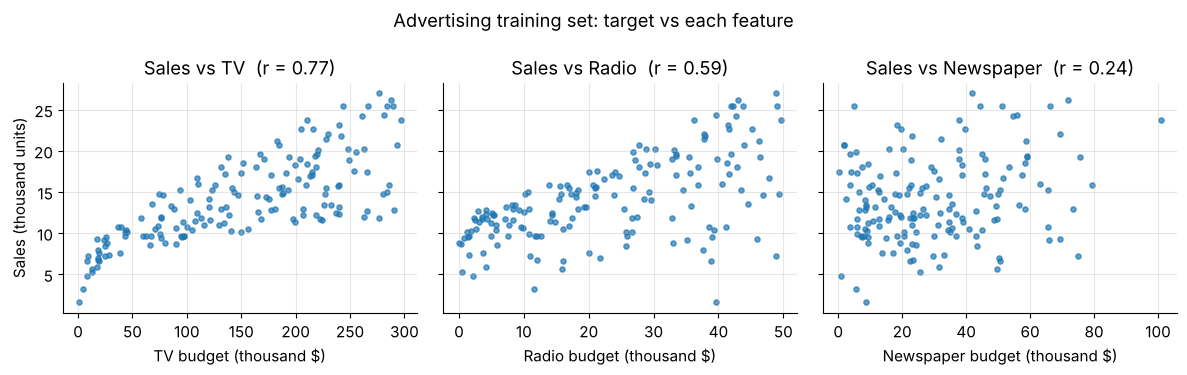

Correlation matrix (training set):


,TV,Radio,Newspaper,Sales
TV,1.000,0.054,0.019,0.769
Radio,0.054,1.000,0.388,0.592
Newspaper,0.019,0.388,1.000,0.238
Sales,0.769,0.592,0.238,1.000


In [5]:
display(adv_train.describe().T[["mean", "std", "min", "max"]].round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, col in zip(axes, FEATURES):
    r = np.corrcoef(adv_train[col], adv_train[TARGET])[0, 1]
    ax.scatter(adv_train[col], adv_train[TARGET], s=14, alpha=0.7)
    ax.set_xlabel(f"{col} budget (thousand $)")
    ax.set_title(f"Sales vs {col}  (r = {r:.2f})")
axes[0].set_ylabel("Sales (thousand units)")
fig.suptitle("Advertising training set: target vs each feature")
fig.tight_layout()
plt.show()

print("Correlation matrix (training set):")
display(adv_train.corr().round(3))

What the EDA tells us:

* **Ranges differ a lot.** TV budgets go up to about 300, Radio only to about 50, Newspaper to about
  100. Keep this in mind, as it will cause trouble in Section 1.5.
* **TV** has the strongest linear association with Sales ($r \approx 0.77$). The cloud is also
  slightly *curved* and *fans out* (more spread at high TV budgets): a hint that a straight line will
  not capture everything.
* **Radio** has a moderate association ($r \approx 0.59$), **Newspaper** a weak one ($r \approx 0.24$).
* Radio and Newspaper are correlated with *each other* ($r \approx 0.39$): markets that spend on radio
  also tend to spend on newspapers. Remember this when we interpret coefficients in Section 6: part of
  Newspaper's apparent association with Sales may really be Radio's.

### 1.3 The model and the loss for one sample

With three features, the linear model predicts

$$
\hat y = w_1 x_1 + w_2 x_2 + w_3 x_3 + b,
$$

where $x_1, x_2, x_3$ are the TV, Radio and Newspaper budgets of one market, $w_1, w_2, w_3$ are
**weights** (how many extra units of sales one extra unit of budget buys, holding the other channels
fixed) and $b$ is the **bias** or intercept (predicted sales with zero advertising). Geometrically,
the model is a flat **hyperplane** in 4-D space instead of a line in 2-D.

For a single training sample $(x_1, x_2, x_3, y)$ we measure the mistake with the **squared error**

$$
L = (\hat y - y)^2 .
$$

*Why squared?* It is never negative, it is zero only for a perfect prediction, it punishes big
mistakes much more than small ones, and it is smooth (differentiable everywhere), so gradients exist.
For a linear model it also makes the total loss a **convex bowl** with a single minimum, and
minimizing it gives the *conditional mean* of $y$, which is exactly the right target if the noise is
Gaussian. (Section 5 discusses alternatives such as absolute error.)

**Gradients by the chain rule.** The loss depends on a parameter only through $\hat y$:

$$
\frac{\partial L}{\partial w_j} = \underbrace{\frac{\partial L}{\partial \hat y}}_{2(\hat y - y)}
\cdot \underbrace{\frac{\partial \hat y}{\partial w_j}}_{x_j} = 2(\hat y - y)\,x_j ,
\qquad
\frac{\partial L}{\partial b} = 2(\hat y - y)\cdot 1 = 2(\hat y - y).
$$

Read this as **error signal × input**. The error $e = \hat y - y$ says *how wrong and in which
direction*, and the input $x_j$ says *how much weight $w_j$ contributed to that mistake*. If the model
predicted too much ($e > 0$) and $x_j > 0$, the gradient is positive and gradient descent lowers
$w_j$. Notice also that **features with large values produce large gradient components**, a fact
that will haunt us in a moment. The bias behaves like a weight whose feature is always $1$.

**SGD update** with learning rate $\eta > 0$ (one sample at a time):

$$
w_j \leftarrow w_j - \eta\,\frac{\partial L}{\partial w_j}\quad (j = 1,2,3), \qquad
b \leftarrow b - \eta\,\frac{\partial L}{\partial b}.
$$

The minus sign is the whole idea: the gradient points *uphill* (direction of fastest increase of
$L$), so we step the opposite way. The training loop is:

```
initialize w1, w2, w3, b
repeat for each epoch:
    for each training sample (x1, x2, x3, y):
        y_hat = w1*x1 + w2*x2 + w3*x3 + b        # 1) predict
        L     = (y_hat - y)**2                    # 2) loss (for monitoring)
        g_j   = 2*(y_hat - y)*x_j ; g_b = 2*(y_hat - y)   # 3) gradients
        w_j  -= lr*g_j ;  b -= lr*g_b             # 4) update all parameters
```

An **epoch** is one full pass over the training set.

### 1.4 Worked example: one SGD step by hand

Take one made-up sample $x = (2, 1, 3)$, $y = 9$, current parameters $w = (1.0,\ 0.5,\ -0.5)$,
$b = 0.5$ and learning rate $\eta = 0.01$.

| quantity | computation | value |
|---|---|---|
| prediction $\hat y$ | $1.0\cdot 2 + 0.5\cdot 1 + (-0.5)\cdot 3 + 0.5$ | $1.5$ |
| error $e=\hat y - y$ | $1.5 - 9$ | $-7.5$ |
| loss $L = e^2$ | $(-7.5)^2$ | $56.25$ |
| $\partial L/\partial w_1 = 2e\,x_1$ | $2(-7.5)(2)$ | $-30$ |
| $\partial L/\partial w_2 = 2e\,x_2$ | $2(-7.5)(1)$ | $-15$ |
| $\partial L/\partial w_3 = 2e\,x_3$ | $2(-7.5)(3)$ | $-45$ |
| $\partial L/\partial b = 2e$ | $2(-7.5)$ | $-15$ |
| new $w_1$ | $1.0 - 0.01(-30)$ | $1.30$ |
| new $w_2$ | $0.5 - 0.01(-15)$ | $0.65$ |
| new $w_3$ | $-0.5 - 0.01(-45)$ | $-0.05$ |
| new $b$ | $0.5 - 0.01(-15)$ | $0.65$ |
| new prediction | $1.3\cdot 2 + 0.65\cdot 1 + (-0.05)\cdot 3 + 0.65$ | $3.75$ |
| new loss | $(3.75 - 9)^2$ | $27.5625$ |

The prediction was too small, so every parameter moved in the direction that *increases*
$\hat y$, each in proportion to its own input: $w_3$ (input 3) moved the most. One step cut the loss
on this sample roughly in half. Let us write small helper functions and confirm the table.

In [6]:
def predict_scalar(x1, x2, x3, w1, w2, w3, b):
    """Prediction of the 3-feature model for ONE sample (plain Python numbers)."""
    return w1 * x1 + w2 * x2 + w3 * x3 + b


def squared_error(y_hat, y):
    """Loss of one sample: (y_hat - y)^2."""
    return (y_hat - y) ** 2


def grad_weight(x_j, y_hat, y):
    """dL/dw_j = 2 (y_hat - y) x_j."""
    return 2.0 * (y_hat - y) * x_j


def grad_bias(y_hat, y):
    """dL/db = 2 (y_hat - y)."""
    return 2.0 * (y_hat - y)


def gd_update(param, grad, lr):
    """One gradient-descent move: step against the gradient."""
    return param - lr * grad


# Reproduce the hand-computed table
x1, x2, x3, y_ex = 2.0, 1.0, 3.0, 9.0
w1, w2, w3, b = 1.0, 0.5, -0.5, 0.5
y_hat = predict_scalar(x1, x2, x3, w1, w2, w3, b)
grads = [grad_weight(x, y_hat, y_ex) for x in (x1, x2, x3)] + [grad_bias(y_hat, y_ex)]
new = [gd_update(p, g, 0.01) for p, g in zip((w1, w2, w3, b), grads)]
y_hat_new = predict_scalar(x1, x2, x3, *new)
print(f"y_hat = {y_hat}, loss = {squared_error(y_hat, y_ex)}")
print("gradients (w1, w2, w3, b):", grads)
print("new parameters:", [round(p, 4) for p in new])
print(f"new y_hat = {y_hat_new:.4f}, new loss = {squared_error(y_hat_new, y_ex):.4f}")

y_hat = 1.5, loss = 56.25
gradients (w1, w2, w3, b): [-30.0, -15.0, -45.0, -15.0]
new parameters: [1.3, 0.65, -0.05, 0.65]
new y_hat = 3.7500, new loss = 27.5625


### 1.5 Training on the raw advertising data

Now the full loop. We start from **fixed** small random weights (drawn once with our seed, so your
numbers match the text) and $b = 0$. Real projects initialize randomly too, but fixing the draw just
makes runs comparable. The loop visits samples in the stored order (we study shuffling in
Section 4) and records the loss of every single update.

In [7]:
W_INIT = tuple(float(v) for v in np.random.default_rng(SEED).normal(0.0, 0.01, size=3))
print("initial weights:", np.round(W_INIT, 5), " initial bias: 0.0")


def train_sgd_scalar(X, y, lr, n_epochs, w_init, b_init=0.0, max_loss=1e12):
    """Per-sample SGD for the 3-feature model, using scalar arithmetic only.

    X: sequence of [x1, x2, x3] rows, y: sequence of targets (visited in order, no shuffling).
    Returns (w1, w2, w3, b, losses) where losses[k] is the loss *before* update k.
    Stops early if the loss exceeds max_loss (training has diverged)."""
    w1, w2, w3 = w_init
    b = b_init
    losses = []
    for epoch in range(n_epochs):
        for (x1, x2, x3), target in zip(X, y):
            y_hat = predict_scalar(x1, x2, x3, w1, w2, w3, b)              # 1) predict
            loss = squared_error(y_hat, target)                              # 2) loss
            losses.append(loss)
            if loss > max_loss:
                print(f"  diverged: loss = {loss:.3g} at update {len(losses)} (epoch {epoch})")
                return w1, w2, w3, b, losses
            g1, g2, g3 = (grad_weight(x, y_hat, target) for x in (x1, x2, x3))  # 3) gradients
            gb = grad_bias(y_hat, target)
            w1, w2, w3 = gd_update(w1, g1, lr), gd_update(w2, g2, lr), gd_update(w3, g3, lr)  # 4) update
            b = gd_update(b, gb, lr)
    return w1, w2, w3, b, losses


X_rows, y_list = X_train_raw.tolist(), y_train.tolist()       # plain Python lists: scalar code
w1, w2, w3, b, losses_raw = train_sgd_scalar(X_rows, y_list, lr=1e-6, n_epochs=50, w_init=W_INIT)
n_train = len(y_list)
epoch_means = np.array(losses_raw).reshape(-1, n_train).mean(axis=1)
print(f"after 50 epochs (lr=1e-6): w = ({w1:.4f}, {w2:.4f}, {w3:.4f}), b = {b:.4f}")
print(f"mean loss in epoch 1 = {epoch_means[0]:.2f}, in epoch 50 = {epoch_means[-1]:.3f}")

print("\nSame loop with lr = 3e-5:")
_ = train_sgd_scalar(X_rows, y_list, lr=3e-5, n_epochs=50, w_init=W_INIT)

initial weights: [ 0.00305 -0.0104   0.0075 ]  initial bias: 0.0
after 50 epochs (lr=1e-6): w = (0.0514, 0.2096, 0.0293), b = 0.0092
mean loss in epoch 1 = 28.74, in epoch 50 = 4.097

Same loop with lr = 3e-5:
  diverged: loss = 1.79e+12 at update 214 (epoch 1)


For reference, the *best possible* parameters for this training set (computed exactly with the
least-squares method of Section 4.1) give a mean squared error of about $2.71$, with an intercept of
about $2.98$. Let us compare visually.

best (b, w1, w2, w3): [2.9791, 0.0447, 0.1892, 0.0028] | best training MSE = 2.7051


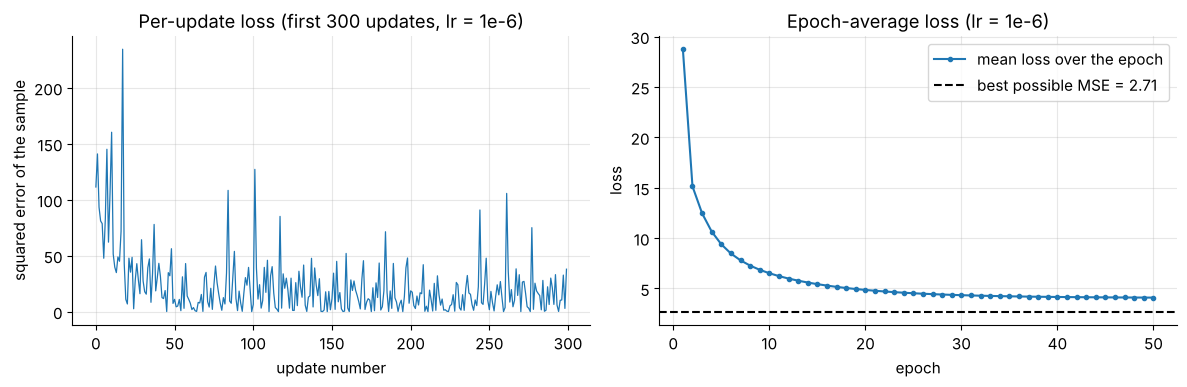

In [8]:
Xb_raw_tmp = np.column_stack([np.ones(len(X_train_raw)), X_train_raw])
theta_raw_best = np.linalg.lstsq(Xb_raw_tmp, y_train, rcond=None)[0]   # exact minimizer (Section 4.1)
best_mse_train = np.mean((Xb_raw_tmp @ theta_raw_best - y_train) ** 2)
print("best (b, w1, w2, w3):", np.round(theta_raw_best, 4).tolist(), f"| best training MSE = {best_mse_train:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(losses_raw[:300], lw=0.9)
axes[0].set(xlabel="update number", ylabel="squared error of the sample",
            title="Per-update loss (first 300 updates, lr = 1e-6)")
axes[1].plot(np.arange(1, 51), epoch_means, marker="o", ms=3, label="mean loss over the epoch")
axes[1].axhline(best_mse_train, color="k", ls="--", label=f"best possible MSE = {best_mse_train:.2f}")
axes[1].set(xlabel="epoch", ylabel="loss", title="Epoch-average loss (lr = 1e-6)")
axes[1].legend()
fig.tight_layout()
plt.show()

Three observations:

1. **The per-update loss is very noisy.** Each point is the error on *one* market, and markets differ
   a lot. Per-update curves always look like this for SGD, and the epoch average is the useful summary.
2. **Learning stalls well above the optimum.** After 50 epochs the epoch-average loss is still about
   $4.1$ versus the best possible $2.71$, and the bias $b$ has barely moved from $0$ (the best value
   is about $2.98$).
3. **We cannot simply raise the learning rate:** at $\eta = 3\times10^{-5}$ training explodes within
   two epochs.

### 1.6 Diagnosis: one learning rate, very different feature scales

Write the parameters as one list $\boldsymbol\theta = (b, w_1, w_2, w_3)$ and the inputs as
$\tilde{\mathbf x} = (1, x_1, x_2, x_3)$ (the "1" pairs with $b$). The update of Section 1.3 is
$\boldsymbol\theta \leftarrow \boldsymbol\theta - 2\eta e\,\tilde{\mathbf x}$. What does one step do
to the error *on the same sample*?

$$
\hat y_{\text{new}} = \tilde{\mathbf x}\cdot(\boldsymbol\theta - 2\eta e\,\tilde{\mathbf x})
= \hat y - 2\eta e\,\|\tilde{\mathbf x}\|^2
\quad\Longrightarrow\quad
e_{\text{new}} = e\,\bigl(1 - 2\eta\|\tilde{\mathbf x}\|^2\bigr).
$$

(You can check this on the worked example: $\|\tilde{\mathbf x}\|^2 = 1+4+1+9 = 15$ and
$-7.5\,(1 - 2\cdot 0.01\cdot 15) = -5.25 = 3.75 - 9$.) The step helps only if
$|1 - 2\eta\|\tilde{\mathbf x}\|^2| < 1$, that is $\eta < 1/\|\tilde{\mathbf x}\|^2$. Markets with a
big TV budget have a huge $\|\tilde{\mathbf x}\|^2$, so **the largest feature dictates a tiny learning
rate for everybody**. And with a tiny $\eta$, the bias, whose "feature" is only $1$, moves by a
microscopic $2\eta|e|$ per step. Let us compute the numbers:

In [9]:
sq_norms = 1.0 + (X_train_raw ** 2).sum(axis=1)           # ||x~||^2 for every training sample
print(f"largest ||x~||^2 in the training set: {sq_norms.max():,.0f}")
print(f"  -> per-sample stability needs lr < 1/{sq_norms.max():,.0f} = {1 / sq_norms.max():.2e}")
print(f"typical bias step with lr=1e-6 and |e|=2: {2 * 1e-6 * 2:.0e} per update, "
      f"distance to the best bias: {theta_raw_best[0]:.2f}")

largest ||x~||^2 in the training set: 99,352
  -> per-sample stability needs lr < 1/99,352 = 1.01e-05
typical bias step with lr=1e-6 and |e|=2: 4e-06 per update; distance to the best bias: 2.98


> **Key idea.** With raw features, gradient descent is held hostage by the feature with the largest
> magnitude: it forces a tiny learning rate, and then the parameters attached to small features
> (here: the bias) crawl. The cure is **feature scaling** (Section 3). Section 3.7 makes this
> precise with the *condition number*.

The scalar code has a second problem: it hard-codes three features. With 100 features you would
need 100 variables and 100 gradient lines. Section 2 replaces all of it with two lines of linear
algebra.

**Quick check.** In the worked example, which weight would *not* change at all if $x_2$ were $0$
instead of $1$, and why?

<details><summary>Answer</summary>

$w_2$: its gradient is $2e\,x_2 = 0$. A weight whose input is zero did not contribute to the
prediction, so it gets no blame and no update for this sample.
</details>

In [10]:
# ✏️ Exercise 1: one SGD step for d features, scalar style
def sgd_step_scalar(x, y, w, b, lr):
    """One SGD update of y_hat = sum_j w[j]*x[j] + b on a single sample.

    x, w: lists of floats of the same length d. y, b, lr: floats.
    Return (new_w, new_b, loss) where loss = (y_hat - y)**2 is computed with the OLD parameters.
    Do not modify the input lists in place."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    new_w, new_b, loss = sgd_step_scalar([2.0, 1.0, 3.0], 9.0, [1.0, 0.5, -0.5], 0.5, 0.01)
    assert abs(loss - 56.25) < 1e-9, f"loss should be 56.25, got {loss}"
    assert np.allclose(new_w, [1.3, 0.65, -0.05]) and abs(new_b - 0.65) < 1e-12, f"got {new_w}, {new_b}"
    w = [0.2, -0.1]
    new_w, new_b, loss = sgd_step_scalar([1.0, -2.0], 0.0, w, 0.3, 0.1)   # y_hat = 0.7, e = 0.7
    assert abs(loss - 0.49) < 1e-12, f"second case: loss should be 0.49, got {loss}"
    assert np.allclose(new_w, [0.2 - 0.14, -0.1 + 0.28]) and abs(new_b - (0.3 - 0.14)) < 1e-12, \
        f"second case: got {new_w}, {new_b}"   # x2 = -2, so dL/dw2 = 2(0.7)(-2) = -2.8
    assert w == [0.2, -0.1], "the input list w was modified in place"


run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def sgd_step_scalar(x, y, w, b, lr):
    y_hat = sum(wj * xj for wj, xj in zip(w, x)) + b
    e = y_hat - y
    new_w = [wj - lr * 2 * e * xj for wj, xj in zip(w, x)]
    new_b = b - lr * 2 * e
    return new_w, new_b, e ** 2
```
Compute the error once with the old parameters, then update every weight with
$2e\,x_j$ and the bias with $2e$, and building a new list keeps the input untouched.
</details>

---
## 2. From scalars to vectors and matrices

### 2.1 Notation and the design matrix

The trick that removes all the per-feature bookkeeping is to **fold the bias into the parameter
vector**: put a constant feature $x_0 = 1$ in front of every sample, so that $b$ becomes just another
weight $\theta_0$. Then the prediction for one sample is a single dot product. Here is the notation
used for the rest of the notebook (vectors are bold, matrices are capital letters):

| Symbol | Meaning | Shape |
|---|---|---|
| $N$ | number of training samples (160 for our advertising data) | scalar |
| $m$ | number of samples in one computation: $m = 1$ (one sample), $1 < m < N$ (mini-batch), $m = N$ (full batch) | scalar |
| $d$ | number of features (3 here) | scalar |
| $x^{(i)}_j$ | value of feature $j$ for sample $i$ | scalar |
| $\tilde{\mathbf x}^{(i)} = (1, x^{(i)}_1, \dots, x^{(i)}_d)^\top$ | features of sample $i$ with a leading 1 | $\mathbb R^{d+1}$ |
| $\boldsymbol\theta = (\theta_0, \theta_1, \dots, \theta_d)^\top = (b, w_1, \dots, w_d)^\top$ | all parameters | $\mathbb R^{d+1}$ |
| $X$ | **design matrix**, where row $i$ is $\tilde{\mathbf x}^{(i)\top}$ | $\mathbb R^{m\times(d+1)}$ |
| $\mathbf y$ | targets of the $m$ samples | $\mathbb R^{m}$ |
| $\hat{\mathbf y} = X\boldsymbol\theta$ | predictions | $\mathbb R^{m}$ |
| $\mathbf e = \hat{\mathbf y} - \mathbf y$ | error vector | $\mathbb R^{m}$ |
| $\mathcal L(\boldsymbol\theta) = \frac1m \lVert \mathbf e\rVert^2$ | loss: mean squared error over the $m$ samples | scalar |
| $\nabla_{\boldsymbol\theta}\mathcal L$ | gradient (vector of partial derivatives $\partial\mathcal L/\partial\theta_j$) | $\mathbb R^{d+1}$ |
| $H = \nabla^2_{\boldsymbol\theta}\mathcal L$ | Hessian (matrix of second derivatives) | $\mathbb R^{(d+1)\times(d+1)}$ |
| $\eta$ | learning rate | scalar |
| $\mathcal B$ | index set of a mini-batch (its size $\lvert\mathcal B\rvert$ is the batch size) | set |

A few conventions to keep in mind:

* We put the bias **first** ($\theta_0 = b$, first column of $X$ all ones). Some books put it last, and
  either is fine as long as $X$ and $\boldsymbol\theta$ use the same order.
* In math, vectors are columns, so a row of $X$ is a transposed vector $\tilde{\mathbf x}^{(i)\top}$.
* In code we store vectors as **1-D NumPy arrays** of shape `(m,)` and `(d+1,)`, never `(m, 1)`.
  Section 2.6 shows why mixing the two is dangerous.

Picture of the design matrix for our data ($m$ markets, $d = 3$):

```
             bias   TV      Radio   Newspaper
           [  1    x_1^(1)  x_2^(1)  x_3^(1) ]   <- market 1
     X  =  [  1    x_1^(2)  x_2^(2)  x_3^(2) ]   <- market 2
           [  :      :        :        :     ]
           [  1    x_1^(m)  x_2^(m)  x_3^(m) ]   <- market m        shape (m, d+1)
```

Then all $m$ predictions at once are one matrix–vector product,
$\hat{\mathbf y} = X\boldsymbol\theta$, because entry $i$ of $X\boldsymbol\theta$ is
$\tilde{\mathbf x}^{(i)\top}\boldsymbol\theta = b + w_1x^{(i)}_1 + \dots + w_dx^{(i)}_d$.

### 2.2 Worked example: a tiny batch by hand

Take $m = 3$ samples with $d = 2$ features and parameters $\boldsymbol\theta = (b, w_1, w_2) = (1,\ 2,\ 0.5)$:

$$
X = \begin{pmatrix} 1 & 2 & 0\\ 1 & 1 & 3\\ 1 & 4 & 1 \end{pmatrix},\qquad
\mathbf y = \begin{pmatrix} 5\\ 7\\ 10\end{pmatrix},\qquad
\hat{\mathbf y} = X\boldsymbol\theta = \begin{pmatrix} 1 + 4 + 0\\ 1 + 2 + 1.5\\ 1 + 8 + 0.5\end{pmatrix}
= \begin{pmatrix} 5\\ 4.5\\ 9.5\end{pmatrix},\qquad
\mathbf e = \begin{pmatrix} 0\\ -2.5\\ -0.5\end{pmatrix}.
$$

* Loss: $\mathcal L = \frac13(0^2 + 2.5^2 + 0.5^2) = \frac{6.5}{3} \approx 2.1667$.
* $X^\top\mathbf e$ takes the dot product of each **column** of $X$ with $\mathbf e$:
  ones column $\to 0 - 2.5 - 0.5 = -3$, the $x_1$ column $(2,1,4)\to 0 - 2.5 - 2 = -4.5$, and
  the $x_2$ column $(0,3,1) \to 0 - 7.5 - 0.5 = -8$.
* Gradient: $\nabla\mathcal L = \frac{2}{3}X^\top\mathbf e = (-2,\ -3,\ -5.3333)$.
* One step with $\eta = 0.1$: $\boldsymbol\theta \leftarrow (1.2,\ 2.3,\ 1.0333)$, and the loss
  drops to about $0.9515$.

The code below defines the **vectorized core** we use for the rest of the notebook and checks the numbers.

In [11]:
def add_bias(X):
    """Prepend a column of ones: (m, d) -> (m, d+1)."""
    X = np.asarray(X, dtype=float)
    return np.column_stack([np.ones(len(X)), X])


def predict(Xb, theta):
    """Predictions y_hat = Xb @ theta.  Xb: (m, d+1), theta: (d+1,)  ->  (m,)."""
    return Xb @ theta


def mse_loss(Xb, y, theta):
    """Mean squared error (1/m) * ||Xb theta - y||^2."""
    e = Xb @ theta - y
    return float(e @ e) / len(y)


def mse_grad(Xb, y, theta):
    """Gradient of the MSE: (2/m) * Xb^T (Xb theta - y), shape (d+1,)."""
    e = Xb @ theta - y
    return (2.0 / len(y)) * (Xb.T @ e)


X_small = add_bias([[2, 0], [1, 3], [4, 1]])
y_small = np.array([5.0, 7.0, 10.0])
theta_small = np.array([1.0, 2.0, 0.5])
print("X_small =\n", X_small)
print("y_hat   =", predict(X_small, theta_small))
print("loss    =", round(mse_loss(X_small, y_small, theta_small), 4))
g = mse_grad(X_small, y_small, theta_small)
print("grad    =", np.round(g, 4))
theta_next = theta_small - 0.1 * g
print("theta after one step:", np.round(theta_next, 4), "| new loss:", round(mse_loss(X_small, y_small, theta_next), 4))

X_small =
 [[1. 2. 0.]
 [1. 1. 3.]
 [1. 4. 1.]]
y_hat   = [5.  4.5 9.5]
loss    = 2.1667
grad    = [-2.     -3.     -5.3333]
theta after one step: [1.2    2.3    1.0333] | new loss: 0.9515


### 2.3 Deriving the gradient, three ways

**(a) One sample** ($m = 1$). With $\hat y = \tilde{\mathbf x}^\top\boldsymbol\theta$ and
$\mathcal L = (\hat y - y)^2$, the component formulas of Section 1.3 stack into one vector:

$$
\nabla_{\boldsymbol\theta}\mathcal L = 2(\hat y - y)\,\tilde{\mathbf x} \in \mathbb R^{d+1}.
$$

**(b) Many samples, as an average.** The batch loss is the average of per-sample losses,
$\mathcal L = \frac1m\sum_{i=1}^m e_i^2$, and the gradient of an average is the average of gradients:

$$
\nabla_{\boldsymbol\theta}\mathcal L = \frac1m\sum_{i=1}^m 2e_i\,\tilde{\mathbf x}^{(i)}
= \frac2m\,X^\top\mathbf e = \frac{2}{m}X^\top(X\boldsymbol\theta - \mathbf y).
$$

The middle step uses a fact worth memorizing: $X^\top\mathbf e = \sum_i e_i\,\tilde{\mathbf x}^{(i)}$
is a **weighted sum of the rows of $X$**, with the errors as weights. Each sample "votes" for a
direction (its own feature vector) with a strength equal to its error.

**(c) Matrix calculus.** Expand the squared norm:

$$
\mathcal L(\boldsymbol\theta) = \frac1m(X\boldsymbol\theta-\mathbf y)^\top(X\boldsymbol\theta-\mathbf y)
= \frac1m\left(\boldsymbol\theta^\top X^\top X\boldsymbol\theta - 2\,\mathbf y^\top X\boldsymbol\theta + \mathbf y^\top\mathbf y\right).
$$

With the rules $\nabla_{\boldsymbol\theta}(\boldsymbol\theta^\top A\boldsymbol\theta) = 2A\boldsymbol\theta$
for symmetric $A$ (here $A = X^\top X$) and $\nabla_{\boldsymbol\theta}(\mathbf c^\top\boldsymbol\theta) = \mathbf c$
(here $\mathbf c = X^\top \mathbf y$), we get
$\nabla\mathcal L = \frac1m(2X^\top X\boldsymbol\theta - 2X^\top\mathbf y)$, the same formula again.

**One formula, three algorithms.** Apply the formula to a subset $\mathcal B$ of the rows:

$$
\nabla_{\boldsymbol\theta}\mathcal L_{\mathcal B} = \frac{2}{|\mathcal B|}\,X_{\mathcal B}^\top\left(X_{\mathcal B}\boldsymbol\theta - \mathbf y_{\mathcal B}\right),
\qquad \boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\nabla_{\boldsymbol\theta}\mathcal L_{\mathcal B}.
$$

| Algorithm | rows used per update | gradient |
|---|---|---|
| Stochastic GD (SGD) | $\lvert\mathcal B\rvert = 1$ | $2e_i\tilde{\mathbf x}^{(i)}$ |
| Mini-batch GD | $1 < \lvert\mathcal B\rvert < N$ | $\frac{2}{\lvert\mathcal B\rvert}X_{\mathcal B}^\top\mathbf e_{\mathcal B}$ |
| Batch (full) GD | $\mathcal B$ = all $N$ rows | $\frac{2}{N}X^\top\mathbf e$ |

If $\mathcal B$ is drawn uniformly at random, the mini-batch gradient is an **unbiased estimate** of
the full gradient (its average over all possible batches equals the full gradient). It is just noisy.
Section 4 measures that noise.

**Second derivatives.** Differentiating the gradient once more gives the Hessian

$$
H = \nabla^2_{\boldsymbol\theta}\mathcal L = \frac2m X^\top X \in \mathbb R^{(d+1)\times(d+1)},
$$

which does **not depend on** $\boldsymbol\theta$: the loss is an exact quadratic bowl. It is positive
semidefinite because $\mathbf v^\top H\mathbf v = \frac2m\lVert X\mathbf v\rVert^2 \ge 0$ for every
$\mathbf v$, which is why the loss is convex. Section 3.7 uses $H$ to explain feature scaling.

**Shape bookkeeping** (do this every time you write a formula):

| expression | shape | expression | shape |
|---|---|---|---|
| $X$ | $(m, d+1)$ | $\mathbf e = X\boldsymbol\theta - \mathbf y$ | $(m,)$ |
| $\boldsymbol\theta$ | $(d+1,)$ | $X^\top\mathbf e$ | $(d+1,)$ (same as $\boldsymbol\theta$, as a gradient must be) |
| $X\boldsymbol\theta$ | $(m,)$ | $X^\top X$ | $(d+1, d+1)$ |

### 2.4 Gradient checking with finite differences

A hand-derived gradient can hide a sign error or a missing factor of 2. The cure is to compare it with
a **numerical** derivative. The central difference

$$
\frac{\partial\mathcal L}{\partial\theta_j} \approx \frac{\mathcal L(\boldsymbol\theta + h\,\mathbf u_j) - \mathcal L(\boldsymbol\theta - h\,\mathbf u_j)}{2h}
$$

(where $\mathbf u_j$ is the $j$-th unit vector) has error of order $h^2$, so with $h = 10^{-6}$ the two
should agree to many digits.

In [12]:
def numerical_grad(f, theta, h=1e-6):
    """Central-difference gradient of a scalar function f at theta."""
    grad = np.zeros_like(theta, dtype=float)
    for j in range(len(theta)):
        step = np.zeros_like(theta, dtype=float)
        step[j] = h
        grad[j] = (f(theta + step) - f(theta - step)) / (2 * h)
    return grad


def relative_error(a, b):
    return np.linalg.norm(a - b) / max(np.linalg.norm(a) + np.linalg.norm(b), 1e-12)


# 1) the tiny example, 2) a random problem with 5 features
num = numerical_grad(lambda t: mse_loss(X_small, y_small, t), theta_small)
print("tiny example: analytic", np.round(mse_grad(X_small, y_small, theta_small), 6),
      "| numeric", np.round(num, 6))
g_rng = np.random.default_rng(1)
X_rand, y_rand, t_rand = add_bias(g_rng.normal(size=(50, 5))), g_rng.normal(size=50), g_rng.normal(size=6)
num = numerical_grad(lambda t: mse_loss(X_rand, y_rand, t), t_rand)
print(f"random problem: relative error = {relative_error(mse_grad(X_rand, y_rand, t_rand), num):.1e}")

tiny example: analytic [-2.       -3.       -5.333333] | numeric [-2.       -3.       -5.333333]
random problem: relative error = 8.4e-11


> **Olympiad tip.** Whenever you derive a gradient by hand (in a contest or in research), check it
> with finite differences on a tiny random problem. A relative error around $10^{-8}$ or smaller means
> the formula is right, and an error near $1$ means a bug. It takes two minutes and saves hours.

### 2.5 Loops versus vectorized code: a timing experiment

Vectorization is not only shorter but also much faster. Below, the same MSE gradient is computed with
explicit Python loops and with NumPy, on a synthetic problem with $m = 20{,}000$ samples and
$d = 10$ features. Python executes every multiply-add through the interpreter (type checks, object
creation), while NumPy runs one compiled loop over contiguous memory, using optimized linear-algebra
routines (BLAS). For a fair one-core-versus-one-core comparison we limit BLAS to a single thread
while timing, and we report the best of several repeats (the minimum is the least disturbed by other
programs running on the machine).

In [13]:
from threadpoolctl import threadpool_limits


def mse_grad_loops(X_rows, y_vals, theta_vals):
    """The same gradient with explicit Python loops (lists in, list out)."""
    m, p = len(y_vals), len(theta_vals)
    grad = [0.0] * p
    for i in range(m):
        row = X_rows[i]
        y_hat = 0.0
        for j in range(p):                       # prediction: dot product of row i and theta
            y_hat += row[j] * theta_vals[j]
        e = y_hat - y_vals[i]
        for j in range(p):                       # accumulate 2 * e_i * x_ij / m
            grad[j] += 2.0 * e * row[j] / m
    return grad


g_rng = np.random.default_rng(0)
m_big, d_big = 20_000, 10
X_big = add_bias(g_rng.normal(size=(m_big, d_big)))
theta_big = g_rng.normal(size=d_big + 1)
y_big = X_big @ theta_big + g_rng.normal(size=m_big)
X_big_list, y_big_list, theta_big_list = X_big.tolist(), y_big.tolist(), theta_big.tolist()

same = np.allclose(mse_grad_loops(X_big_list, y_big_list, theta_big_list), mse_grad(X_big, y_big, theta_big))
with threadpool_limits(limits=1):
    t_loop = min(timeit.repeat(lambda: mse_grad_loops(X_big_list, y_big_list, theta_big_list), number=1, repeat=3))
    t_vec = min(timeit.repeat(lambda: mse_grad(X_big, y_big, theta_big), number=10, repeat=5)) / 10
print(f"same result: {same}")
print(f"Python loops: {1e3 * t_loop:8.2f} ms per gradient")
print(f"NumPy       : {1e3 * t_vec:8.3f} ms per gradient   -> speed-up x{t_loop / t_vec:,.0f}")

same result: True
Python loops:    28.98 ms per gradient
NumPy       :    0.194 ms per gradient   -> speed-up x150


The vectorized gradient is faster by the factor printed above: two to three orders of magnitude
on one CPU core (the exact number depends on your machine, and it grows further when NumPy may use
several cores). Training runs thousands of gradient evaluations, so even a factor of 100 is the
difference between half a minute and an hour. Both versions perform the same $2m(d+1)$ or so
multiply-adds, but the loop version simply pays the interpreter's overhead on every single one.

> **Key idea.** In numerical Python, avoid loops over samples or features in the inner computation.
> Write the math with vectors and matrices, then translate each symbol directly: $X\boldsymbol\theta$
> becomes `X @ theta`, $X^\top\mathbf e$ becomes `X.T @ e`.

### 2.6 Shape discipline: the `(m, 1)` versus `(m,)` trap

NumPy distinguishes a 1-D array of shape `(m,)` from a 2-D "column" of shape `(m, 1)`. Both appear
naturally: `df["Sales"].to_numpy()` gives `(m,)`, while `df[["Sales"]].to_numpy()` (double brackets)
or slicing like `data[:, 3:]` gives `(m, 1)`. Mixing them triggers **broadcasting**: NumPy compares
shapes from the right and stretches any dimension of size 1. So `(m,) - (m, 1)` is treated as
`(1, m) - (m, 1)` and becomes an `(m, m)` matrix of all pairwise differences, *without any error*.

In [14]:
y_col = y_small.reshape(-1, 1)                 # (3, 1): e.g. what df[["Sales"]].to_numpy() returns
y_hat_flat = X_small @ theta_small             # (3,)
bad_e = y_hat_flat - y_col                     # broadcasting: (3,) - (3, 1) -> (3, 3) !
print("shapes:", y_hat_flat.shape, "-", y_col.shape, "->", bad_e.shape)
print("silently wrong loss:", round(float(np.mean(bad_e ** 2)), 4),
      "| correct loss:", round(mse_loss(X_small, y_small, theta_small), 4))

bad_grad = 2 / 3 * X_small.T @ bad_e           # (3, 3) instead of (3,)
theta_broken = theta_small - 0.1 * bad_grad    # theta has become a matrix!
print("gradient shape:", bad_grad.shape, "| theta shape after one 'update':", theta_broken.shape)

shapes: (3,) - (3, 1) -> (3, 3)
silently wrong loss: 10.2778 | correct loss: 2.1667
gradient shape: (3, 3) | theta shape after one 'update': (3, 3)


Nothing crashed, yet the loss is wrong and after one update $\boldsymbol\theta$ is a $3\times 3$
matrix. Training would continue happily and produce garbage. Defenses:

1. **Pick one convention and convert at the boundary.** In this notebook every vector is 1-D:
   `y = np.asarray(y, dtype=float).reshape(-1)` (or `.ravel()`) right where data enters your code.
2. **Assert shapes** in functions you write: `assert y_hat.shape == y.shape`.
3. If you prefer column vectors (some codebases keep $\boldsymbol\theta$ as `(d+1, 1)` and $\mathbf y$ as
   `(m, 1)`), that also works, but then *everything* must be 2-D, consistently.

> **Common pitfall.** Broadcasting bugs rarely raise errors. They show up as "the loss looks weird"
> or "the model doesn't learn". When that happens, print the `.shape` of every array first.

In [15]:
# ✏️ Exercise 2: a shape-robust vectorized predict + loss + gradient
def predict_loss_grad(Xb, y, theta):
    """Return (y_hat, loss, grad) for the MSE of a linear model.

    Xb: (m, d+1) design matrix with a bias column. y may have shape (m,) or (m, 1),
    and theta may have shape (d+1,) or (d+1, 1).
    y_hat must have shape (m,), loss must be a Python float, and grad must have the SAME shape as theta.
    Use vectorized NumPy (no Python loops over samples)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    for y_shape in [(3,), (3, 1)]:
        for t_shape in [(3,), (3, 1)]:
            y_hat, loss, grad = predict_loss_grad(X_small, y_small.reshape(y_shape), theta_small.reshape(t_shape))
            assert np.shape(y_hat) == (3,), f"y_hat shape should be (3,), got {np.shape(y_hat)}"
            assert isinstance(loss, float), f"loss should be a Python float, got {type(loss)}"
            assert abs(loss - 6.5 / 3) < 1e-12, f"loss should be 2.1667 (y{y_shape}, theta{t_shape}), got {loss}"
            assert np.shape(grad) == t_shape, f"grad shape should be {t_shape}, got {np.shape(grad)}"
            assert np.allclose(np.ravel(grad), [-2.0, -3.0, -16 / 3]), f"wrong gradient {np.ravel(grad)}"
    g_rng = np.random.default_rng(7)
    Xr, yr, tr = add_bias(g_rng.normal(size=(40, 4))), g_rng.normal(size=40), g_rng.normal(size=5)
    num = numerical_grad(lambda t: float(np.mean((Xr @ t - yr) ** 2)), tr)
    assert relative_error(predict_loss_grad(Xr, yr, tr)[2], num) < 1e-6, "gradient fails the finite-difference check"


run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def predict_loss_grad(Xb, y, theta):
    theta_flat = np.asarray(theta, dtype=float).reshape(-1)
    y_flat = np.asarray(y, dtype=float).reshape(-1)
    y_hat = Xb @ theta_flat
    e = y_hat - y_flat
    loss = float(e @ e) / len(y_flat)
    grad = (2.0 / len(y_flat)) * (Xb.T @ e)
    return y_hat, loss, grad.reshape(np.shape(theta))
```
Flatten everything to 1-D at the boundary, do the math once, and reshape the gradient back to the
caller's convention at the end.
</details>

---
## 3. Feature scaling

### 3.1 The idea: one affine map per column

Section 1.6 showed the problem: TV budgets are numbers in the hundreds, Radio budgets in the tens,
and the bias "feature" is always $1$. A single learning rate cannot suit all of them. **Feature
scaling** fixes this by re-expressing every feature column on a comparable scale *before* training.

> **Intuition.** Think of measuring a room's length in millimeters and its width in kilometers.
> Both numbers describe the same room, but any rule of the form "move each coordinate by the same
> amount" would be absurd: a step of 1 changes the length by a hair and the width by a whole
> kilometer. Scaling chooses sensible units for every coordinate so that "one step" means about the
> same thing in every direction.

All three scalers in this section have the same form. For every feature column $j$ we compute a
**center** $c_j$ and a **scale** $s_j > 0$ from the *training data*, and replace each value by

$$
z_j = \frac{x_j - c_j}{s_j}, \qquad\text{with inverse}\qquad x_j = z_j\,s_j + c_j .
$$

| scaler | center $c_j$ | scale $s_j$ | what the training column looks like afterwards |
|---|---|---|---|
| min-max | $\min_i x^{(i)}_j$ | $\max_i x^{(i)}_j - \min_i x^{(i)}_j$ | values in $[0, 1]$ |
| z-score (standardization) | mean $\mu_j$ | standard deviation $\sigma_j$ | mean $0$, standard deviation $1$ |
| robust | median | interquartile range $Q_3 - Q_1$ | median $0$, interquartile range $1$ |

Each map is **affine** (multiply by a constant, add a constant), so it never changes the *shape* of
a feature's distribution, the order of its values, or its correlation with anything else. It only
changes the units. The key phrase is "per column": every feature gets its *own* $c_j$ and $s_j$.

### 3.2 Min-max scaling and its inverse

$$
x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}, \qquad x = x'\,(x_{\max} - x_{\min}) + x_{\min}.
$$

**Worked example.** Five radio budgets $x = (12, 30, 48, 3, 21)$: $x_{\min} = 3$, $x_{\max} = 48$,
range $= 45$.

| $x$ | $x - 3$ | $x' = (x-3)/45$ | inverse $x' \cdot 45 + 3$ |
|---|---|---|---|
| 12 | 9 | 0.2 | 12 |
| 30 | 27 | 0.6 | 30 |
| 48 | 45 | 1.0 | 48 |
| 3 | 0 | 0.0 | 3 |
| 21 | 18 | 0.4 | 21 |

A *new* market with a radio budget of $57$ maps to $(57 - 3)/45 = 1.2$. That is not an error:
the scaler's $x_{\min}$ and $x_{\max}$ were learned from training data, and new data may fall
outside $[0, 1]$. (Never "re-fit" the scaler to make it fit. Section 3.8 explains why.)

Properties: a bounded, easy-to-read range, but a single extreme value sets $x_{\max}$ and squashes
every other value into a narrow band, and the result is *not centered* (its mean is not $0$), which
matters for gradient descent, as Section 3.7 will show.

### 3.3 Z-score standardization and its inverse

$$
z = \frac{x - \mu}{\sigma}, \qquad x = z\,\sigma + \mu, \qquad
\mu = \frac1N\sum_{i=1}^N x^{(i)}, \qquad \sigma = \sqrt{\frac1N\sum_{i=1}^N \bigl(x^{(i)} - \mu\bigr)^2}.
$$

A z-score answers the question "how many standard deviations above or below average is this
value?". **Worked example** with the same five budgets: $\mu = 114/5 = 22.8$, and the deviations are
$(-10.8,\ 7.2,\ 25.2,\ -19.8,\ -1.8)$, whose squares sum to $1198.8$.

* **Population** standard deviation (divide by $N = 5$): $\sigma = \sqrt{1198.8/5} = \sqrt{239.76} \approx 15.4842$,
  giving $z \approx (-0.6975,\ 0.4650,\ 1.6275,\ -1.2787,\ -0.1162)$.
* **Sample** standard deviation (divide by $N - 1 = 4$): $s = \sqrt{1198.8/4} = \sqrt{299.7} \approx 17.3118$,
  giving $z \approx (-0.6239,\ 0.4159,\ 1.4557,\ -1.1437,\ -0.1040)$.

The two differ by the constant factor $s/\sigma = \sqrt{N/(N-1)}$: about $1.118$ for $N = 5$, but only
$1.003$ for our $N = 160$ training markets. Why do two versions exist? Dividing by $N - 1$
(**Bessel's correction**) makes $s^2$ an *unbiased* estimate of the variance of the whole population
the sample came from: the deviations are measured from $\mu$, which was fitted to the same data and
is therefore a little too close to them. For *scaling*, either choice works, as long as you use the
**same** one when you fit, transform and invert. The trap is that popular libraries disagree:

| tool | default |
|---|---|
| `numpy.std(x)` | population, `ddof=0` |
| `pandas.Series.std()` / `DataFrame.std()` | sample, `ddof=1` |
| `sklearn.preprocessing.StandardScaler` | population, `ddof=0` (fixed, no option) |
| `statistics.stdev` / `statistics.pstdev` | sample / population |

(`ddof` means "delta degrees of freedom": the divisor is $N - \text{ddof}$.)

### 3.4 Robust scaling

The mean, the standard deviation and especially the min and max are all dragged around by a single
extreme value. **Robust scaling** uses the median as the center and the interquartile range
$\text{IQR} = Q_3 - Q_1$ (the width of the middle 50% of the data) as the scale. Neither moves much
when one value goes wild. Suppose a sixth market had a data-entry error, $600$ instead of $60$:
$x = (12, 30, 48, 3, 21, 600)$. Then median $= 25.5$, $Q_1 = 14.25$, $Q_3 = 43.5$ (NumPy's default
linear interpolation between sorted values), $\text{IQR} = 29.25$. The plot below compares what the
three scalers do to these six values.

min-max : ordinary values span [ 0.000,  0.075], outlier ->   1.000
z-score : ordinary values span [-0.538, -0.329], outlier ->   2.231
robust  : ordinary values span [-0.769,  0.769], outlier ->  19.641


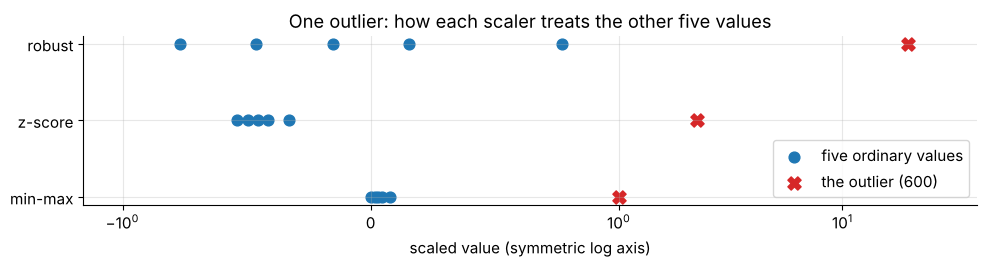

In [16]:
x_demo = np.array([12.0, 30.0, 48.0, 3.0, 21.0, 600.0])
q1_demo, med_demo, q3_demo = np.percentile(x_demo, [25, 50, 75])
scaled_demo = {
    "min-max": (x_demo - x_demo.min()) / (x_demo.max() - x_demo.min()),
    "z-score": (x_demo - x_demo.mean()) / x_demo.std(),
    "robust": (x_demo - med_demo) / (q3_demo - q1_demo),
}
fig, ax = plt.subplots(figsize=(10, 2.8))
for row, (name, z) in enumerate(scaled_demo.items()):
    ax.scatter(z[:-1], np.full(5, row), s=60, label="five ordinary values" if row == 0 else None, color="C0")
    ax.scatter(z[-1:], [row], s=90, marker="X", color="C3", label="the outlier (600)" if row == 0 else None)
    print(f"{name:8s}: ordinary values span [{z[:-1].min():6.3f}, {z[:-1].max():6.3f}], outlier -> {z[-1]:7.3f}")
ax.set_yticks(range(3), list(scaled_demo))
ax.set_xscale("symlog", linthresh=1.0)
ax.set_xlim(-1.5, 40)
ax.set(xlabel="scaled value (symmetric log axis)", title="One outlier: how each scaler treats the other five values")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

With min-max scaling the five ordinary values are crushed into $[0, 0.075]$, and with the z-score
they are all squeezed near $-0.4$ (the outlier inflated $\sigma$ to about $216$). Robust scaling keeps
them spread over $[-0.77, 0.77]$, where a learning algorithm can still tell them apart, and simply
leaves the outlier far away at about $19.6$. Robust scaling does not *remove* outliers, but
it just stops them from dictating the scale of everything else.

### 3.5 From scratch, verified against scikit-learn

Because all three scalers share the form $z = (x - c)/s$, one small set of functions covers them.
The single most important detail is **`axis=0`**: statistics are computed *down each column*, giving
one number per feature.

In [17]:
def fit_scaler(X, method="zscore", ddof=0):
    """Learn per-column (center, scale) from training data X of shape (m, d)."""
    X = np.asarray(X, dtype=float)
    if method == "minmax":
        center, scale = X.min(axis=0), X.max(axis=0) - X.min(axis=0)
    elif method == "zscore":
        center, scale = X.mean(axis=0), X.std(axis=0, ddof=ddof)
    elif method == "robust":
        q1, med, q3 = np.percentile(X, [25, 50, 75], axis=0)
        center, scale = med, q3 - q1
    else:
        raise ValueError(f"unknown method {method!r}")
    scale = np.where(scale == 0, 1.0, scale)     # a constant column would give 0/0, so leave it unscaled
    return center, scale


def scale_transform(X, center, scale):
    """Apply z = (x - center) / scale column by column (broadcasting over rows)."""
    return (np.asarray(X, dtype=float) - center) / scale


def scale_inverse(Z, center, scale):
    """Undo the scaling: x = z * scale + center."""
    return np.asarray(Z, dtype=float) * scale + center


from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

sk_scalers = {"minmax": MinMaxScaler(), "zscore": StandardScaler(), "robust": RobustScaler()}
for method, sk in sk_scalers.items():
    c, s = fit_scaler(X_train_raw, method)
    Z_ours = scale_transform(X_train_raw, c, s)
    Z_sk = sk.fit(X_train_raw).transform(X_train_raw)
    Z_test_ours = scale_transform(X_test_raw, c, s)                # TEST data, TRAIN statistics
    round_trip = np.allclose(scale_inverse(Z_ours, c, s), X_train_raw)
    print(f"{method:7s} matches sklearn: {np.allclose(Z_ours, Z_sk)} | round trip exact: {round_trip} | "
          f"test columns span {np.round(Z_test_ours.min(axis=0), 2)} .. {np.round(Z_test_ours.max(axis=0), 2)}")

c_z, s_z = fit_scaler(X_train_raw, "zscore")
print("\nz-scored TRAIN columns: means", np.round(scale_transform(X_train_raw, c_z, s_z).mean(axis=0), 12),
      "| stds", np.round(scale_transform(X_train_raw, c_z, s_z).std(axis=0), 12))
print("population std (ddof=0):", np.round(s_z, 4))
print("sample std     (ddof=1):", np.round(fit_scaler(X_train_raw, "zscore", ddof=1)[1], 4),
      "= pandas default:", np.round(adv_train[FEATURES].std().to_numpy(), 4))

minmax  matches sklearn: True | round trip exact: True | test columns span [0.02 0.03 0.01] .. [0.99 1.   1.13]
zscore  matches sklearn: True | round trip exact: True | test columns span [-1.72 -1.44 -1.43] .. [1.7  1.8  4.15]
robust  matches sklearn: True | round trip exact: True | test columns span [-1.03 -0.74 -0.78] .. [1.01 1.06 2.8 ]

z-scored TRAIN columns: means [-0. -0.  0.] | stds [1. 1. 1.]
population std (ddof=0): [84.1546 14.7589 20.2728]
sample std     (ddof=1): [84.4189 14.8052 20.3364] = pandas default: [84.4189 14.8052 20.3364]


All three match scikit-learn, and the inverse transform recovers the original numbers. Two details
in the output deserve attention:

* The **test** columns, scaled with **training** statistics, do not have exactly mean $0$ /
  standard deviation $1$, and min-max-scaled test values can leave $[0, 1]$. That is correct
  behavior, not a bug.
* The sample and population standard deviations differ by only about $0.3\%$ for $N = 160$
  (for TV, $84.42$ versus $84.15$), yet `pandas.DataFrame.std()` and `StandardScaler` *do* disagree.
  If you ever standardize with pandas and invert with a scikit-learn scaler's `scale_` (or the other
  way around), you will get values that are slightly, silently wrong.

**Quick check.** A feature has training mean $50$ and (population) standard deviation $8$. What is
the z-score of a new value $62$, and which original value has z-score $-0.75$?

<details><summary>Answer</summary>

$z = (62 - 50)/8 = 1.5$. Inverting, $x = -0.75 \cdot 8 + 50 = 44$.
</details>

### 3.6 Common pitfall: one global statistic for the whole matrix

A frequent bug is to forget `axis=0`. Then `X.min()`, `X.max()` and `X.mean()` return **one number
for the entire matrix**, and every column is shifted and divided by the same amounts. Here is the
"mean normalization" $z = (x - \bar x)/(x_{\max} - x_{\min})$ done both ways:

,global: mean,global: range,per-column: mean,per-column: range
TV,0.278,0.998,-0.0,1.0
Radio,-0.151,0.167,-0.0,1.0
Newspaper,-0.127,0.339,0.0,1.0


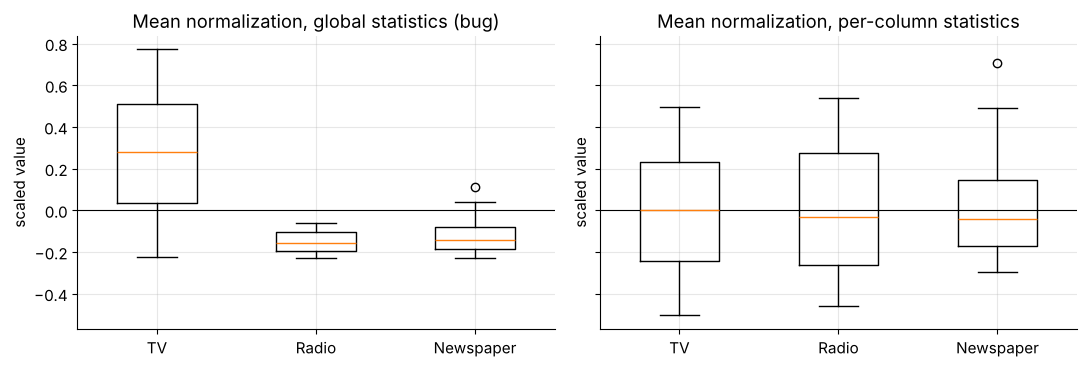

In [18]:
def mean_normalize(X, per_column=True):
    """(x - mean) / (max - min), per column (axis=0) or, wrongly, with one global statistic."""
    axis = 0 if per_column else None
    return (X - X.mean(axis=axis)) / (X.max(axis=axis) - X.min(axis=axis))


Z_global = mean_normalize(X_train_raw, per_column=False)
Z_percol = mean_normalize(X_train_raw, per_column=True)
summary = pd.DataFrame({
    "global: mean": Z_global.mean(axis=0), "global: range": np.ptp(Z_global, axis=0),
    "per-column: mean": Z_percol.mean(axis=0), "per-column: range": np.ptp(Z_percol, axis=0),
}, index=FEATURES)
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, Z, title in [(axes[0], Z_global, "global statistics (bug)"), (axes[1], Z_percol, "per-column statistics")]:
    ax.boxplot([Z[:, j] for j in range(3)], widths=0.5)     # one box per column
    ax.set_xticks([1, 2, 3], FEATURES)
    ax.axhline(0, color="k", lw=0.8)
    ax.set(ylabel="scaled value", title=f"Mean normalization, {title}")
fig.tight_layout()
plt.show()

Nothing crashes and the numbers *look* scaled (they are all small), but the global version kept the
columns exactly as unequal as before: TV still spans a range about $6\times$ wider than Radio
($0.998$ versus $0.167$), and the columns are not centered either (TV sits at $+0.28$, Radio at
$-0.15$). Dividing *everything* by one number cannot fix *relative* scales. A useful self-test: after
scaling, print the per-column means and ranges (or standard deviations). If they are not all
(nearly) the same, the scaling did not do its job.

> **Common pitfall.** `X.mean()`, `X.std()`, `X.min()` and `X.max()` on a 2-D NumPy array reduce
> over **all** entries unless you pass `axis=0`. (A pandas DataFrame reduces per column by default,
> which is one reason this bug appears when code moves from pandas to NumPy.)

How much does this cost in training? To answer that properly we need a little theory.

### 3.7 Why scaling speeds up gradient descent

Section 2.3 showed that the MSE is an exact quadratic bowl with constant Hessian
$H = \frac2N X^\top X$. Writing $\boldsymbol\theta^\star$ for the minimizer and $\mathcal L^\star$ for
the minimal loss, a second-order Taylor expansion (which is *exact* for a quadratic) gives

$$
\mathcal L(\boldsymbol\theta) = \mathcal L^\star + \tfrac12(\boldsymbol\theta - \boldsymbol\theta^\star)^\top H\,(\boldsymbol\theta - \boldsymbol\theta^\star),
\qquad
\nabla\mathcal L(\boldsymbol\theta) = H(\boldsymbol\theta - \boldsymbol\theta^\star).
$$

One full-batch step $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\nabla\mathcal L$ therefore maps
the error $\boldsymbol\delta = \boldsymbol\theta - \boldsymbol\theta^\star$ to $(I - \eta H)\,\boldsymbol\delta$.
Because $H$ is symmetric it has orthonormal eigenvectors $\mathbf q_k$ with eigenvalues
$\lambda_k \ge 0$. Along each eigenvector the error simply gets multiplied by a number:

$$
\delta_k \;\leftarrow\; (1 - \eta\lambda_k)\,\delta_k \qquad\text{(one independent 1-D problem per eigen-direction).}
$$

Two consequences follow immediately:

1. **Stability.** Every factor must satisfy $|1 - \eta\lambda_k| < 1$, so we need
   $\eta < 2/\lambda_{\max}$. The *steepest* direction sets the largest usable learning rate.
2. **Speed.** The *flattest* direction shrinks by $1 - \eta\lambda_{\min}$ per step. With the safe
   choice $\eta = 1/\lambda_{\max}$ this is $1 - 1/\kappa$, where

$$
\kappa = \frac{\lambda_{\max}}{\lambda_{\min}} \quad\text{is the **condition number** of } H \text{ (equivalently of } X^\top X\text{)},
$$

   so reducing the error in that direction by a factor $\varepsilon$ takes about
   $\kappa\ln(1/\varepsilon)$ steps. A large $\kappa$ is a long, narrow valley: the learning rate
   must be small enough for the steep walls, and then progress along the flat valley floor is slow.

Since the excess loss is $\tfrac12\sum_k \lambda_k\delta_k^2$ and each $\delta_k$ evolves
independently, we can even **predict exactly** how many steps gradient descent needs, without
running it:

$$
\mathcal L(\boldsymbol\theta_t) - \mathcal L^\star = \tfrac12\sum_k \lambda_k\,(1-\eta\lambda_k)^{2t}\,\delta_k(0)^2 .
$$

The next cell computes $\kappa$ and this prediction for every scaling we have discussed, starting from
$\boldsymbol\theta = \mathbf 0$ with $\eta = 1/\lambda_{\max}$, and counting steps until the excess
loss is below $0.1\%$ of $\mathcal L^\star$. It then confirms the prediction by actually running
gradient descent for the cases that finish quickly.

In [19]:
def gd_steps_predicted(Xb, y, lr, rel_tol=1e-3):
    """Exact number of full-batch GD steps (from theta = 0) until loss - L* <= rel_tol * L*."""
    H = 2.0 / len(y) * Xb.T @ Xb
    lam, Q = np.linalg.eigh(H)
    theta_star = np.linalg.lstsq(Xb, y, rcond=None)[0]
    L_star = np.mean((Xb @ theta_star - y) ** 2)
    delta0 = Q.T @ (np.zeros(Xb.shape[1]) - theta_star)          # initial error in the eigenbasis

    def excess(t):
        return 0.5 * np.sum(lam * (1 - lr * lam) ** (2 * t) * delta0 ** 2)

    lo, hi = 0, 1
    while excess(hi) > rel_tol * L_star:                         # exponential search, then bisection
        lo, hi = hi, 2 * hi
    while hi - lo > 1:
        mid = (lo + hi) // 2
        lo, hi = (mid, hi) if excess(mid) > rel_tol * L_star else (lo, mid)
    return hi


def gd_steps_simulated(Xb, y, lr, rel_tol=1e-3, max_steps=50_000):
    """Run full-batch GD from theta = 0 and count the steps (None if max_steps is not enough)."""
    theta_star = np.linalg.lstsq(Xb, y, rcond=None)[0]
    L_star = np.mean((Xb @ theta_star - y) ** 2)
    theta = np.zeros(Xb.shape[1])
    for t in range(1, max_steps + 1):
        theta -= lr * mse_grad(Xb, y, theta)
        if mse_loss(Xb, y, theta) - L_star <= rel_tol * L_star:
            return t
    return None


c_mm, s_mm = fit_scaler(X_train_raw, "minmax")
scalings = {
    "raw (no scaling)": X_train_raw,
    "global mean normalization (bug)": Z_global,
    "per-column min-max": scale_transform(X_train_raw, c_mm, s_mm),
    "per-column z-score": scale_transform(X_train_raw, c_z, s_z),
}
rows = []
for name, Z in scalings.items():
    Xb = add_bias(Z)
    lam = np.linalg.eigvalsh(2.0 / len(y_train) * Xb.T @ Xb)
    lr = 1.0 / lam.max()
    predicted = gd_steps_predicted(Xb, y_train, lr)
    simulated = gd_steps_simulated(Xb, y_train, lr) if predicted <= 50_000 else "(skipped)"
    rows.append({"features": name, "lambda_min": lam.min(), "lambda_max": lam.max(), "condition number": lam.max() / lam.min(),
                 "max stable lr 2/lambda_max": 2 / lam.max(), "steps predicted": predicted, "steps simulated": simulated})
cond_table = pd.DataFrame(rows).set_index("features")
formats = {"lambda_min": "{:.3g}", "lambda_max": "{:.4g}", "condition number": "{:,.1f}",
           "max stable lr 2/lambda_max": "{:.3g}", "steps predicted": "{:,}"}
display(cond_table.apply(lambda col: col.map(formats[col.name].format) if col.name in formats else col))

,lambda_min,lambda_max,condition number,max stable lr 2/lambda_max,steps predicted,steps simulated
features,,,,,,
raw (no scaling),0.277,6.145e+04,"221,453.1",3.25e-05,"677,546",(skipped)
global mean normalization (bug),0.00368,2.245,609.1,0.891,"2,289",2289
per-column min-max,0.0613,3.178,51.8,0.629,122,122
per-column z-score,1.22,2.79,2.3,0.717,6,6


Read the table from top to bottom:

* **Raw features:** $\kappa$ in the hundreds of thousands. Even with a well-chosen learning rate this
  ill-conditioning costs hundreds of thousands of steps, which is why Section 1.5 got stuck.
* **Global mean normalization:** much better than raw (everything is now of order $1$), but the
  columns still have unequal spreads and nonzero means, and gradient descent needs thousands of steps.
* **Per-column min-max:** every column now has the same range, yet $\kappa$ is still around $50$.
  The reason is subtle: min-max scaling does **not center** the data, so every feature column has a
  large positive mean and overlaps heavily with the all-ones bias column. The bias and the weights
  then "fight" over the same direction.
* **Per-column z-score:** centered *and* equally spread. The condition number is close to its ideal
  value $1$ and gradient descent converges in a handful of steps.

The simulated counts agree with the predictions from the eigenvalue formula, which is a nice check
that the theory is not just a story. Notice also the column "max stable lr": it is the number you
would otherwise discover by trial and error (Section 4.5 tests it).

**Picture it in 2-D.** To draw the loss surface we need exactly two parameters, so we keep only TV and
Radio and **center** both features and the target (then the best bias is exactly the mean of $y$ and
drops out of the picture). The ellipses are contour lines of the loss, and the red path is gradient
descent with its best constant learning rate, $\eta = 2/(\lambda_{\max} + \lambda_{\min})$.

centered, raw units : kappa =  32.6, relative distance to the minimum after 25 steps = 2.2e-01
standardized        : kappa =   1.1, relative distance to the minimum after 25 steps = 9.4e-17


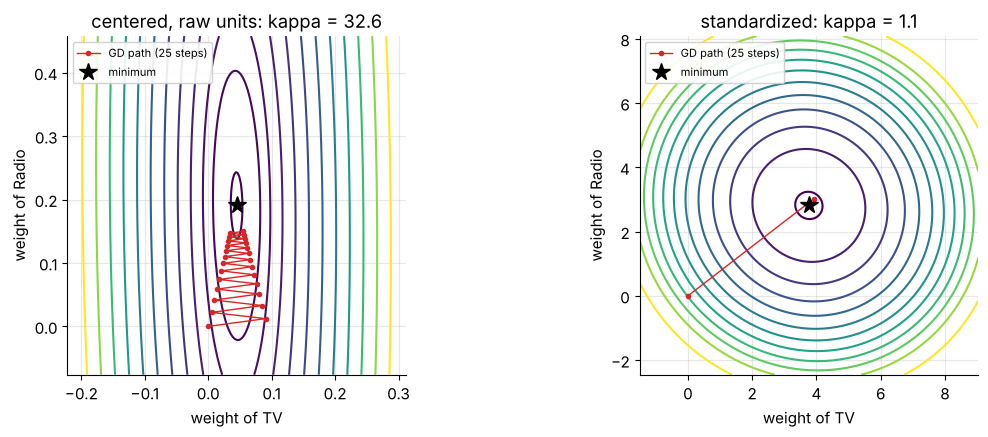

In [20]:
def gd_path_2d(A, t, lr, n_steps):
    """Full-batch GD path for a 2-parameter, no-bias least-squares problem (A: (m, 2), t: (m,))."""
    w = np.zeros(2)
    path = [w.copy()]
    for _ in range(n_steps):
        w = w - lr * (2.0 / len(t)) * A.T @ (A @ w - t)
        path.append(w.copy())
    return np.array(path)


A_raw = X_train_raw[:, :2] - X_train_raw[:, :2].mean(axis=0)      # centered TV and Radio
t_c = y_train - y_train.mean()                                      # centered target
A_std = A_raw / X_train_raw[:, :2].std(axis=0)                      # ... and standardized

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, A, name in [(axes[0], A_raw, "centered, raw units"), (axes[1], A_std, "standardized")]:
    lam = np.linalg.eigvalsh(2.0 / len(t_c) * A.T @ A)
    w_star = np.linalg.lstsq(A, t_c, rcond=None)[0]
    path = gd_path_2d(A, t_c, lr=2.0 / (lam.max() + lam.min()), n_steps=25)
    span = 1.4 * np.abs(w_star).max()
    g1 = np.linspace(w_star[0] - span, w_star[0] + span, 200)
    g2 = np.linspace(w_star[1] - span, w_star[1] + span, 200)
    W1, W2 = np.meshgrid(g1, g2)
    resid = A[:, 0] * W1[..., None] + A[:, 1] * W2[..., None] - t_c   # (200, 200, m) residual grid
    loss_grid = np.mean(resid ** 2, axis=-1)
    ax.contour(W1, W2, loss_grid, levels=np.quantile(loss_grid, np.linspace(0.005, 0.9, 12)), cmap="viridis")
    ax.plot(path[:, 0], path[:, 1], "o-", color="C3", ms=3, lw=1, label="GD path (25 steps)")
    ax.plot(*w_star, "k*", ms=13, label="minimum")
    ax.set_aspect("equal")
    ax.set(xlabel="weight of TV", ylabel="weight of Radio",
           title=f"{name}: kappa = {lam.max() / lam.min():.1f}")
    ax.legend(loc="upper left", fontsize=8, framealpha=0.9)
    rel_err = np.linalg.norm(path[-1] - w_star) / np.linalg.norm(w_star)
    print(f"{name:20s}: kappa = {lam.max() / lam.min():5.1f}, relative distance to the minimum after 25 steps = {rel_err:.1e}")
fig.tight_layout()
plt.show()

In raw units the bowl is a narrow valley (stretched along the Radio weight, because Radio has much
less spread than TV), and gradient descent zigzags across it while creeping along it. After
standardization the contours are almost circles, and the very first step points almost straight at
the minimum.

> **Going deeper.** For two standardized features with correlation $r$, the matrix $\frac1N Z^\top Z$
> is $\begin{pmatrix}1 & r\\ r & 1\end{pmatrix}$ with eigenvalues $1 \pm r$, so
> $\kappa = \frac{1 + |r|}{1 - |r|}$. Here $r \approx 0.05$ gives $\kappa \approx 1.1$. But if two
> features are almost copies of each other ($r = 0.999$), then $\kappa \approx 2000$ **even after
> perfect scaling**. Scaling removes differences in *units*, but it cannot remove *redundancy*. Keep this
> in mind for Section 7, where open, high and low prices are nearly identical features.

### 3.8 Fit the scaler on the training set only

The test set plays the role of **future data** that the model has never seen. Any number computed
from it (a mean, a standard deviation, a maximum) is information you would not have when the model
is deployed. If such a number leaks into training, the test score no longer measures what it is
supposed to measure. The correct recipe is:

```
center, scale = fit_scaler(X_train)            # statistics from TRAINING rows only
Z_train = scale_transform(X_train, center, scale)
Z_val   = scale_transform(X_val,   center, scale)    # same numbers, no re-fitting
Z_test  = scale_transform(X_test,  center, scale)
```

and, in cross-validation, the scaler must be re-fitted inside every fold, on that fold's training part
only. (scikit-learn's `Pipeline([("scale", StandardScaler()), ("model", LinearRegression())])` does
exactly this for you.)

Honesty check: how much harm does a leaky scaler do *here*? For ordinary least squares with a bias
term, the answer is: none at all. A per-column affine map is just a change of units, and the best
linear model in new units makes exactly the same predictions. Let us verify that claim, because it
teaches something important about what scaling does and does not do.

In [21]:
def lstsq_predictions(Z_fit, y_fit, Z_new):
    """Fit least squares (with bias) on (Z_fit, y_fit) and predict for Z_new."""
    theta = np.linalg.lstsq(add_bias(Z_fit), y_fit, rcond=None)[0]
    return add_bias(Z_new) @ theta


c_leak, s_leak = fit_scaler(adv[FEATURES].to_numpy(), "zscore")            # WRONG: uses the test rows too
pred_raw = lstsq_predictions(X_train_raw, y_train, X_test_raw)
pred_clean = lstsq_predictions(scale_transform(X_train_raw, c_z, s_z), y_train, scale_transform(X_test_raw, c_z, s_z))
pred_leaky = lstsq_predictions(scale_transform(X_train_raw, c_leak, s_leak), y_train, scale_transform(X_test_raw, c_leak, s_leak))
print("largest difference in test predictions, raw vs clean scaling :", f"{np.abs(pred_raw - pred_clean).max():.1e}")
print("largest difference in test predictions, clean vs leaky scaling:", f"{np.abs(pred_clean - pred_leaky).max():.1e}")

largest difference in test predictions, raw vs clean scaling : 2.1e-14
largest difference in test predictions, clean vs leaky scaling: 1.1e-14


The differences are at the level of floating-point round-off. **Scaling changes the path of the
optimizer, not the destination** (for unregularized least squares). So why insist on fitting on
the training set only?

* The invariance breaks for many other models: regularized regression (ridge, lasso), k-nearest
  neighbors, neural networks, and gradient descent stopped after a fixed number of steps all depend
  on the scaling, so leaked statistics change their predictions.
* Scalers are only one kind of fitted preprocessing. Filling missing values with a mean, choosing
  features by their correlation with the target, or building vocabularies all leak in exactly the
  same way, often with large effects.
* In time series, statistics of the test period come from **the future**. In Section 7 you will see
  how future information can make a useless model look excellent.

Build the habit now, on easy data: **fit on train, transform everything else**.

### 3.9 Back to original units: un-scaling the coefficients

A model trained on scaled features has coefficients in scaled units ("sales per standard deviation of
TV budget"). To report them in original units, substitute $z_j = (x_j - c_j)/s_j$ into the model:

$$
\hat y = \theta_0 + \sum_{j=1}^d \theta_j\,\frac{x_j - c_j}{s_j}
= \underbrace{\Bigl(\theta_0 - \sum_{j=1}^d \frac{\theta_j c_j}{s_j}\Bigr)}_{b\ \text{(original units)}}
+ \sum_{j=1}^d \underbrace{\frac{\theta_j}{s_j}}_{w_j\ \text{(original units)}}\,x_j .
$$

Each weight is divided by its column's scale, and the intercept absorbs all the centers. The formula
holds for *any* scaler of the form $(x - c)/s$: z-score, min-max or robust.

In [22]:
theta_z = np.linalg.lstsq(add_bias(scale_transform(X_train_raw, c_z, s_z)), y_train, rcond=None)[0]
w_orig = theta_z[1:] / s_z
b_orig = theta_z[0] - np.sum(theta_z[1:] * c_z / s_z)
print("theta in z-score units  (theta_0, TV, Radio, Newspaper):", np.round(theta_z, 4))
print("converted to raw units  (b, w_TV, w_Radio, w_Newspaper):", np.round(np.r_[b_orig, w_orig], 5))
print("fitted directly on raw data                            :", np.round(theta_raw_best, 5))

theta in z-score units  (theta_0, TV, Radio, Newspaper): [14.1     3.7642  2.7923  0.056 ]
converted to raw units  (b, w_TV, w_Radio, w_Newspaper): [2.97907e+00 4.47300e-02 1.89200e-01 2.76000e-03]
fitted directly on raw data                            : [2.97907e+00 4.47300e-02 1.89200e-01 2.76000e-03]


The converted coefficients agree with the ones fitted directly on raw data (computed back in Section
1.5). So there is no trade-off: train in scaled units (fast, stable), report in original units
(interpretable). Section 6 interprets these numbers.

Note how differently the two parameterizations read. In z-score units, $\theta_0 \approx 14.1$ is
the mean sales of the training set (the prediction for an "average" market, where every $z_j = 0$),
and $\theta_{TV} \approx 3.76$ means "one standard deviation more TV budget, about 84 thousand
dollars, goes with about 3.76 thousand more units sold". In raw units, $b \approx 2.98$ is the
prediction for a market with *zero* advertising.

In [23]:
# ✏️ Exercise 3: a per-column mean-normalization scaler with a scikit-learn-style API
class MeanNormalizer:
    """z = (x - mean) / (max - min), with statistics learned PER COLUMN from the data given to fit().

    fit(X) stores self.mean_ and self.range_ (1-D arrays, one entry per column) and returns self.
    A column whose max equals its min must get range 1 (so it maps to all zeros instead of 0/0).
    transform(X) and inverse_transform(Z) use the stored statistics, and fit_transform(X) = fit + transform.
    Do not modify the input arrays."""

    def fit(self, X):
        # YOUR CODE HERE
        raise NotImplementedError

    def transform(self, X):
        # YOUR CODE HERE
        raise NotImplementedError

    def inverse_transform(self, Z):
        # YOUR CODE HERE
        raise NotImplementedError

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def _test():
    X = np.array([[1.0, 100.0, 7.0], [3.0, 300.0, 7.0], [5.0, 500.0, 7.0]])
    X_copy = X.copy()
    scaler = MeanNormalizer()
    assert scaler.fit(X) is scaler, "fit() should return self"
    assert np.allclose(scaler.mean_, [3, 300, 7]) and np.allclose(scaler.range_, [4, 400, 1]), \
        f"per-column statistics expected mean_=[3,300,7], range_=[4,400,1], got {scaler.mean_}, {scaler.range_}"
    Z = scaler.transform(X)
    assert np.allclose(Z, [[-0.5, -0.5, 0], [0, 0, 0], [0.5, 0.5, 0]]), f"wrong transform:\n{Z}"
    assert np.allclose(scaler.transform(np.array([[7.0, 100.0, 9.0]])), [[1.0, -0.5, 2.0]]), \
        "new data must be transformed with the statistics stored by fit()"
    assert np.allclose(scaler.inverse_transform(Z), X), "inverse_transform should undo transform"
    assert np.array_equal(X, X_copy), "the input array was modified"
    Z2 = MeanNormalizer().fit_transform(X_train_raw)
    assert np.allclose(np.ptp(Z2, axis=0), 1.0) and np.allclose(Z2.mean(axis=0), 0.0), \
        "on the advertising data every column should end with mean 0 and range 1"


run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
class MeanNormalizer:
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        rng_ = X.max(axis=0) - X.min(axis=0)
        self.range_ = np.where(rng_ == 0, 1.0, rng_)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) / self.range_

    def inverse_transform(self, Z):
        return np.asarray(Z, dtype=float) * self.range_ + self.mean_

    def fit_transform(self, X):
        return self.fit(X).transform(X)
```
`axis=0` gives one statistic per column, and storing them in `fit` and reusing them in `transform` is
what makes "fit on train, transform test" possible. Broadcasting subtracts the `(d,)` vector of
means from every row of the `(m, d)` matrix.
</details>

In [24]:
# ✏️ Exercise 4: un-scale coefficients when BOTH the features and the target were scaled
def unscale_theta(theta_z, x_center, x_scale, y_center=0.0, y_scale=1.0):
    """The model was trained on z = (x - x_center) / x_scale and on the scaled target
    t = (y - y_center) / y_scale, giving t_hat = theta_z[0] + theta_z[1:] @ z.
    Return (b, w): intercept (float) and weights (1-D array) such that y_hat = b + w @ x in ORIGINAL units."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    g = np.random.default_rng(3)
    X = g.normal([50.0, -3.0, 1000.0], [10.0, 0.5, 200.0], size=(80, 3))
    y = 7.0 + X @ np.array([0.4, -6.0, 0.01]) + g.normal(0, 1.0, 80)
    b_ref, *w_ref = np.linalg.lstsq(add_bias(X), y, rcond=None)[0]
    for method in ["zscore", "minmax", "robust"]:
        c, s = fit_scaler(X, method)
        yc, ys = y.mean(), y.std()
        theta_z = np.linalg.lstsq(add_bias((X - c) / s), (y - yc) / ys, rcond=None)[0]
        b, w = unscale_theta(theta_z, c, s, yc, ys)
        assert np.ndim(w) == 1 and len(w) == 3, "w should be a 1-D array with one weight per feature"
        assert np.allclose(w, w_ref) and np.isclose(b, b_ref), f"{method}: got b={b}, w={w}, expected {b_ref}, {w_ref}"
    b, w = unscale_theta(theta_z, c, s)                       # target NOT scaled: defaults y_center=0, y_scale=1
    assert np.allclose(w, theta_z[1:] / s), "with an unscaled target, w_j = theta_j / s_j"


run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def unscale_theta(theta_z, x_center, x_scale, y_center=0.0, y_scale=1.0):
    theta_z = np.asarray(theta_z, dtype=float)
    w = y_scale * theta_z[1:] / x_scale
    b = y_center + y_scale * (theta_z[0] - np.sum(theta_z[1:] * x_center / x_scale))
    return float(b), w
```
Write $y = y_c + y_s\,t$ and substitute $\hat t = \theta_0 + \sum_j \theta_j (x_j - c_j)/s_j$: every
term of the Section 3.9 formula gets multiplied by $y_s$, and $y_c$ is added to the intercept.
</details>

---
## 4. Gradient-descent variants on the advertising data

From now on the advertising features are **z-scored with training statistics**, so the design
matrices are $X_{\text{train}} \in \mathbb R^{160\times 4}$ and $X_{\text{test}} \in \mathbb R^{40\times 4}$
(bias column first).

### 4.1 The answer key: the exact least-squares solution

For linear regression we can compute the *exact* minimizer, which gives us an answer key to grade
every gradient-descent run against. At the minimum the gradient vanishes:

$$
\nabla\mathcal L(\boldsymbol\theta) = \frac2N X^\top(X\boldsymbol\theta - \mathbf y) = \mathbf 0
\quad\Longleftrightarrow\quad
X^\top X\,\boldsymbol\theta = X^\top\mathbf y \qquad\text{(the \emph{normal equations})}.
$$

If $X^\top X$ is invertible (no feature is an exact linear combination of the others), the unique
solution is $\boldsymbol\theta^\star = (X^\top X)^{-1}X^\top\mathbf y$. In code, **never form the inverse**:
`np.linalg.solve(X.T @ X, X.T @ y)` solves the system directly, and `np.linalg.lstsq(X, y)` works on
$X$ itself (via an orthogonal factorization), which is more accurate when $X^\top X$ is
ill-conditioned and still returns a sensible answer when it is singular.

Why bother with gradient descent at all, then? Because the closed form costs about $Nd^2 + d^3$
operations and $O(d^2)$ memory, which becomes impractical with very many *features* (many samples are
fine: $X^\top X$ and $X^\top\mathbf y$ are sums over the rows, so they can be accumulated chunk by
chunk, like the daily candles of Section 7.1), and because almost every other model in this course
(logistic regression, neural networks) has **no** closed-form solution. Linear regression is the
perfect place to study gradient descent precisely *because* we know the right answer.

In [25]:
Xb_train = add_bias(scale_transform(X_train_raw, c_z, s_z))     # (160, 4), TRAIN statistics
Xb_test = add_bias(scale_transform(X_test_raw, c_z, s_z))       # (40, 4),  same statistics

theta_star = np.linalg.lstsq(Xb_train, y_train, rcond=None)[0]
theta_solve = np.linalg.solve(Xb_train.T @ Xb_train, Xb_train.T @ y_train)
L_star = mse_loss(Xb_train, y_train, theta_star)
print("theta* (bias, TV, Radio, Newspaper) =", np.round(theta_star, 4))
print("solve() agrees with lstsq():", np.allclose(theta_star, theta_solve))
print(f"minimal training MSE L* = {L_star:.4f}  (the gradient there has norm {np.linalg.norm(mse_grad(Xb_train, y_train, theta_star)):.1e})")

H_train = 2.0 / len(y_train) * Xb_train.T @ Xb_train
lam_train = np.linalg.eigvalsh(H_train)
LR_MAX, LR_OPT = 2 / lam_train.max(), 2 / (lam_train.max() + lam_train.min())
print("Hessian eigenvalues:", np.round(lam_train, 4))
print(f"largest stable learning rate 2/lambda_max = {LR_MAX:.4f}, best constant rate 2/(lambda_max+lambda_min) = {LR_OPT:.4f}")

theta* (bias, TV, Radio, Newspaper) = [14.1     3.7642  2.7923  0.056 ]
solve() agrees with lstsq(): True
minimal training MSE L* = 2.7051  (the gradient there has norm 1.2e-14)
Hessian eigenvalues: [1.2207 1.9896 2.     2.7897]
largest stable learning rate 2/lambda_max = 0.7169; best constant rate 2/(lambda_max+lambda_min) = 0.4987


**Quick check.** One Hessian eigenvalue is exactly $2.0$. Can you explain why? (Hint: what is special
about the bias column after the features have been centered?)

<details><summary>Answer</summary>

After z-scoring, every feature column has mean $0$, so it is orthogonal to the all-ones bias column:
$\mathbf 1^\top \mathbf z_j = 0$. Then $X^\top X$ is block-diagonal: its bias entry is
$\mathbf 1^\top\mathbf 1 = N$, decoupled from the rest, and $H = \frac2N X^\top X$ has the eigenvalue
$\frac2N\cdot N = 2$ with eigenvector "bias only". Centering decouples the intercept from the
weights, which is exactly what min-max scaling (no centering) failed to do in Section 3.7.
</details>

### 4.2 One training function, three algorithms

The three variants differ only in **how many rows feed each gradient**. So we write one trainer with
a `batch_size` argument: `batch_size=1` is SGD, `batch_size=N` is batch gradient descent, anything in
between is mini-batch gradient descent. Each epoch it draws a fresh random permutation of the rows
(unless told not to), cuts it into consecutive batches (the last one may be smaller), and takes one
step per batch. Every run starts from $\boldsymbol\theta = \mathbf 0$ so that curves are comparable.

In [26]:
def train_linear_gd(Xb, y, lr, n_epochs, batch_size, shuffle=True, seed=SEED, theta0=None,
                    lr_decay=0.0, order=None, record_path=False):
    """Mini-batch gradient descent on the MSE of a linear model (Xb includes the bias column).

    batch_size=1 -> SGD, batch_size=len(y) -> batch GD. Learning rate at update t: lr / (1 + lr_decay * t).
    shuffle=True draws a new random order every epoch, and shuffle=False visits rows in `order` (default 0..m-1).
    Returns theta and a history dict with
      'batch_loss': loss on the batch used by each update (computed before the update),
      'epoch_loss': full training loss before training and after every epoch,
      'path'      : parameters before training and after every update (only if record_path=True)."""
    rng = np.random.default_rng(seed)
    m = len(y)
    theta = np.zeros(Xb.shape[1]) if theta0 is None else np.array(theta0, dtype=float)
    base_order = np.arange(m) if order is None else np.asarray(order)
    hist = {"batch_loss": [], "epoch_loss": [mse_loss(Xb, y, theta)], "path": [theta.copy()]}
    t = 0
    for epoch in range(n_epochs):
        visit = rng.permutation(base_order) if shuffle else base_order
        for start in range(0, m, batch_size):
            idx = visit[start:start + batch_size]
            e = Xb[idx] @ theta - y[idx]                         # errors on this batch, shape (B,)
            hist["batch_loss"].append(float(e @ e) / len(idx))
            grad = (2.0 / len(idx)) * (Xb[idx].T @ e)            # Section 2.3 formula on the batch
            theta = theta - lr / (1.0 + lr_decay * t) * grad
            t += 1
            if record_path:
                hist["path"].append(theta.copy())
        hist["epoch_loss"].append(mse_loss(Xb, y, theta))
        if not np.isfinite(hist["epoch_loss"][-1]) or hist["epoch_loss"][-1] > 1e12:
            print(f"  diverged in epoch {epoch + 1}")
            break
    return theta, {k: np.array(v) for k, v in hist.items()}


def full_losses_along(Xb, y, path):
    """Full training MSE for every parameter vector in path (shape (T, d+1)), vectorized."""
    E = Xb @ path.T - y[:, None]                                 # (m, T) residuals
    return np.mean(E ** 2, axis=0)

### 4.3 Stochastic gradient descent, and why to reshuffle every epoch

First, plain SGD with $\eta = 0.01$ for 40 epochs (6,400 updates). The left plot shows what you get if
you log the loss of each individual update, exactly like the scalar loop of Section 1, and the right plot
shows the full training loss at the end of every epoch.

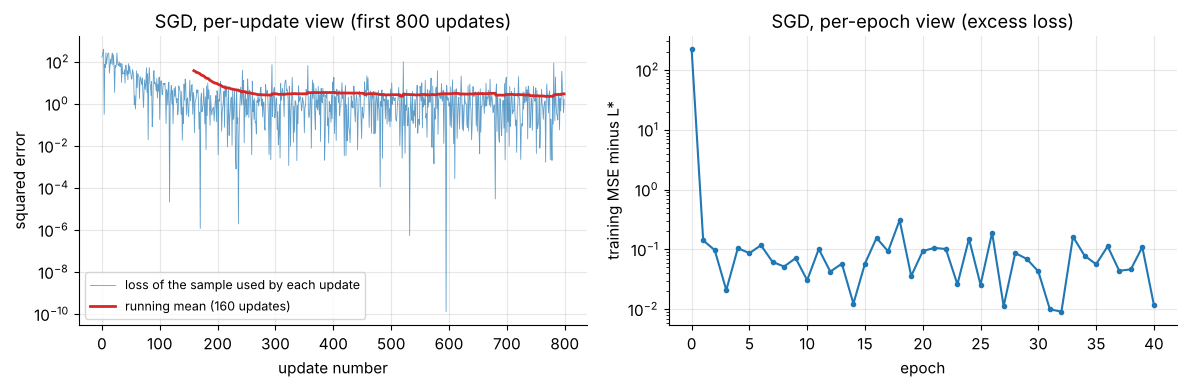

after 40 epochs: theta = [14.0285  3.6912  2.8224  0.0171], excess loss = 0.0118
mean excess over the last 10 epochs = 0.0643


In [27]:
theta_sgd, hist_sgd = train_linear_gd(Xb_train, y_train, lr=0.01, n_epochs=40, batch_size=1)
window = 160
running = np.convolve(hist_sgd["batch_loss"], np.ones(window) / window, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_sgd["batch_loss"][:800], lw=0.6, alpha=0.7, label="loss of the sample used by each update")
axes[0].plot(np.arange(window - 1, 800), running[:800 - window + 1], color="C3", lw=2, label=f"running mean ({window} updates)")
axes[0].set_yscale("log")
axes[0].set(xlabel="update number", ylabel="squared error", title="SGD, per-update view (first 800 updates)")
axes[0].legend(fontsize=9)
axes[1].plot(hist_sgd["epoch_loss"] - L_star, marker="o", ms=3)
axes[1].set_yscale("log")
axes[1].set(xlabel="epoch", ylabel="training MSE minus L*", title="SGD, per-epoch view (excess loss)")
fig.tight_layout()
plt.show()
print(f"after 40 epochs: theta = {np.round(theta_sgd, 4)}, excess loss = {hist_sgd['epoch_loss'][-1] - L_star:.4f}")
print(f"mean excess over the last 10 epochs = {np.mean(hist_sgd['epoch_loss'][-10:] - L_star):.4f}")

Three lessons from these two plots:

* The per-update loss spans many orders of magnitude, because each point is the error on one random
  market (sometimes that error happens to be almost exactly zero). It says little about progress.
  The running mean or the epoch-level loss does.
* The excess loss drops fast at first (one epoch already makes 160 updates) and then stops
  improving: it **jitters around a floor** instead of reaching $0$. With a constant learning rate,
  SGD keeps reacting to every single sample, and near the minimum those single-sample gradients are
  pure noise (they disagree with each other even though their average is zero). Section 4.4
  quantifies the noise and Section 4.7 removes the floor.
* The parameters are close to, but not exactly, the answer key $\boldsymbol\theta^\star$.

**Why reshuffle?** Our trainer draws a fresh random order every epoch. Imagine instead that the
rows arrive **sorted**, for example by date, by store size or, as we simulate below, by sales, and
that you loop over them in that fixed order. During each epoch the model first sees only low-sales
markets (and is pushed down), then only high-sales markets (and is pushed up). The parameters at the
end of every epoch are systematically biased toward the *last* samples visited.

sorted order, never shuffled  : excess loss at the end = 0.7918 (mean over last 10 epochs 0.7918), final bias = 14.491
reshuffled every epoch        : excess loss at the end = 0.0118 (mean over last 10 epochs 0.0643), final bias = 14.028


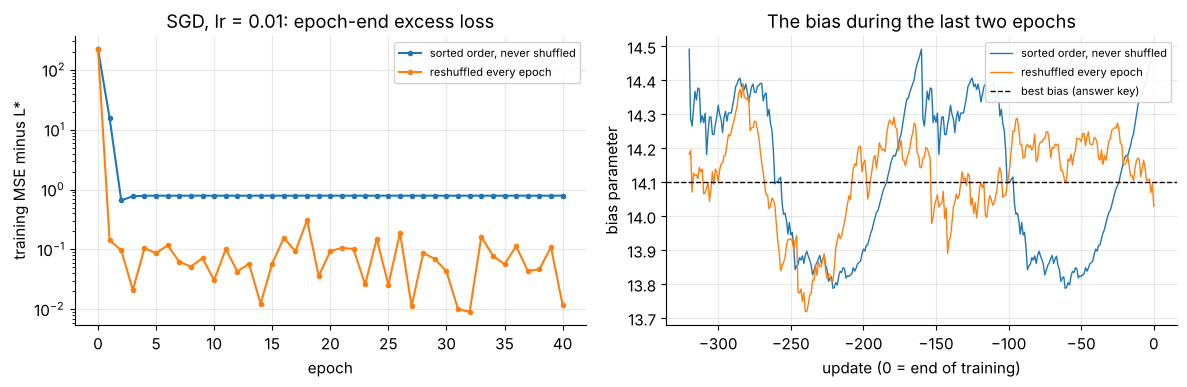

answer key: bias = 14.100


In [28]:
order_by_sales = np.argsort(y_train)                  # a dataset that arrives sorted by the target
runs_shuffle = {
    "sorted order, never shuffled": dict(shuffle=False, order=order_by_sales),
    "reshuffled every epoch": dict(shuffle=True),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, kw in runs_shuffle.items():
    th, h = train_linear_gd(Xb_train, y_train, lr=0.01, n_epochs=40, batch_size=1, record_path=True, **kw)
    axes[0].plot(h["epoch_loss"] - L_star, marker="o", ms=3, label=name)
    axes[1].plot(np.arange(-2 * len(y_train), 1), h["path"][-2 * len(y_train) - 1:, 0], lw=1, label=name)
    print(f"{name:30s}: excess loss at the end = {h['epoch_loss'][-1] - L_star:.4f} "
          f"(mean over last 10 epochs {np.mean(h['epoch_loss'][-10:] - L_star):.4f}), final bias = {th[0]:.3f}")
axes[1].axhline(theta_star[0], color="k", ls="--", lw=1, label="best bias (answer key)")
axes[0].set_yscale("log")
axes[0].set(xlabel="epoch", ylabel="training MSE minus L*", title="SGD, lr = 0.01: epoch-end excess loss")
axes[1].set(xlabel="update (0 = end of training)", ylabel="bias parameter", title="The bias during the last two epochs")
for ax in axes:
    ax.legend(fontsize=8, framealpha=0.9)
fig.tight_layout()
plt.show()
print(f"answer key: bias = {theta_star[0]:.3f}")

The sawtooth on the right tells the story: with the sorted order, the bias falls during the first
part of every epoch (low-sales markets) and climbs during the second part (high-sales markets), so
every epoch *ends* at the top of the tooth, well above the best value. Training converges to a
**cycle**, not to the minimum, and the epoch-end excess loss stays roughly ten times larger than
with reshuffling. Reshuffling turns this systematic, order-induced error into random noise that
partly cancels from epoch to epoch.

> **Common pitfall.** Real datasets are very often stored in a meaningful order (by time, by class
> label, by customer ID). Always shuffle the training rows for SGD and mini-batch training, and
> reshuffle every epoch. (The *opposite* rule holds for splitting time-series data into train and
> test sets, as Section 7 explains: there, order is information you must keep.)

### 4.4 Mini-batch gradient descent: the batch-size dial

A mini-batch gradient is an *average* of $B$ per-sample gradients. If the batch is a uniformly
random subset of the $N$ rows (drawn without replacement), it is an **unbiased** estimate of the full
gradient $\mathbf g$, and its noise follows the classic formula for the mean of a sample drawn from a
finite population:

$$
\mathbb E\,\bigl\lVert \mathbf g_B - \mathbf g\bigr\rVert^2 = \frac{\sigma^2}{B}\cdot\frac{N - B}{N - 1},
\qquad \sigma^2 = \frac1N\sum_{i=1}^N \bigl\lVert \mathbf g_i - \mathbf g\bigr\rVert^2,
$$

where $\mathbf g_i = 2e_i\tilde{\mathbf x}^{(i)}$ is the gradient of sample $i$ alone. Roughly: **noise
variance $\propto 1/B$**, and the "finite-population correction" $(N-B)/(N-1)$ makes it exactly $0$ for
$B = N$. Let us check the formula by brute force at $\boldsymbol\theta = \mathbf 0$.

In [29]:
def per_sample_grads(Xb, y, theta):
    """Rows are the per-sample gradients g_i = 2 e_i x_i, shape (m, d+1)."""
    return 2.0 * (Xb @ theta - y)[:, None] * Xb


G0 = per_sample_grads(Xb_train, y_train, np.zeros(4))
g_full = G0.mean(axis=0)
sigma2 = np.mean(np.sum((G0 - g_full) ** 2, axis=1))
N_train = len(y_train)
noise_rng = np.random.default_rng(SEED)
rows = []
for B in [1, 4, 16, 64, 160]:
    draws = np.array([G0[noise_rng.choice(N_train, B, replace=False)].mean(axis=0) for _ in range(3000)])
    rows.append({"batch size B": B,
                 "noise, simulated": np.mean(np.sum((draws - g_full) ** 2, axis=1)),
                 "noise, formula": sigma2 / B * (N_train - B) / (N_train - 1),
                 "signal ||g||^2": np.sum(g_full ** 2)})
display(pd.DataFrame(rows).set_index("batch size B").round(1))
G_star = per_sample_grads(Xb_train, y_train, theta_star)
print(f"at theta*: full gradient norm = {np.linalg.norm(G_star.mean(axis=0)):.1e}, "
      f"but single-sample noise sigma^2 = {np.mean(np.sum(G_star ** 2, axis=1)):.1f}")

,"noise, simulated","noise, formula",signal ||g||^2
batch size B,,,
1,3038.6,2986.5,898.8
4,753.4,732.5,898.8
16,174.1,169.0,898.8
64,27.7,28.2,898.8
160,0.0,0.0,898.8


at theta*: full gradient norm = 1.2e-14, but single-sample noise sigma^2 = 62.5


The formula matches the simulation. Far from the minimum (at $\boldsymbol\theta = \mathbf 0$) the
signal $\lVert\mathbf g\rVert^2 \approx 899$ is still *smaller* than the single-sample noise
($\approx 2{,}987$), yet SGD makes progress because the noise averages out over many steps. At the
minimum the signal is $0$ while the single-sample noise is about $62.5$: this is the noise floor we
saw in Section 4.3.

Now the practical question: with a fixed learning rate and a fixed number of **epochs** (passes over
the data), which batch size is best?

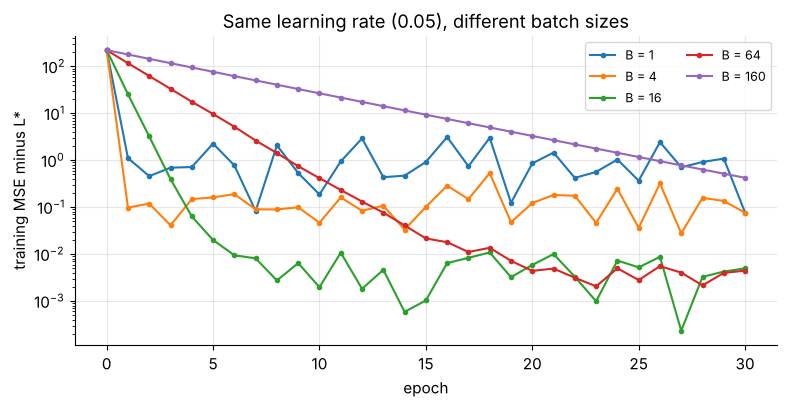

,updates per epoch,ms per epoch,excess after 1 epoch,excess after 5 epochs,"mean excess, epochs 21-30"
batch size B,,,,,
1,160,1.39,1.11,2.26,0.906
4,40,0.389,0.098,0.161,0.141
16,10,0.11,25.5,0.0199,0.00482
64,3,0.0441,117,9.66,0.0038
160,1,0.0243,179,76.7,1.25


In [30]:
batch_sizes = [1, 4, 16, 64, 160]
fig, ax = plt.subplots(figsize=(8, 4.2))
rows = []
for B in batch_sizes:
    t0 = time.perf_counter()
    th, h = train_linear_gd(Xb_train, y_train, lr=0.05, n_epochs=30, batch_size=B)
    sec_per_epoch = (time.perf_counter() - t0) / 30
    ax.plot(h["epoch_loss"] - L_star, marker="o", ms=3, label=f"B = {B}")
    rows.append({"batch size B": B, "updates per epoch": int(np.ceil(N_train / B)),
                 "ms per epoch": 1e3 * sec_per_epoch,
                 "excess after 1 epoch": h["epoch_loss"][1] - L_star,
                 "excess after 5 epochs": h["epoch_loss"][5] - L_star,
                 "mean excess, epochs 21-30": np.mean(h["epoch_loss"][21:] - L_star)})
ax.set_yscale("log")
ax.set(xlabel="epoch", ylabel="training MSE minus L*", title="Same learning rate (0.05), different batch sizes")
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
plt.show()
display(pd.DataFrame(rows).set_index("batch size B").apply(lambda col: col.map(lambda v: f"{v:.3g}")))

Small batches make **many cheap, noisy** steps per epoch, and large batches make **few expensive,
accurate** steps. With the same learning rate and 30 epochs:

* $B = 1$ makes good progress within the first epoch, then hovers around a high noise floor: near
  the minimum its 4,800 steps are dominated by noise. (Because single epoch-end values of a noisy run
  jump around, the table reports the *average* excess loss over the last 10 epochs.)
* Averaging $B$ gradients divides the noise variance by about $B$, and the floor drops with it (here
  even faster than $1/B$): about six times lower for $B = 4$, and more than a hundred times lower for
  $B = 16$ and $B = 64$, which end up best here.
* $B = 160$ (batch GD) has no noise at all but only 30 steps in total, and it is still far away.

The time column shows the other side of the coin. In pure NumPy, each update has a fixed Python
overhead, so an epoch of $B = 1$ costs dozens of times more wall-clock time than an epoch of
$B = 160$ (the exact factor depends on your machine and on how busy it is), even though both touch
every sample once. On GPUs the effect is even stronger, because a batch of 64 or 256 samples is
processed in parallel at nearly the cost of one. This is why mini-batches of a few dozen to a few
hundred samples are the default in deep learning.

**Quick check.** You switch from $B = 32$ to $B = 128$ on a dataset with $N = 10^6$ rows. Roughly how
does the variance of the gradient noise change, and how many updates per epoch do you lose?

<details><summary>Answer</summary>

The variance shrinks by a factor of about $4$ (it scales like $1/B$, and the correction $(N-B)/(N-1)$ is
essentially $1$ when $B \ll N$), so the standard deviation of the noise halves. Updates per epoch drop
from $31{,}250$ to $7{,}813$, also a factor of $4$.
</details>

### 4.5 Batch gradient descent and the learning rate

Batch gradient descent is deterministic: the same start and learning rate always give the same curve.
That makes it the cleanest place to study the learning rate. Section 3.7 predicts three regimes,
set by the eigenvalues of the Hessian printed in Section 4.1: progress is slow if $\eta$ is tiny, fastest
around $\eta = 2/(\lambda_{\max}+\lambda_{\min}) \approx 0.499$, oscillating near the limit, and
**divergent** beyond $\eta = 2/\lambda_{\max} \approx 0.717$.

lr = 0.050: excess loss after 10 epochs = 2.67e+01, after 60 epochs = 1.61e-03
lr = 0.200: excess loss after 10 epochs = 1.43e-02, after 60 epochs = 5.33e-15
lr = 0.499: excess loss after 10 epochs = 7.36e-08, after 60 epochs = 1.00e-16
lr = 0.700: excess loss after 10 epochs = 3.29e+00, after 60 epochs = 2.61e-02
lr = 0.730: excess loss after 10 epochs = 1.77e+01, after 60 epochs = 6.37e+02


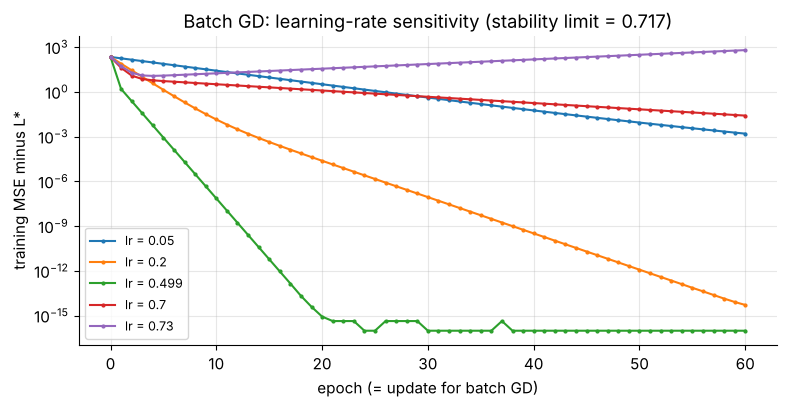

In [31]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for lr in [0.05, 0.2, LR_OPT, 0.70, 0.73]:
    th, h = train_linear_gd(Xb_train, y_train, lr=lr, n_epochs=60, batch_size=N_train)
    excess = np.maximum(h["epoch_loss"] - L_star, 1e-16)            # clip round-off below zero for the log axis
    ax.plot(excess, marker=".", ms=4, label=f"lr = {lr:.3g}")
    print(f"lr = {lr:.3f}: excess loss after 10 epochs = {excess[10]:.2e}, after 60 epochs = {excess[60]:.2e}")
ax.set_yscale("log")
ax.set(xlabel="epoch (= update for batch GD)", ylabel="training MSE minus L*",
       title=f"Batch GD: learning-rate sensitivity (stability limit = {LR_MAX:.3f})")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

Exactly as predicted. $\eta = 0.05$ crawls, $\eta = 0.2$ is decent, and $\eta \approx 0.499$ reaches
machine precision within a few dozen steps. $\eta = 0.70$, just below the limit, converges only slowly
because the steepest direction flips sign at every step and barely shrinks
($|1 - 0.70\cdot 2.79| \approx 0.95$), and $\eta = 0.73$, just above the limit, blows up.

> **Key idea.** The best constant learning rate sits *below* the stability limit, typically within a
> factor of 2 or 3 of it (here $0.499$ versus the limit $0.717$). Right at the edge ($0.70$) the
> steepest direction barely shrinks and training is slow. A practical recipe when you have no Hessian
> at hand: try learning rates on a log grid (0.001, 0.003, 0.01, 0.03, ...), find the largest one
> that does not diverge, and back off by a factor of 2 or 3.

### 4.6 Side by side, on comparable axes

Comparing loss curves of different variants is surprisingly easy to get wrong: SGD makes 160 updates
per epoch and batch GD makes one, so "loss versus iteration" and "loss versus epoch" tell different
stories. Below, each variant gets a sensible learning rate of its own (SGD $0.01$, mini-batch with
$B = 16$ $0.05$, batch $0.499$) and 40 epochs, and we plot the **full training loss** on both axes.

SGD (B=1, lr=0.01)          :  6400 updates, final excess = 1.2e-02, max |theta - theta*| = 0.0730
mini-batch (B=16, lr=0.05)  :   400 updates, final excess = 2.7e-03, max |theta - theta*| = 0.0507
batch (B=160, lr=0.499)     :    40 updates, final excess = 1.0e-16, max |theta - theta*| = 0.0000


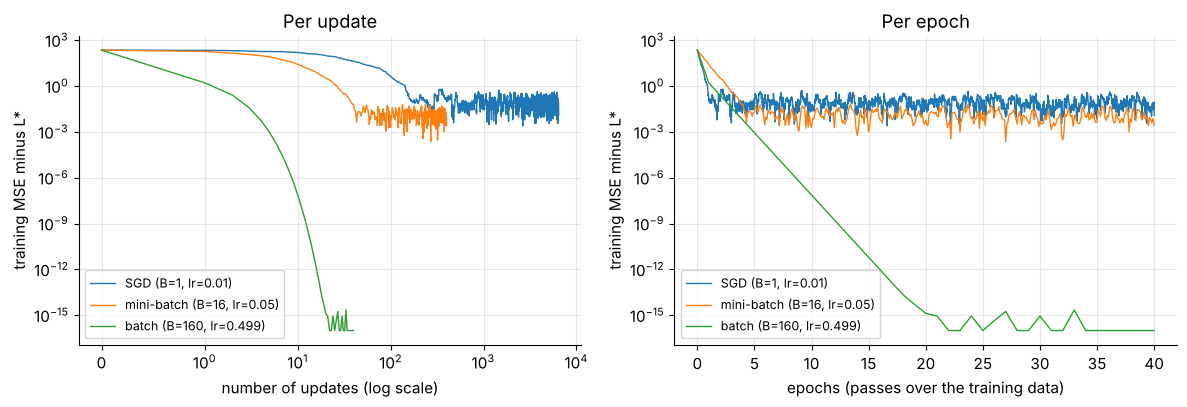

In [32]:
variants = {"SGD (B=1, lr=0.01)": (1, 0.01), "mini-batch (B=16, lr=0.05)": (16, 0.05),
            f"batch (B=160, lr={LR_OPT:.3f})": (N_train, LR_OPT)}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name, (B, lr) in variants.items():
    th, h = train_linear_gd(Xb_train, y_train, lr=lr, n_epochs=40, batch_size=B, record_path=True)
    excess_per_update = np.maximum(full_losses_along(Xb_train, y_train, h["path"]) - L_star, 1e-16)
    updates_per_epoch = int(np.ceil(N_train / B))
    axes[0].plot(np.arange(len(excess_per_update)), excess_per_update, lw=1, label=name)
    axes[1].plot(np.arange(len(excess_per_update)) / updates_per_epoch, excess_per_update, lw=1, label=name)
    print(f"{name:28s}: {len(h['batch_loss']):5d} updates, final excess = {excess_per_update[-1]:.1e}, "
          f"max |theta - theta*| = {np.abs(th - theta_star).max():.4f}")
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set(xlabel="number of updates (log scale)", title="Per update")
axes[1].set(xlabel="epochs (passes over the training data)", title="Per epoch")
for ax in axes:
    ax.set_yscale("log")
    ax.set_ylabel("training MSE minus L*")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

* **Per update**, batch GD is the clear winner: each of its steps uses exact gradient information.
  SGD needs far more steps to get anywhere.
* **Per epoch**, the picture changes at the start: after one pass over the data SGD has made 160
  small steps and its excess loss is already about $0.14$, while batch GD has made a single (large)
  step and sits at about $1.6$. Mini-batch GD, whose learning rate ($0.05$) is ten times smaller than
  batch GD's, is still at about $25$ after the first epoch and stays behind batch GD throughout. On
  this tiny, well-conditioned problem batch GD also overtakes SGD by the fourth epoch.
* In the long run, on this tiny problem, batch GD reaches the exact minimum (excess at round-off
  level), mini-batch GD hovers slightly above it and SGD hovers further above it.

For 160 rows, batch gradient descent (or simply the closed form) is the right tool. The case for
SGD and mini-batches is **large, redundant datasets**: when a random batch of 64 rows already points
almost in the same direction as the full gradient, it is wasteful to read all $N$ rows before taking
a single step. The next cell makes this concrete with a synthetic dataset of $N = 100{,}000$ rows and
$d = 20$ correlated features.

N = 100,000, d = 20, condition number = 11.0, L* = 0.9960


batch GD (lr=0.127)         : final excess = 3.86e-04; excess first below 1% of L* after 22 epochs
mini-batch B=64 (lr=0.02)   : final excess = 3.61e-03; excess first below 1% of L* after 0.113 epochs


SGD B=1 (lr=0.002)          : final excess = 3.05e-02; excess first below 1% of L* after never (in this run)


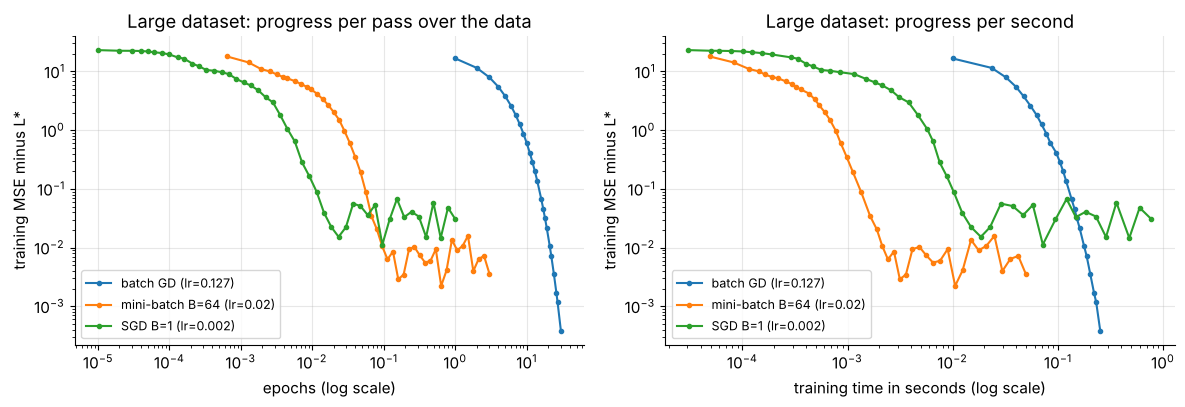

In [33]:
big_rng = np.random.default_rng(7)
N_big, d_big2 = 100_000, 20
shared = big_rng.normal(size=(N_big, 1))
Z_big = big_rng.normal(size=(N_big, d_big2)) + 0.7 * shared           # features share a common factor
Z_big = (Z_big - Z_big.mean(axis=0)) / Z_big.std(axis=0)
Xb_big = add_bias(Z_big)
y_big2 = Xb_big @ big_rng.normal(0, 1, d_big2 + 1) + big_rng.normal(0, 1.0, N_big)
theta_big_star = np.linalg.lstsq(Xb_big, y_big2, rcond=None)[0]
L_big_star = mse_loss(Xb_big, y_big2, theta_big_star)
lam_big = np.linalg.eigvalsh(2.0 / N_big * Xb_big.T @ Xb_big)
print(f"N = {N_big:,}, d = {d_big2}, condition number = {lam_big.max() / lam_big.min():.1f}, L* = {L_big_star:.4f}")


def train_with_checkpoints(Xb, y, lr, batch_size, n_epochs, L_ref, n_checks=50, seed=SEED):
    """Mini-batch GD that records (epochs done, excess loss, seconds of training) at log-spaced checkpoints."""
    rng = np.random.default_rng(seed)
    m = len(y)
    per_epoch = int(np.ceil(m / batch_size))
    checks = set(np.unique(np.geomspace(1, n_epochs * per_epoch, n_checks).astype(int)))
    theta, t, train_time = np.zeros(Xb.shape[1]), 0, 0.0
    log = [(0.0, mse_loss(Xb, y, theta) - L_ref, 0.0)]
    for _ in range(n_epochs):
        visit = rng.permutation(m)
        tick = time.perf_counter()
        for start in range(0, m, batch_size):
            idx = visit[start:start + batch_size]
            e = Xb[idx] @ theta - y[idx]
            theta = theta - lr * (2.0 / len(idx)) * (Xb[idx].T @ e)
            t += 1
            if t in checks:                                         # evaluation time is excluded
                train_time += time.perf_counter() - tick
                log.append((t / per_epoch, mse_loss(Xb, y, theta) - L_ref, train_time))
                tick = time.perf_counter()
        train_time += time.perf_counter() - tick
    return np.array(log)


big_runs = {
    f"batch GD (lr={2 / (lam_big.max() + lam_big.min()):.3f})": (N_big, 2 / (lam_big.max() + lam_big.min()), 30),
    "mini-batch B=64 (lr=0.02)": (64, 0.02, 3),
    "SGD B=1 (lr=0.002)": (1, 0.002, 1),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name, (B, lr, n_ep) in big_runs.items():
    log = train_with_checkpoints(Xb_big, y_big2, lr, B, n_ep, L_big_star)
    axes[0].plot(log[1:, 0], np.maximum(log[1:, 1], 1e-8), marker=".", label=name)
    axes[1].plot(log[1:, 2], np.maximum(log[1:, 1], 1e-8), marker=".", label=name)
    hit = np.flatnonzero(log[:, 1] < 0.01 * L_big_star)
    when = f"{log[hit[0], 0]:.3g} epochs" if len(hit) else "never (in this run)"
    print(f"{name:28s}: final excess = {log[-1, 1]:.2e}, excess first below 1% of L* after {when}")
for ax, xl in zip(axes, ["epochs (log scale)", "training time in seconds (log scale)"]):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set(xlabel=xl, ylabel="training MSE minus L*")
    ax.legend(fontsize=9)
axes[0].set_title("Large dataset: progress per pass over the data")
axes[1].set_title("Large dataset: progress per second")
fig.tight_layout()
plt.show()

On a large dataset the per-epoch picture decides the race. Mini-batch GD gets within $1\%$ of the
optimal loss after roughly a tenth of an epoch, while batch GD needs many full passes, because one
pass of mini-batch GD contains about 1,500 informative steps and one pass of batch GD contains one.
SGD is also fast at first but, with a learning rate small enough to be stable for single samples, it
stalls on its noise floor. Mini-batches combine the best of both: many steps per epoch, little noise
per step, and efficient vectorized (or GPU) arithmetic.

### 4.7 Going deeper: decaying the learning rate removes the noise floor

A constant learning rate leaves SGD bouncing around the minimum with a spread that grows with
$\eta$. The classic remedy is to **shrink the learning rate over time**, for example
$\eta_t = \eta_0/(1 + \gamma t)$ after $t$ updates. Big steps early make fast progress, and small steps
late average out the noise. In theory SGD converges to the exact minimum when
$\sum_t \eta_t = \infty$ (the steps can still travel any distance) and $\sum_t \eta_t^2 < \infty$ (the
accumulated noise stays finite), which $\eta_0/(1+\gamma t)$ satisfies.

constant lr = 0.02        : excess after 5 epochs = 4.07e-01, after 40 epochs = 4.94e-02
constant lr = 0.005       : excess after 5 epochs = 1.80e-02, after 40 epochs = 4.67e-03
lr = 0.02 / (1 + 0.01 t)  : excess after 5 epochs = 2.57e-03, after 40 epochs = 7.34e-06


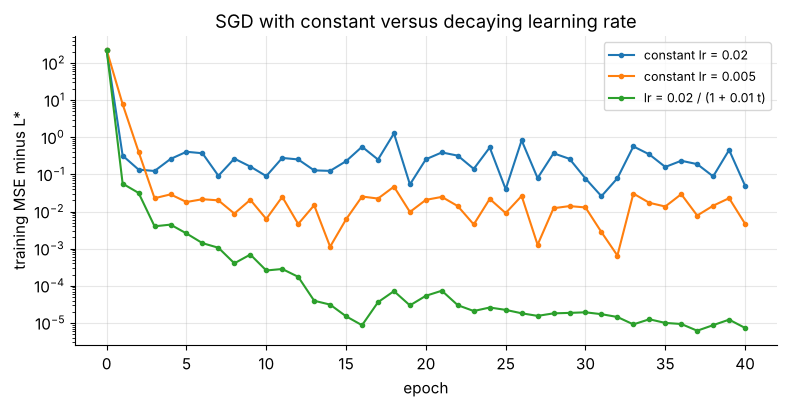

In [34]:
fig, ax = plt.subplots(figsize=(8, 4.2))
decay_runs = {"constant lr = 0.02": (0.02, 0.0), "constant lr = 0.005": (0.005, 0.0),
              "lr = 0.02 / (1 + 0.01 t)": (0.02, 0.01)}
for name, (lr, gamma) in decay_runs.items():
    th, h = train_linear_gd(Xb_train, y_train, lr=lr, n_epochs=40, batch_size=1, lr_decay=gamma)
    ax.plot(h["epoch_loss"] - L_star, marker="o", ms=3, label=name)
    print(f"{name:26s}: excess after 5 epochs = {h['epoch_loss'][5] - L_star:.2e}, after 40 epochs = {h['epoch_loss'][40] - L_star:.2e}")
ax.set_yscale("log")
ax.set(xlabel="epoch", ylabel="training MSE minus L*", title="SGD with constant versus decaying learning rate")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

The large constant rate is fast but stuck high, and the small constant rate is slow and also has a
floor (lower, because the floor shrinks with $\eta$). The decaying schedule starts as fast as the
large rate and keeps improving by orders of magnitude. Modern deep-learning schedules (step decay,
cosine decay, warm-up) are refinements of this idea.

### 4.8 Everyone agrees: gradient descent, closed form and scikit-learn

Finally, let us train each variant properly (batch GD with its best rate, mini-batch and SGD with a
decaying rate) and compare with the closed form and with scikit-learn's `LinearRegression` (exact
least squares) and `SGDRegressor` (per-sample SGD with its own decaying schedule, where `penalty=None`
switches off the regularization it would otherwise add).

In [35]:
from sklearn.linear_model import LinearRegression, SGDRegressor

fits = {"closed form (lstsq)": theta_star}
fits["batch GD"] = train_linear_gd(Xb_train, y_train, lr=LR_OPT, n_epochs=60, batch_size=N_train)[0]
fits["mini-batch GD (B=16, decay)"] = train_linear_gd(Xb_train, y_train, lr=0.05, n_epochs=60, batch_size=16, lr_decay=0.01)[0]
fits["SGD (decay)"] = train_linear_gd(Xb_train, y_train, lr=0.02, n_epochs=60, batch_size=1, lr_decay=0.01)[0]
sk_ols = LinearRegression().fit(Xb_train[:, 1:], y_train)                  # sklearn adds its own intercept
fits["sklearn LinearRegression"] = np.r_[sk_ols.intercept_, sk_ols.coef_]
sk_sgd = SGDRegressor(penalty=None, max_iter=1000, tol=1e-6, random_state=SEED).fit(Xb_train[:, 1:], y_train)
fits["sklearn SGDRegressor"] = np.r_[sk_sgd.intercept_, sk_sgd.coef_]

comparison = pd.DataFrame(fits, index=["bias", "TV", "Radio", "Newspaper"]).T
comparison["train MSE"] = [mse_loss(Xb_train, y_train, th) for th in fits.values()]
comparison["test MSE"] = [mse_loss(Xb_test, y_test, th) for th in fits.values()]
display(comparison.round(4))

,bias,TV,Radio,Newspaper,train MSE,test MSE
closed form (lstsq),14.1000,3.7642,2.7923,0.0560,2.7051,3.1741
batch GD,14.1000,3.7642,2.7923,0.0560,2.7051,3.1741
"mini-batch GD (B=16, decay)",14.0999,3.7658,2.7916,0.0559,2.7051,3.1724
SGD (decay),14.0995,3.7649,2.7924,0.0565,2.7051,3.1739
sklearn LinearRegression,14.1000,3.7642,2.7923,0.0560,2.7051,3.1741
sklearn SGDRegressor,14.0984,3.7675,2.7874,0.0594,2.7052,3.1723


All six parameter vectors agree to about two decimals or better, and their training and test errors
are practically identical. The exact closed form and batch GD agree to every printed digit, and the
stochastic methods stop a hair away, as expected. Once you know the variants *can* reach the same
answer, the choice between them is about cost, memory and data size, and Section 9 summarizes it in a
table.

In [36]:
# ✏️ Exercise 5: a reusable mini-batch generator
def iterate_minibatches(X, y, batch_size, rng=None, drop_last=False):
    """Yield (X_batch, y_batch) pairs that together cover every row of X (m, d) and y (m,) once.

    rng=None: keep the original row order. Otherwise use rng.permutation(m) to shuffle the rows first.
    The last batch may be smaller than batch_size, and with drop_last=True it is skipped instead.
    If batch_size >= m there is a single batch containing all rows."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    X = np.arange(20, dtype=float).reshape(10, 2)
    y = np.arange(10, dtype=float)
    batches = list(iterate_minibatches(X, y, 4))
    assert [len(yb) for _, yb in batches] == [4, 4, 2], f"batch sizes should be [4, 4, 2], got {[len(yb) for _, yb in batches]}"
    assert np.array_equal(np.concatenate([yb for _, yb in batches]), y), "with rng=None the original order must be kept"
    assert all(np.array_equal(xb[:, 0], 2 * yb) for xb, yb in batches), "X rows and y values got separated"
    assert [len(yb) for _, yb in iterate_minibatches(X, y, 4, drop_last=True)] == [4, 4], "drop_last should skip the short batch"
    shuffled = list(iterate_minibatches(X, y, 3, rng=np.random.default_rng(0)))
    ys = np.concatenate([yb for _, yb in shuffled])
    assert sorted(ys) == list(y) and not np.array_equal(ys, y), "with an rng, rows must be a shuffled permutation"
    again = np.concatenate([yb for _, yb in iterate_minibatches(X, y, 3, rng=np.random.default_rng(0))])
    assert np.array_equal(ys, again), "the same seed should give the same batches"
    assert len(list(iterate_minibatches(X, y, 50))) == 1, "batch_size >= m should give one batch"


run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def iterate_minibatches(X, y, batch_size, rng=None, drop_last=False):
    m = len(y)
    order = np.arange(m) if rng is None else rng.permutation(m)
    for start in range(0, m, batch_size):
        idx = order[start:start + batch_size]
        if drop_last and len(idx) < batch_size:
            break
        yield X[idx], y[idx]
```
Shuffling an *index* array (instead of X and y separately) keeps every row paired with its target.
A generator (`yield`) produces one batch at a time, so a training loop can write
`for X_b, y_b in iterate_minibatches(X, y, 32, rng): ...`.
</details>

In [37]:
# ✏️ Exercise 6: learning-rate limits from the Hessian
def lr_limits(Xb):
    """For the MSE of a linear model with design matrix Xb (m, d+1), return (lr_max, lr_best):
    lr_max  = 2 / lambda_max                  (largest learning rate for which batch GD is stable)
    lr_best = 2 / (lambda_max + lambda_min)   (best constant learning rate),
    where lambda are the eigenvalues of the Hessian H = (2/m) Xb^T Xb. Use np.linalg.eigvalsh."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    lr_max, lr_best = lr_limits(Xb_train)
    assert abs(lr_max - 0.71693) < 1e-4 and abs(lr_best - 0.49871) < 1e-4, f"got {lr_max}, {lr_best}"
    g = np.random.default_rng(5)
    Xr = add_bias(g.normal(size=(200, 3)) * [1.0, 3.0, 0.2])
    yr = Xr @ np.array([1.0, -2.0, 0.5, 3.0]) + g.normal(size=200)
    lr_max, lr_best = lr_limits(Xr)
    assert lr_best < lr_max, "the best constant rate is always below the stability limit"
    for factor, should_diverge in [(0.98, False), (1.02, True)]:
        theta = np.zeros(4)
        for _ in range(3000):
            theta -= factor * lr_max * mse_grad(Xr, yr, theta)
        diverged = not np.isfinite(theta).all() or np.abs(theta).max() > 1e6
        assert diverged == should_diverge, f"batch GD at {factor} x lr_max should {'diverge' if should_diverge else 'converge'}"


run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def lr_limits(Xb):
    lam = np.linalg.eigvalsh(2.0 / len(Xb) * Xb.T @ Xb)
    return 2.0 / lam.max(), 2.0 / (lam.max() + lam.min())
```
`eigvalsh` is the right tool for symmetric matrices (it returns real eigenvalues in ascending order).
Just below `lr_max` every factor $|1-\eta\lambda_k|$ is below $1$, and just above it, the steepest direction
is multiplied by a number slightly larger than $1$ in absolute value at every step and explodes.
</details>

---
## 5. Measuring regression quality

The training loss tells the optimizer what to do, and **metrics** tell *people* how good the model is.
Different metrics answer different questions, and each can mislead in its own way. Throughout,
$y_i$ are true values, $\hat y_i$ predictions, $e_i = \hat y_i - y_i$ errors, $n$ the number of
evaluated samples and $\bar y$ the mean of the true values.

### 5.1 Errors in the target's own units: MSE, RMSE, MAE

$$
\text{MSE} = \frac1n\sum_{i=1}^n e_i^2, \qquad
\text{RMSE} = \sqrt{\text{MSE}}, \qquad
\text{MAE} = \frac1n\sum_{i=1}^n |e_i| .
$$

**Worked example.** Five true values and predictions:

| $i$ | $y_i$ | $\hat y_i$ | $e_i$ | $e_i^2$ | $\lvert e_i\rvert$ | $\lvert e_i\rvert / y_i$ |
|---|---|---|---|---|---|---|
| 1 | 3 | 4 | 1 | 1 | 1 | 0.3333 |
| 2 | 5 | 5 | 0 | 0 | 0 | 0 |
| 3 | 8 | 6 | $-2$ | 4 | 2 | 0.25 |
| 4 | 10 | 11 | 1 | 1 | 1 | 0.1 |
| 5 | 14 | 19 | 5 | 25 | 5 | 0.3571 |
| **sum** | 40 | | | 31 | 9 | 1.0405 |

So MSE $= 31/5 = 6.2$, RMSE $= \sqrt{6.2} \approx 2.490$ and MAE $= 9/5 = 1.8$.

* **MSE** is in *squared* units ("squared thousands of units"), which is awkward to report, but it is
  the quantity we minimize, and it is smooth.
* **RMSE** is back in the target's units. It is a "typical error" that gives extra weight to large
  errors: the single error of $5$ contributes $25$ of the $31$ in the sum.
* **MAE** is the plain average size of an error and is much less influenced by one large error.
* Always $\text{RMSE} \ge \text{MAE}$ (the quadratic mean is at least the arithmetic mean), with
  equality only when all $|e_i|$ are equal. A big gap between them means a few large errors dominate.

> **Olympiad tip.** If a model may only predict one constant $c$ for every sample, the $c$ minimizing
> the MSE is the **mean** of the $y_i$, while the $c$ minimizing the MAE is the **median**. (For
> MSE, set the derivative $\frac{2}{n}\sum(c - y_i)$ to zero. For MAE, moving $c$ to the right
> changes $\sum|c - y_i|$ at rate $\#\{y_i < c\} - \#\{y_i > c\}$, which is negative below the median and
> positive above it.) This is why squared error is "pulled" by outliers and absolute error is not.

### 5.2 MAPE: a percentage error, and why it breaks near zero

$$
\text{MAPE} = \frac{100\%}{n}\sum_{i=1}^n \frac{|e_i|}{|y_i|}.
$$

In the worked example MAPE $= 100\% \cdot 1.0405/5 \approx 20.81\%$. MAPE is popular because it is
scale-free and easy to communicate ("we are off by about 21% on average"). But it has three serious
problems:

1. **It explodes near zero.** The same absolute error of $0.3$ is a $7.5\%$ error when $y = 4$ but a
   $600\%$ error when $y = 0.05$, and it is undefined when $y = 0$. Never use MAPE for targets that
   can be zero or change sign (temperatures in °C, profits, *returns* of an asset).
2. **It is asymmetric.** Under-predicting can cost at most $100\%$ (predict $0$), over-predicting has
   no upper limit. Models tuned on MAPE learn to under-predict.
3. **It weights samples by $1/|y_i|$.** When the target spans orders of magnitude (prices over many
   years), MAPE is dominated by the samples with the smallest values. You will see this in Section 7.

The next cell checks the worked example with scikit-learn and demonstrates points 1 and 2.

In [38]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score

y_ex = np.array([3.0, 5.0, 8.0, 10.0, 14.0])
y_ex_hat = np.array([4.0, 5.0, 6.0, 11.0, 19.0])
print(f"MSE  = {mean_squared_error(y_ex, y_ex_hat):.4f}")
print(f"RMSE = {np.sqrt(mean_squared_error(y_ex, y_ex_hat)):.4f}")
print(f"MAE  = {mean_absolute_error(y_ex, y_ex_hat):.4f}")
print(f"MAPE = {100 * mean_absolute_percentage_error(y_ex, y_ex_hat):.2f}%   (scikit-learn returns a fraction, not a percent)")
print(f"R^2  = {r2_score(y_ex, y_ex_hat):.4f}")

y_small_vals = np.array([4.0, 2.0, 1.0, 0.5, 0.05])
print("\nsame absolute error 0.3 on targets", y_small_vals, "-> percentage errors", np.round(100 * 0.3 / y_small_vals, 1))

c_grid = np.linspace(y_train.min(), y_train.max(), 2001)
best_c = {name: c_grid[np.argmin([f(np.full_like(y_train, c)) for c in c_grid])]
          for name, f in [("MSE", lambda p: np.mean((p - y_train) ** 2)),
                          ("MAE", lambda p: np.mean(np.abs(p - y_train))),
                          ("MAPE", lambda p: np.mean(np.abs(p - y_train) / y_train))]}
print("\nbest constant prediction of advertising sales under each metric:",
      {k: round(float(v), 2) for k, v in best_c.items()},
      f"| mean = {y_train.mean():.2f}, median = {np.median(y_train):.2f}")

MSE  = 6.2000
RMSE = 2.4900
MAE  = 1.8000
MAPE = 20.81%   (scikit-learn returns a fraction, not a percent)
R^2  = 0.5811

same absolute error 0.3 on targets [4.   2.   1.   0.5  0.05] -> percentage errors [  7.5  15.   30.   60.  600. ]

best constant prediction of advertising sales under each metric: {'MSE': 14.1, 'MAE': 13.21, 'MAPE': 11.51} | mean = 14.10, median = 13.20


The constant that minimizes MAPE ($\approx 11.5$) sits well *below* both the mean ($14.1$) and the
median ($13.2$): MAPE rewards under-prediction. If you need a percentage-style metric, consider
alternatives such as the symmetric MAPE, or (for time series) the **MASE**, which divides the MAE by
the MAE of a naive "repeat the last value" forecast. That last idea, comparing against a simple
baseline, is the backbone of Section 7.

### 5.3 The coefficient of determination $R^2$

$$
R^2 = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}}
    = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}.
$$

$\text{SS}_{\text{tot}}$ is the squared error of the laziest possible model, "always predict the mean
$\bar y$". So $R^2$ is **the fraction of that baseline's squared error that the model removes**. In
the worked example $\bar y = 8$, $\text{SS}_{\text{tot}} = 25 + 9 + 0 + 4 + 36 = 74$,
$\text{SS}_{\text{res}} = 31$, and $R^2 = 1 - 31/74 \approx 0.581$.

* $R^2 = 1$: perfect predictions. $R^2 = 0$: no better than the mean. $R^2 < 0$: *worse* than the
  mean, which is perfectly possible on test data.
* On the **training** data of a least-squares fit with an intercept, $0 \le R^2 \le 1$ and $R^2$
  equals the squared correlation between $y$ and $\hat y$. (In simple regression it is $r^2$.)
* $R^2$ is unitless, which is convenient, but it **depends on how spread out the target is** in the
  evaluation set. The same RMSE gives a high $R^2$ when $y$ varies a lot and a low $R^2$ when it varies
  little. A target that drifts over time (a price over ten years) has an enormous
  $\text{SS}_{\text{tot}}$, so almost any model that "follows along" gets $R^2 \approx 1$. Keep this in
  mind for Section 7.

### 5.4 Adjusted $R^2$, and features made of pure noise

Adding a feature to a least-squares model can never increase the *training* error (the old solution
is still available by giving the new feature weight $0$), so training $R^2$ never goes down, even if
the new feature is pure noise. **Adjusted $R^2$** charges a price for every feature:

$$
R^2_{\text{adj}} = 1 - (1 - R^2)\,\frac{n - 1}{n - p - 1},
$$

where $p$ is the number of features (not counting the intercept). In the worked example, treating it
as a model with $p = 1$ feature, $R^2_{\text{adj}} = 1 - 0.419 \cdot 4/3 \approx 0.441$. Let us
add columns of random noise to the advertising features and watch three numbers.

,train R^2,adjusted R^2 (train),test R^2
noise features,,,
0,0.8957,0.8937,0.8994
5,0.9049,0.8999,0.9005
10,0.9111,0.9032,0.8747
20,0.9161,0.9019,0.8834
40,0.9254,0.8977,0.8315
60,0.9431,0.9057,0.8220


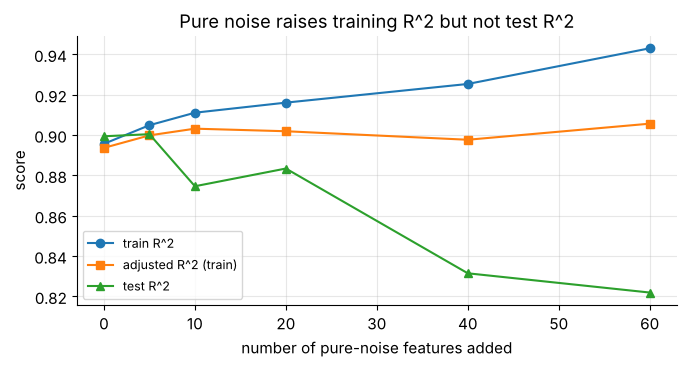

In [39]:
def adjusted_r2(r2, n, p):
    """Adjusted R^2 for n samples and p features (intercept not counted)."""
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


noise_rng = np.random.default_rng(SEED)
noise_train = noise_rng.normal(size=(len(y_train), 60))
noise_test = noise_rng.normal(size=(len(y_test), 60))
rows = []
for k in [0, 5, 10, 20, 40, 60]:
    Xtr_k = np.column_stack([X_train_raw, noise_train[:, :k]])
    Xte_k = np.column_stack([X_test_raw, noise_test[:, :k]])
    theta_k = np.linalg.lstsq(add_bias(Xtr_k), y_train, rcond=None)[0]
    r2_tr = r2_score(y_train, add_bias(Xtr_k) @ theta_k)
    rows.append({"noise features": k, "train R^2": r2_tr,
                 "adjusted R^2 (train)": adjusted_r2(r2_tr, len(y_train), 3 + k),
                 "test R^2": r2_score(y_test, add_bias(Xte_k) @ theta_k)})
noise_table = pd.DataFrame(rows).set_index("noise features")
display(noise_table.round(4))

fig, ax = plt.subplots(figsize=(7, 3.8))
for col, mk in zip(noise_table.columns, ["o", "s", "^"]):
    ax.plot(noise_table.index, noise_table[col], marker=mk, label=col)
ax.set(xlabel="number of pure-noise features added", ylabel="score",
       title="Pure noise raises training R^2 but not test R^2")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

Training $R^2$ rises steadily (from about $0.896$ to $0.943$) although the new columns carry no
information at all, and the model is fitting the noise in this particular training set. Test $R^2$
tells the truth and *falls* (from about $0.899$ to $0.822$). Adjusted $R^2$ stays roughly flat: it
removes the systematic upward drift, but it is not a substitute for held-out data. (One can show it
goes up exactly when the added feature's $|t|$-statistic exceeds $1$, which pure noise achieves by
luck about a third of the time.)

### 5.5 Which metric when?

| metric | units | outliers | use it for | misleading when |
|---|---|---|---|---|
| MSE | target$^2$ | very sensitive | training loss and comparing models on the same data | you need an interpretable number |
| RMSE | target | sensitive | reporting a typical error when big errors are costly | a few huge errors dominate |
| MAE | target | robust | reporting a typical error when costs grow linearly | large errors are much worse than small ones |
| MAPE | % | n/a | communicating relative error when $y$ stays well above $0$ | $y$ near $0$, or targets spanning orders of magnitude |
| $R^2$ | none | sensitive | "how much better than predicting the mean?" | the target trends or drifts, or tiny test sets |
| adjusted $R^2$ | none | sensitive | comparing in-sample fits with different numbers of features | used instead of a test set |

Report **more than one** metric, always on **held-out** data, and always next to a **baseline**
(the mean, the last value, last year's number): a metric means little until you know what a trivial
model scores.

In [40]:
# ✏️ Exercise 7: a regression report card
def regression_report(y_true, y_pred, n_features):
    """Return a dict with keys "MSE", "RMSE", "MAE", "MAPE", "R2", "adj_R2" (all Python floats).

    MAPE is in PERCENT and, like scikit-learn, divides by max(|y_true|, eps) with eps = np.finfo(float).eps.
    R2 uses the mean of y_true, and adj_R2 uses n = len(y_true) and p = n_features. Use NumPy only."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    rep = regression_report(y_ex, y_ex_hat, n_features=1)
    expected = {"MSE": 6.2, "RMSE": 6.2 ** 0.5, "MAE": 1.8, "MAPE": 20.8095238, "R2": 1 - 31 / 74, "adj_R2": 1 - (31 / 74) * 4 / 3}
    for key, val in expected.items():
        assert key in rep, f"missing key {key!r}"
        assert abs(rep[key] - val) < 1e-6, f"{key}: expected {val:.6f}, got {rep[key]}"
        assert isinstance(rep[key], float), f"{key} should be a Python float"
    g = np.random.default_rng(11)
    yt, yp = g.uniform(1, 10, 50), g.uniform(1, 10, 50)
    rep = regression_report(yt, yp, n_features=3)
    assert np.isclose(rep["MAPE"], 100 * mean_absolute_percentage_error(yt, yp)), "MAPE disagrees with scikit-learn"
    assert np.isclose(rep["R2"], r2_score(yt, yp)), "R2 disagrees with scikit-learn (can be negative!)"
    rep0 = regression_report(np.array([0.0, 2.0]), np.array([0.1, 2.0]), n_features=0)
    assert np.isfinite(rep0["MAPE"]) and rep0["MAPE"] > 1e10, "a zero target should give a huge but finite MAPE"


run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def regression_report(y_true, y_pred, n_features):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    e = y_pred - y_true
    n = len(y_true)
    mse = float(np.mean(e ** 2))
    eps = np.finfo(float).eps
    mape = float(100 * np.mean(np.abs(e) / np.maximum(np.abs(y_true), eps)))
    r2 = float(1 - np.sum(e ** 2) / np.sum((y_true - y_true.mean()) ** 2))
    adj = float(1 - (1 - r2) * (n - 1) / (n - n_features - 1))
    return {"MSE": mse, "RMSE": float(np.sqrt(mse)), "MAE": float(np.mean(np.abs(e))),
            "MAPE": mape, "R2": r2, "adj_R2": adj}
```
Note how a target of exactly $0$ produces a MAPE around $10^{16}\%$ in the last check (an error of
$0.1$ divided by `eps` $\approx 2.2\times10^{-16}$): a dramatic reminder of problem 1 in Section 5.2.
</details>

---
## 6. The advertising model, interpreted

### 6.1 Final scores, next to a baseline

Time to open the test set we locked away in Section 1. The model is the least-squares fit from
Section 4 ($\boldsymbol\theta^\star$ on z-scored features), and the baseline always predicts the mean
sales of the *training* markets.

In [41]:
def score_table(y_true_by_split, y_pred_by_split, n_features):
    """Metrics (RMSE, MAE, MAPE %, R^2, adjusted R^2) for several splits, as a DataFrame.

    Adjusted R^2 corrects the optimism of an in-sample fit, so it is reported for the "train" split only."""
    rows = {}
    for split, y_true in y_true_by_split.items():
        y_pred = y_pred_by_split[split]
        r2 = r2_score(y_true, y_pred)
        rows[split] = {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
                       "MAE": mean_absolute_error(y_true, y_pred),
                       "MAPE %": 100 * mean_absolute_percentage_error(y_true, y_pred),
                       "R^2": r2,
                       "adj R^2": adjusted_r2(r2, len(y_true), n_features) if split == "train" else np.nan}
    return pd.DataFrame(rows).T


truth = {"train": y_train, "test": y_test}
scores_linear = score_table(truth, {"train": Xb_train @ theta_star, "test": Xb_test @ theta_star}, n_features=3)
scores_mean = score_table(truth, {s: np.full_like(v, y_train.mean()) for s, v in truth.items()}, n_features=0)
display(pd.concat({"linear model": scores_linear, "baseline: training mean": scores_mean}).round(4))

RMSE     MAE   MAPE %     R^2  adj R^2
linear model            train  1.6447  1.1985  13.6515  0.8957   0.8937
                        test   1.7816  1.4608  15.1988  0.8994      NaN
baseline: training mean train  5.0928  4.1200  39.3263  0.0000   0.0000
                        test   5.6315  4.9625  44.4250 -0.0048      NaN

On new markets the model is off by about $1.78$ thousand units (RMSE) or $1.46$ (MAE), roughly $15\%$,
and explains about $90\%$ of the variance ($R^2 \approx 0.899$). The training scores are similar, so
there is no sign of overfitting (with only 4 parameters and 160 samples that would be surprising).
The baseline's test $R^2$ is slightly *negative*: the training mean is not exactly the test mean.
The adjusted $R^2$ is shown for the training split only: it corrects the optimism of an *in-sample*
fit (Section 5.4), whereas the plain test $R^2$ is already an honest score, so the test cell stays
empty (`NaN`).

### 6.2 What the coefficients say

Converted to original units (Section 3.9), the fitted model is

$$
\widehat{\text{Sales}} \approx 2.979 + 0.0447\,\text{TV} + 0.1892\,\text{Radio} + 0.0028\,\text{Newspaper}.
$$

* $w_{\text{TV}} \approx 0.0447$: an extra $1{,}000$ dollars of TV advertising goes with about $45$ more
  units sold, **holding Radio and Newspaper fixed**.
* $w_{\text{Radio}} \approx 0.189$: an extra $1{,}000$ dollars of radio goes with about $189$ more units:
  per dollar, radio looks about four times as effective as TV.
* $w_{\text{Newspaper}} \approx 0.003$: essentially nothing.
* $b \approx 2.98$: predicted sales with no advertising at all (an extrapolation: few training
  markets have budgets near zero for all three channels at once).

Raw coefficients answer "what does one more dollar do?". To compare *importance*, use the coefficients
on z-scored features, $\theta_{TV} \approx 3.76$, $\theta_{Radio} \approx 2.79$,
$\theta_{News} \approx 0.06$: the effect of a typical (one standard deviation) change in each budget.
TV wins here because TV budgets vary much more across markets.

How sure are we about these numbers? The `statsmodels` library reports, for every coefficient, a
**standard error** (roughly: how much the estimate would wobble if we collected 160 *new* markets)
and a $p$-value for the hypothesis "the true coefficient is $0$".

In [42]:
import statsmodels.api as sm

ols_sm = sm.OLS(y_train, add_bias(X_train_raw)).fit()
inference = pd.DataFrame({"coefficient": ols_sm.params, "std. error": ols_sm.bse,
                          "t = coef / se": ols_sm.tvalues, "p-value": ols_sm.pvalues},
                         index=["intercept"] + FEATURES)
display(inference.round(4))
news_alone = np.linalg.lstsq(add_bias(adv_train[["Newspaper"]].to_numpy()), y_train, rcond=None)[0]
print(f"Newspaper ALONE (simple regression): slope = {news_alone[1]:.4f} per thousand dollars")
print(f"correlation of Newspaper with Radio in the training set: {adv_train['Newspaper'].corr(adv_train['Radio']):.3f}")

,coefficient,std. error,t = coef / se,p-value
intercept,2.9791,0.3535,8.4270,0.0000
TV,0.0447,0.0016,28.5436,0.0000
Radio,0.1892,0.0097,19.5180,0.0000
Newspaper,0.0028,0.0070,0.3918,0.6958


Newspaper ALONE (simple regression): slope = 0.0598 per thousand dollars
correlation of Newspaper with Radio in the training set: 0.388


TV and Radio have huge $t$-statistics (their effects are many standard errors away from $0$). The
Newspaper coefficient is smaller than its own standard error ($p \approx 0.70$), so the data are
consistent with "newspaper ads do nothing". Yet on its own, Newspaper has a clearly positive slope of
about $0.06$, more than twenty times larger! The explanation is the correlation we spotted in the EDA:
markets that spend on newspapers also tend to spend on radio. A simple regression gives Newspaper
credit for Radio's effect, and the multiple regression, which compares markets **with the same radio
budget**, takes that credit away. This is called **confounding**, and it is the main reason to fit
all features jointly instead of one at a time.

> **Common pitfall.** A regression coefficient describes an *association, holding the other
> features fixed*, in the data you have. It is not automatically a *causal* effect: if markets that
> buy more radio also differ in ways we did not measure (population, income), part of Radio's
> coefficient may belong to those hidden factors. Causal claims need experiments or careful
> causal-inference methods.

### 6.3 Residual analysis: let the errors talk

A **residual** is $y_i - \hat y_i$ (actual minus predicted). If the model captured all the structure,
residuals would look like structureless noise: no trend against the fitted values, no pattern against
any feature. Patterns are clues about what the model is missing.

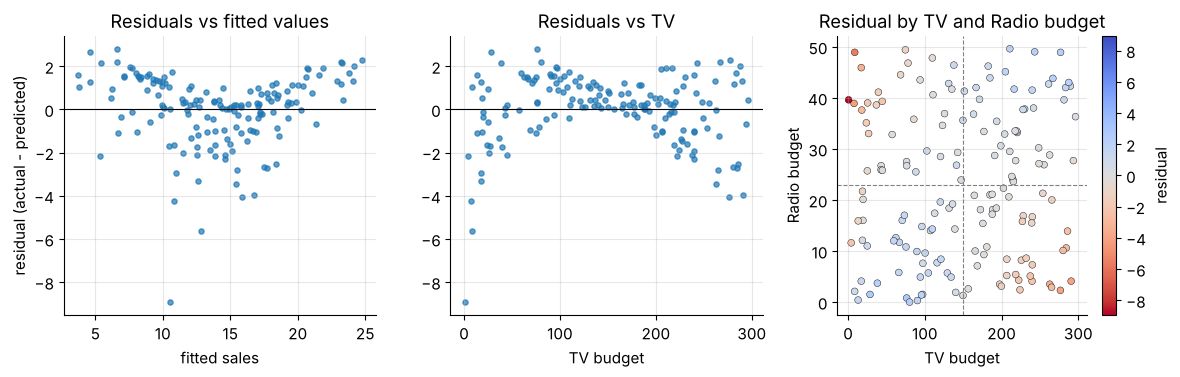

mean residual where TV and Radio are on the SAME side of their averages: +0.96 (83 markets)
mean residual where they are on OPPOSITE sides:                     -1.03 (77 markets)
correlation of the residual with (TV - mean)(Radio - mean): 0.82


In [43]:
fitted_train = Xb_train @ theta_star
resid_train = y_train - fitted_train
tv_tr, radio_tr = adv_train["TV"].to_numpy(), adv_train["Radio"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
axes[0].scatter(fitted_train, resid_train, s=14, alpha=0.7)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(xlabel="fitted sales", ylabel="residual (actual - predicted)", title="Residuals vs fitted values")
axes[1].scatter(tv_tr, resid_train, s=14, alpha=0.7)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="TV budget", title="Residuals vs TV")
lim = np.abs(resid_train).max()
sc = axes[2].scatter(tv_tr, radio_tr, c=resid_train, cmap="coolwarm_r", vmin=-lim, vmax=lim, s=24, edgecolor="k", lw=0.3)
axes[2].axvline(tv_tr.mean(), color="gray", ls="--", lw=0.8)
axes[2].axhline(radio_tr.mean(), color="gray", ls="--", lw=0.8)
axes[2].set(xlabel="TV budget", ylabel="Radio budget", title="Residual by TV and Radio budget")
fig.colorbar(sc, ax=axes[2], label="residual")
fig.tight_layout()
plt.show()

same_side = (tv_tr - tv_tr.mean()) * (radio_tr - radio_tr.mean()) > 0     # both above or both below average
print(f"mean residual where TV and Radio are on the SAME side of their averages: {resid_train[same_side].mean():+.2f} "
      f"({same_side.sum()} markets)")
print(f"mean residual where they are on OPPOSITE sides:                     {resid_train[~same_side].mean():+.2f} "
      f"({(~same_side).sum()} markets)")
print(f"correlation of the residual with (TV - mean)(Radio - mean): "
      f"{np.corrcoef(resid_train, (tv_tr - tv_tr.mean()) * (radio_tr - radio_tr.mean()))[0, 1]:.2f}")

The residuals are far from structureless:

* **Residuals vs fitted** form a curved band: the model under-predicts the best-selling and the
  worst-selling markets and over-predicts in the middle.
* The **map on the right** (blue = model too low, red = model too high) shows where. Markets where TV
  and Radio are *both* above average, or *both* below average, are mostly blue, and markets where one
  channel is high and the other low are mostly red. The residual has the sign of
  $(\text{TV} - \overline{\text{TV}})(\text{Radio} - \overline{\text{Radio}})$, which the printed
  correlation confirms.

That is the fingerprint of an **interaction** (marketing people call it *synergy*): spending on
radio makes TV advertising more effective, and vice versa. A purely additive model,
$w_1\text{TV} + w_2\text{Radio}$, cannot express this, because in it the effect of one extra TV dollar
is $w_1$ no matter how much radio there is.

### 6.4 Adding an interaction term

We add one new feature, the **product** $\text{TV}\times\text{Radio}$:

$$
\widehat{\text{Sales}} = b + w_1\,\text{TV} + w_2\,\text{Radio} + w_3\,\text{Newspaper} + w_4\,(\text{TV}\times\text{Radio}).
$$

The model is still **linear in the parameters**, so everything we built (design matrix, scaling,
gradient descent, closed form) works unchanged, and only the design matrix gets a fifth column. What
changes is the meaning: the effect of one extra unit of TV is now

$$
\frac{\partial\,\widehat{\text{Sales}}}{\partial\,\text{TV}} = w_1 + w_4\,\text{Radio},
$$

which grows with the radio budget if $w_4 > 0$ (and symmetrically for Radio). We train it with batch
gradient descent on z-scored features, check against the closed form, and convert back to raw units.

In [44]:
def advertising_design(df, interaction=False):
    """Raw feature matrix [TV, Radio, Newspaper] (+ TV*Radio) from an advertising DataFrame."""
    cols = [df["TV"], df["Radio"], df["Newspaper"]]
    if interaction:
        cols.append(df["TV"] * df["Radio"])
    return np.column_stack(cols).astype(float)


X_train_int, X_test_int = advertising_design(adv_train, True), advertising_design(adv_test, True)
c_int, s_int = fit_scaler(X_train_int, "zscore")                    # the product column gets its own scaling
Xb_train_int = add_bias(scale_transform(X_train_int, c_int, s_int))
Xb_test_int = add_bias(scale_transform(X_test_int, c_int, s_int))

lr_max_int, lr_opt_int = (lambda lam: (2 / lam.max(), 2 / (lam.max() + lam.min())))(
    np.linalg.eigvalsh(2 / len(y_train) * Xb_train_int.T @ Xb_train_int))
theta_int, hist_int = train_linear_gd(Xb_train_int, y_train, lr=lr_opt_int, n_epochs=300, batch_size=N_train)
theta_int_exact = np.linalg.lstsq(Xb_train_int, y_train, rcond=None)[0]
print(f"learning rate used: {lr_opt_int:.3f} (stability limit {lr_max_int:.3f})")
print("GD    theta (z units):", np.round(theta_int, 4))
print("exact theta (z units):", np.round(theta_int_exact, 4))
b_int = theta_int[0] - np.sum(theta_int[1:] * c_int / s_int)
w_int = theta_int[1:] / s_int
print(f"raw units: b = {b_int:.4f}, w_TV = {w_int[0]:.5f}, w_Radio = {w_int[1]:.5f}, "
      f"w_News = {w_int[2]:.5f}, w_TVxRadio = {w_int[3]:.6f}")

scores_int = score_table(truth, {"train": Xb_train_int @ theta_int, "test": Xb_test_int @ theta_int}, n_features=4)
display(pd.concat({"additive model": scores_linear, "with TV x Radio": scores_int}).round(4))

learning rate used: 0.454 (stability limit 0.471)
GD    theta (z units): [14.1     1.6507  0.5014  0.0387  3.4761]
exact theta (z units): [14.1     1.6507  0.5014  0.0387  3.4761]
raw units: b = 6.6499, w_TV = 0.01962, w_Radio = 0.03397, w_News = 0.00191, w_TVxRadio = 0.001050


RMSE     MAE   MAPE %     R^2  adj R^2
additive model  train  1.6447  1.1985  13.6515  0.8957   0.8937
                test   1.7816  1.4608  15.1988  0.8994      NaN
with TV x Radio train  0.9439  0.6486   8.4321  0.9656   0.9648
                test   0.9025  0.6718   7.3289  0.9742      NaN

One extra column changes the picture. On the test markets the RMSE drops from $1.78$ to $0.90$ (about
half), the MAE from $1.46$ to $0.67$, the MAPE from $15.2\%$ to $7.3\%$, and $R^2$ rises from $0.899$ to
$0.974$. The training adjusted $R^2$ rises too ($0.894 \to 0.965$), so this is far more than the small
bonus every extra column gets for free (Section 5.4). Gradient descent at the "best constant" rate
matches the closed form to four decimals. In raw units the fitted model is

$$
\widehat{\text{Sales}} \approx 6.650 + 0.01962\,\text{TV} + 0.03397\,\text{Radio} + 0.00191\,\text{Newspaper}
+ 0.001050\,(\text{TV}\times\text{Radio}),
$$

so one extra thousand dollars of TV now goes with $0.01962 + 0.00105\cdot\text{Radio}$ thousand extra
units: about $20$ units in a market with no radio advertising, but about $62$ units in a market that
spends $40$ (thousand dollars) on radio. The synergy is large.

> **Common pitfall.** In the interaction model, $w_{\text{TV}} \approx 0.0196$ is **not** "the TV
> effect" any more: it is the TV effect *when Radio = 0*, a corner of the data with few markets.
> Comparing it with the additive model's $0.0447$ compares answers to two different questions. And
> keep both "main effects" (TV and Radio) whenever you include their product, because dropping them would force
> the TV effect to be exactly zero in markets without radio, an assumption nobody wants to make.

> **Going deeper.** Two side effects are worth noticing. (1) The stability limit $2/\lambda_{\max}$ fell
> from $0.717$ to $0.471$: the product column is strongly correlated with TV and Radio, which enlarges
> the largest Hessian eigenvalue (Section 3.7). (2) We chose the interaction by looking at **training**
> residuals and opened the test set once. Had we tried twenty feature sets and kept the one with the
> best *test* score, that score would be optimistically biased. Section 7 shows the cure (a validation
> period and time-series cross-validation).

**Quick check.** Using the interaction model, how many extra units does one extra thousand dollars of
TV advertising go with in a market that spends $30$ thousand dollars on radio?

<details>
<summary>Answer</summary>

The marginal effect is $w_{\text{TV}} + w_{\text{TV}\times\text{Radio}}\cdot\text{Radio} = 0.01962 + 0.00105 \times 30
\approx 0.0511$ thousand units, i.e. about $51$ units, roughly $2.6$ times the effect in a
market without radio.
</details>

In [45]:
# ✏️ Exercise 8: all pairwise interaction features
def add_pairwise_interactions(X):
    """Return [X, x_i * x_j for every pair i < j], products ordered (0,1), (0,2), ..., (0,d-1), (1,2), ...

    X has shape (m, d), and the result has shape (m, d + d*(d-1)/2)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    from sklearn.preprocessing import PolynomialFeatures
    X_small = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
    out = add_pairwise_interactions(X_small)
    assert np.shape(out) == (2, 6), f"expected shape (2, 6), got {np.shape(out)}"
    assert np.allclose(out[0], [1, 2, 3, 2, 3, 6]), f"first row should be [1, 2, 3, 2, 3, 6], got {out[0]}"
    X_rand = np.random.default_rng(0).normal(size=(7, 4))
    ref = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False).fit_transform(X_rand)
    assert np.allclose(add_pairwise_interactions(X_rand), ref), "does not match scikit-learn's PolynomialFeatures"
    assert np.shape(add_pairwise_interactions(X_rand[:, :1])) == (7, 1), "with one column there are no pairs"


run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
from itertools import combinations

def add_pairwise_interactions(X):
    X = np.asarray(X, dtype=float)
    products = [X[:, i] * X[:, j] for i, j in combinations(range(X.shape[1]), 2)]
    return np.column_stack([X] + products) if products else X.copy()
```
`itertools.combinations(range(d), 2)` yields the pairs in exactly the order scikit-learn uses. With
$d$ features you get $d(d-1)/2$ products, so the number of columns grows quadratically: with $100$
features that is $4{,}950$ extra columns, which is why interactions are usually added selectively,
guided by residual plots or domain knowledge, as we did with TV and Radio.
</details>

---
## 7. Case study: daily Bitcoin prices and honest evaluation

Our last dataset is a famous trap. We will build a linear model that predicts the daily closing
price of Bitcoin with $R^2 \approx 0.9999$, and then show that it forecasts nothing. Understanding
*why* is one of the most valuable lessons in applied machine learning, because the same mistakes
(leaking information from the future, and scoring on a quantity whose variance is mostly trend)
appear in weather, sales, energy and medical time series too. Then we redo the analysis honestly.

### 7.1 From 7.8 million minutes to daily candles, out-of-core

Markets summarize the trades in a time interval with a **candle** (also called a bar), four prices
plus a volume:

| field | meaning | how to combine minutes into a day |
|---|---|---|
| open $O$ | price of the first trade in the interval | open of the **earliest** minute |
| high $H$ | highest trade price | **maximum** of the minute highs |
| low $L$ | lowest trade price | **minimum** of the minute lows |
| close $C$ | price of the last trade | close of the **latest** minute |
| volume $V$ | amount of BTC traded | **sum** of the minute volumes |

Our raw data are one-minute BTC/USD candles from the Bitstamp exchange, published in a public GitHub
repository as two files: a bulk history (2012-01-01 to 2025-01-07, 94 MB compressed, about 343 MB
as text) and a file of updates since then. Each row is `timestamp, open, high, low, close, volume`,
where `timestamp` is the start of the minute in seconds since 1970-01-01 UTC (Unix time).

Loading everything at once is possible on a modern laptop, but wasteful: $7.8$ million rows of six
numbers already take about $370$ MB as `float64` arrays, parsing the text needs extra memory on top of
that, and the same code would fail on a file ten times larger. Instead we process the files
**out-of-core**: `pd.read_csv(..., chunksize=500_000)` returns an iterator of DataFrames with half a
million rows each, and we never hold more than one chunk of minutes in memory.

The subtle part is that **a day can be split across two chunks** (a chunk boundary falls wherever
row $500{,}000$ happens to be). If we simply aggregated each chunk and kept both pieces, that day
would appear twice with two different opens and closes. The fix is a two-stage reduction:

```
 chunk k   ...|  day D, minutes 00:00-13:19  |             partial candle (D, piece 1)
 chunk k+1     |  day D, minutes 13:20-23:59  |  day D+1 ... partial candle (D, piece 2)

 merge:  open  = open of the piece with the EARLIEST first timestamp   (piece 1)
         close = close of the piece with the LATEST last timestamp     (piece 2)
         high  = max(high_1, high_2)      low = min(low_1, low_2)      volume = volume_1 + volume_2
```

Why is this exactly right? Maximum, minimum and sum are **associative**: $\max(a,b,c,d) =
\max(\max(a,b), \max(c,d))$, so they can be computed piece by piece in any grouping. "First" and
"last" are associative too, *provided each piece remembers its time span*, which is why every
partial candle keeps `first_ts` and `last_ts`. The same idea powers large-scale data systems
(MapReduce, Spark, database `GROUP BY` over partitions): compute partial aggregates where the data
live, then merge them with an associative rule.

In [46]:
BTC_URL = "https://raw.githubusercontent.com/ff137/bitstamp-btcusd-minute-data/main/data"
BTC_MINUTE_FILES = {   # local path -> download URL (bulk history first, then the updates)
    DATA_DIR / "btcusd_bitstamp_1min_2012-2025.csv.gz": f"{BTC_URL}/historical/btcusd_bitstamp_1min_2012-2025.csv.gz",
    DATA_DIR / "btcusd_bitstamp_1min_latest.csv": f"{BTC_URL}/updates/btcusd_bitstamp_1min_latest.csv",
}
DAILY_CSV = DATA_DIR / "06_btc_daily_ohlcv.csv"   # cached result of the aggregation
END_DATE = "2026-09-30"   # last day we analyse: keeps every number below fixed while the source keeps growing
SECONDS_PER_DAY = 86_400
MINUTE_COLS = ["timestamp", "open", "high", "low", "close", "volume"]


def partial_daily_candles(chunk: pd.DataFrame) -> pd.DataFrame:
    """Collapse one chunk of minute candles into one *partial* daily candle per UTC day it touches."""
    chunk = chunk.sort_values("timestamp", kind="stable")             # first/last need time order
    chunk = chunk.assign(zero_volume=chunk["volume"].eq(0))            # flat "filler" minutes (no trades)
    day = (chunk["timestamp"] // SECONDS_PER_DAY).rename("day")        # whole days since 1970-01-01 UTC
    g = chunk.groupby(day, sort=True)
    return pd.DataFrame({
        "first_ts": g["timestamp"].min(), "last_ts": g["timestamp"].max(),   # the piece's time span
        "open": g["open"].first(), "high": g["high"].max(), "low": g["low"].min(),
        "close": g["close"].last(), "volume": g["volume"].sum(),
        "n_minutes": g.size(), "n_zero_volume": g["zero_volume"].sum(),
    })


def stream_partials(chunks):
    """Turn an iterable of minute-candle chunks into a table of partial daily candles (stage 1).

    Rows whose timestamp is not later than everything seen before are dropped, so a minute that
    appears in two overlapping files is counted once."""
    parts, last_seen = [], -1
    stats = {"rows read": 0, "chunks": 0, "duplicate rows dropped": 0}
    for chunk in chunks:
        stats["rows read"] += len(chunk)
        stats["chunks"] += 1
        new = chunk["timestamp"] > last_seen
        stats["duplicate rows dropped"] += int((~new).sum())
        chunk = chunk[new]
        if len(chunk):
            last_seen = int(chunk["timestamp"].max())
            parts.append(partial_daily_candles(chunk))
    return pd.concat(parts), stats


def merge_partials(partials: pd.DataFrame) -> pd.DataFrame:
    """Combine the partial candles of each day into its final daily candle (stage 2)."""
    p = partials.reset_index()
    g = p.groupby("day", sort=True)
    first_piece = p.loc[g["first_ts"].idxmin()].set_index("day")      # piece holding the day's first minute
    last_piece = p.loc[g["last_ts"].idxmax()].set_index("day")        # piece holding the day's last minute
    daily = pd.DataFrame({
        "open": first_piece["open"], "high": g["high"].max(), "low": g["low"].min(),
        "close": last_piece["close"], "volume": g["volume"].sum(),
        "n_minutes": g["n_minutes"].sum(), "n_zero_volume": g["n_zero_volume"].sum(),
    })
    daily.index = pd.to_datetime(daily.index, unit="D")
    daily.index.name = "date"
    return daily

Before trusting the pipeline with 7.8 million rows, we test it where we know the right answer: a
synthetic minute series of ten days, aggregated (a) in one piece with a plain `groupby` and (b) through
the two-stage pipeline with **random chunk sizes**, so that chunk boundaries cut days at arbitrary minutes.
We also feed one stretch of minutes twice, as would happen if the two real files overlapped (the
current files do not, but robust code should not depend on that).

In [47]:
def synthetic_minutes(n_days=10, seed=SEED):
    """Random-walk one-minute candles for n_days days, with ~2% of minutes missing."""
    g = np.random.default_rng(seed)
    ts = np.arange(n_days * 1440) * 60 + 1_600_000_020 // SECONDS_PER_DAY * SECONDS_PER_DAY
    ts = ts[g.random(ts.size) > 0.02]                                   # some minutes have no row at all
    close = 100 * np.exp(np.cumsum(g.normal(0, 1e-3, ts.size)))
    open_ = np.r_[close[0], close[:-1]]
    wiggle = np.abs(g.normal(0, 5e-4, (2, ts.size)))
    return pd.DataFrame({"timestamp": ts, "open": open_, "high": np.maximum(open_, close) * (1 + wiggle[0]),
                         "low": np.minimum(open_, close) * (1 - wiggle[1]), "close": close,
                         "volume": np.where(g.random(ts.size) < 0.1, 0.0, g.exponential(2.0, ts.size))})


minutes = synthetic_minutes()
direct = merge_partials(partial_daily_candles(minutes))                # everything in one chunk

cuts = np.sort(rng.choice(np.arange(1, len(minutes)), size=12, replace=False))
bounds = np.r_[0, cuts, len(minutes)]
pieces = [minutes.iloc[a:b] for a, b in zip(bounds[:-1], bounds[1:])]   # 13 chunks of random sizes
pieces.insert(5, pieces[4].iloc[-300:])                                 # replay 300 minutes: an "overlap"
partials, stats = stream_partials(pieces)
chunked = merge_partials(partials)

print(f"{len(minutes):,} synthetic minutes, {len(direct)} days, chunk sizes {[len(p) for p in pieces]}")
print(f"days that were split across chunks: {int(partials.index.value_counts().gt(1).sum())}", "|", stats)
print("two-stage result identical to the direct aggregation:", np.allclose(direct.to_numpy(), chunked.to_numpy()))

14,128 synthetic minutes, 10 days, chunk sizes [1214, 46, 71, 1515, 3269, 300, 82, 1241, 1804, 607, 1077, 1199, 1658, 345]
days that were split across chunks: 8 | {'rows read': 14428, 'chunks': 14, 'duplicate rows dropped': 300}
two-stage result identical to the direct aggregation: True


The pipeline survives arbitrary chunk boundaries and overlapping files. Now the real thing. The cell
below loads the cached daily file if it exists. Otherwise it downloads the minute files (about 145 MB in
total, once) and aggregates them chunk by chunk, which takes less than a minute. If the download is
impossible (no internet), it falls back to a clearly labeled **synthetic** price series so that the
rest of the notebook still runs, and the numbers quoted in the text refer to the real data.

In [48]:
def synthetic_daily_candles(start="2012-01-01", end=END_DATE, seed=SEED):
    """Offline stand-in: a random-walk price with Bitcoin-like volatility and daily OHLCV candles."""
    g = np.random.default_rng(seed)
    dates = pd.date_range(start, end, freq="D")
    log_close = np.log(5.0) + np.cumsum(g.normal(0.0025, 0.04, len(dates)))
    close = np.exp(log_close)
    open_ = np.r_[close[0], close[:-1]] * np.exp(g.normal(0, 0.002, len(dates)))
    spread = np.abs(g.normal(0, 0.02, (2, len(dates))))
    return pd.DataFrame({"open": open_, "high": np.maximum(open_, close) * np.exp(spread[0]),
                         "low": np.minimum(open_, close) * np.exp(-spread[1]), "close": close,
                         "volume": g.lognormal(8, 1, len(dates)), "n_minutes": 1440, "n_zero_volume": 0},
                        index=pd.DatetimeIndex(dates, name="date"))


def load_daily_candles():
    """Daily BTC/USD candles: cached CSV -> aggregate the minute files -> synthetic fallback."""
    if DAILY_CSV.exists():
        print(f"loading cached daily candles from {DAILY_CSV}")
        return pd.read_csv(DAILY_CSV, index_col="date", parse_dates=["date"]), "Bitstamp (cached)"
    if not all(download(url, path, timeout=120) for path, url in BTC_MINUTE_FILES.items()):
        print("*** Download failed: using a SYNTHETIC random-walk price series instead. ***\n"
              "*** The plots and numbers will differ from the ones discussed in the text.  ***")
        return synthetic_daily_candles(), "synthetic"
    t0 = time.perf_counter()
    chunk_iter = (chunk for path in BTC_MINUTE_FILES
                  for chunk in pd.read_csv(path, usecols=MINUTE_COLS, chunksize=500_000))
    partials, stats = stream_partials(chunk_iter)
    daily = merge_partials(partials)
    print(f"aggregated {stats['rows read']:,} minute rows in {stats['chunks']} chunks "
          f"({stats['duplicate rows dropped']:,} duplicate rows dropped) into {len(daily):,} days "
          f"in {time.perf_counter() - t0:.0f} s, days split across chunks: {int(partials.index.value_counts().gt(1).sum())}")
    daily.to_csv(DAILY_CSV)
    return daily, "Bitstamp"


daily_all, BTC_SOURCE = load_daily_candles()
btc = daily_all.loc[:END_DATE].copy()            # complete days only, up to the fixed end date
print(f"source: {BTC_SOURCE} | {len(btc):,} days from {btc.index[0].date()} to {btc.index[-1].date()}")
display(btc.iloc[[0, 1, -2, -1]].round(2))

aggregated 7,757,430 minute rows in 16 chunks (0 duplicate rows dropped) into 5,388 days in 11 s; days split across chunks: 15
source: Bitstamp | 5,387 days from 2012-01-01 to 2026-09-30


,open,high,low,close,volume,n_minutes,n_zero_volume
date,,,,,,,
2012-01-01,4.58,5.00,4.58,5.00,21.60,1439,1436
2012-01-02,5.00,5.00,5.00,5.00,19.05,1440,1439
2026-09-29,83466.13,84540.31,82743.87,83629.41,1350.23,1440,0
2026-09-30,83636.77,85600.00,82922.80,83562.58,1819.36,1440,1


A few sanity checks before any modeling. A valid candle must satisfy $L \le \min(O, C)$ and
$\max(O, C) \le H$, a complete UTC day has $1440$ minutes, and the publisher of this dataset fills
minutes without any trade with a flat, zero-volume candle, so the share of zero-volume minutes tells
us how liquid (actively traded) the market was.

In [49]:
ohlc_ok = (btc["low"] <= btc[["open", "close"]].min(axis=1)) & (btc[["open", "close"]].max(axis=1) <= btc["high"])
calendar = pd.date_range(btc.index[0], btc.index[-1], freq="D")
print(f"candles violating low <= open, close <= high: {int((~ohlc_ok).sum())}")
print(f"calendar days missing from the table       : {len(calendar.difference(btc.index))}")
print(f"days with fewer than 1440 minutes          : {int((btc['n_minutes'] < 1440).sum())}")
zero_share = (btc["n_zero_volume"].groupby(btc.index.year).sum()
              / btc["n_minutes"].groupby(btc.index.year).sum())
print("share of zero-volume (no-trade) minutes per year, %:")
print((100 * zero_share).round(1).to_frame("zero-volume %").T.to_string())

candles violating low <= open, close <= high: 0
calendar days missing from the table       : 0
days with fewer than 1440 minutes          : 1
share of zero-volume (no-trade) minutes per year, %:
date           2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
zero-volume %  94.9  39.2  24.2  29.1  33.2   8.0   3.8   3.3   1.5   0.7   2.7   3.9   3.3   1.1   0.4


Every candle is consistent and no calendar day is missing. The only incomplete day is the very first
one (the file starts at 00:01). In 2012 about 95% of all minutes had no trade at all (Bitcoin was a niche
asset), and the share stays between roughly a quarter and 40% until 2016, drops below 10% in 2017 and to a few
percent or less from 2018 on. Keep this in mind: the early years are a different, thinly traded market
with prices of a few dollars.

### 7.2 A first look: log scale, years and candlesticks

Prices that grow by a factor of more than ten thousand cannot be read on a linear axis: everything
before 2017 is squashed onto the floor. On a **logarithmic axis** equal vertical distances mean equal
*ratios*, so a move from $\$10$ to $\$20$ looks as big as one from $\$50{,}000$ to $\$100{,}000$. Both are
"+100 %", and percentage changes are what matter to someone holding the asset.

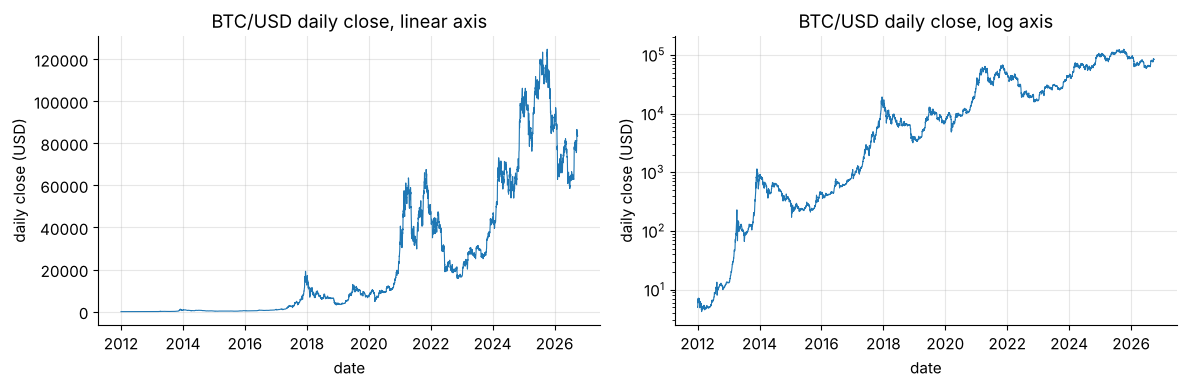

close on the last day of each year (USD; 2026: last day available):
date        2012  2013  2014  2015  2016   2017  2018  2019   2020   2021   2022   2023   2024   2025   2026
last close    13   732   321   431   966  13880  3693  7168  28993  46214  16528  42258  93381  87496  83563


In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.plot(btc.index, btc["close"], lw=0.8)
    ax.set_yscale(scale)
    ax.set(xlabel="date", ylabel="daily close (USD)", title=f"BTC/USD daily close, {scale} axis")
fig.tight_layout()
plt.show()

yearly = btc["close"].groupby(btc.index.year)
print(f"close on the last day of each year (USD, {btc.index[-1].year}: last day available):")
print(yearly.last().round(0).astype(int).to_frame("last close").T.to_string())

The log plot reveals a structure the linear plot hides: repeated cycles of a huge rally followed by a
long decline (2013-2015, 2017-2018, 2021-2022) on top of a long-run upward drift whose *percentage*
growth rate slows down over time. Per-year panels make the regime changes easy to compare, and each
title shows the change from the first open to the last close of the year.

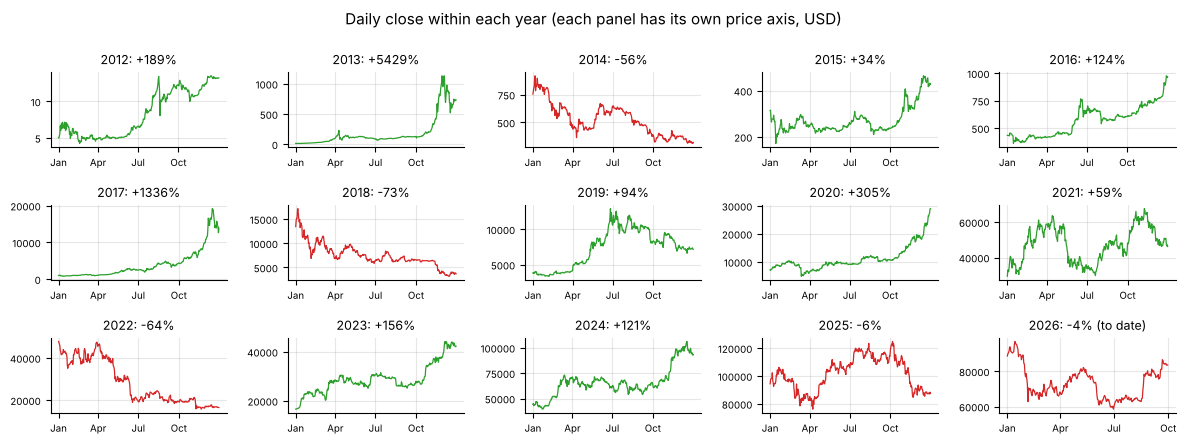

In [51]:
years = sorted(btc.index.year.unique())
fig, axes = plt.subplots(3, 5, figsize=(12, 4.5), sharex=False)
for ax, year in zip(axes.flat, years):
    one = btc.loc[str(year)]
    change = 100 * (one["close"].iloc[-1] / one["open"].iloc[0] - 1)
    ax.plot(one.index.dayofyear, one["close"], lw=0.9, color="tab:green" if change >= 0 else "tab:red")
    ax.set_title(f"{year}: {change:+.0f}%" + (" (to date)" if year == years[-1] else ""), fontsize=9)
    ax.tick_params(labelsize=7)
    ax.set_xticks([1, 91, 182, 274])
    ax.set_xticklabels(["Jan", "Apr", "Jul", "Oct"])
for ax in axes.flat[len(years):]:
    ax.axis("off")
fig.suptitle("Daily close within each year (each panel has its own price axis, USD)", fontsize=11)
fig.tight_layout()
plt.show()

A **candlestick chart** draws every candle as a thin vertical line (the *wick*) from low to high and
a thick *body* from open to close, green when the close is above the open and red when it is below.
Four years of daily candles (about 1,460) would be too dense to read, so the left chart shows **weekly**
candles for 2020-2023. They are built from the daily candles with exactly the rules of Section 7.1
(first open, max high, min low, last close, summed volume), this time with pandas `resample`. The right
chart zooms in on daily candles around the crash of March 2020.

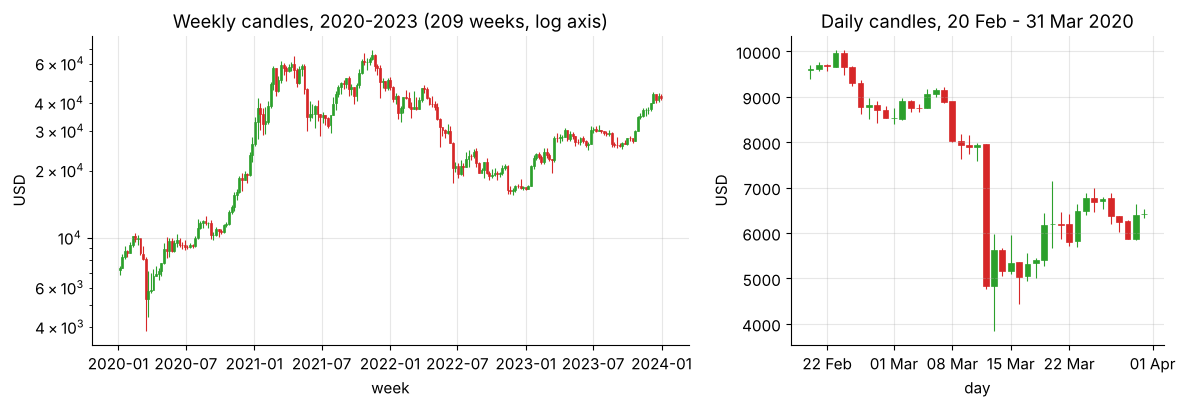

2020-03-12: open 7,956, high 7,970, low 4,777, close 4,842 -> -39.1% in one day


In [52]:
import matplotlib.dates as mdates


def to_candles(df, rule):
    """Aggregate OHLCV candles to a coarser period (e.g. 'W' = weekly) with the candle rules."""
    return df.resample(rule).agg({"open": "first", "high": "max", "low": "min",
                                  "close": "last", "volume": "sum"}).dropna()


def draw_candles(ax, candles, width_days):
    """Plain-matplotlib candlestick chart: wick from low to high, body from open to close."""
    x = mdates.date2num(candles.index.to_pydatetime())
    up = (candles["close"] >= candles["open"]).to_numpy()
    colors = np.where(up, "tab:green", "tab:red")
    ax.vlines(x, candles["low"], candles["high"], colors=colors, lw=0.8)
    body_low = candles[["open", "close"]].min(axis=1)
    body_height = (candles["close"] - candles["open"]).abs().clip(lower=1e-9 * candles["close"])
    ax.bar(x, body_height, width_days, bottom=body_low, color=colors, edgecolor=colors, lw=0.5)
    ax.xaxis_date()


weekly = to_candles(btc.loc["2020":"2023"], "W")
march = btc.loc["2020-02-20":"2020-03-31"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
draw_candles(axes[0], weekly, width_days=5)
axes[0].set_yscale("log")
axes[0].set(title=f"Weekly candles, 2020-2023 ({len(weekly)} weeks, log axis)", xlabel="week", ylabel="USD")
draw_candles(axes[1], march, width_days=0.7)
axes[1].set(title="Daily candles, 20 Feb - 31 Mar 2020", xlabel="day", ylabel="USD")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.tight_layout()
plt.show()

crash = btc.loc["2020-03-12"]
print(f"2020-03-12: open {crash['open']:,.0f}, high {crash['high']:,.0f}, low {crash['low']:,.0f}, "
      f"close {crash['close']:,.0f} -> {100 * (crash['close'] / crash['open'] - 1):+.1f}% in one day")

### 7.3 The naive model: today's open, high and low → today's close

Here is a setup you will find in many online tutorials. Take every day as one sample with features
$\mathbf{x} = (O, H, L)$ (open, high, low) and target $y = C$ (close), shuffle the days, split them
70/30 into training and test sets, standardize the features with statistics of the training set, and
fit a linear model with batch gradient descent. Everything here is a tool you built in Sections 2-5.

In [53]:
btc_X = btc[["open", "high", "low"]].to_numpy()
btc_y = btc["close"].to_numpy()
btc_tr_X, btc_te_X, btc_tr_y, btc_te_y, btc_tr_dates, btc_te_dates = train_test_split(
    btc_X, btc_y, btc.index, test_size=0.3, random_state=SEED, shuffle=True)

btc_scaler = StandardScaler().fit(btc_tr_X)                       # statistics of the training days only
btc_tr_Xb = add_bias(btc_scaler.transform(btc_tr_X))
btc_te_Xb = add_bias(btc_scaler.transform(btc_te_X))

btc_eig = np.linalg.eigvalsh(2 / len(btc_tr_y) * btc_tr_Xb.T @ btc_tr_Xb)   # Hessian eigenvalues (Section 3.7)
print(f"{len(btc_tr_y)} training days, {len(btc_te_y)} test days")
print("correlations between open, high, low (training days):")
print(np.corrcoef(btc_tr_X.T).round(5))
print(f"Hessian eigenvalues: {np.round(btc_eig, 5)} -> condition number {btc_eig.max() / btc_eig.min():,.0f}")

3770 training days, 1617 test days
correlations between open, high, low (training days):
[[1.      0.99972 0.99961]
 [0.99972 1.      0.99946]
 [0.99961 0.99946 1.     ]]
Hessian eigenvalues: [5.10000e-04 1.11000e-03 2.00000e+00 5.99838e+00] -> condition number 11,714


The three features are almost perfect copies of each other (correlations above $0.999$), so even after
standardization the loss surface is an extremely narrow valley: the condition number is about
$11{,}700$ (it was about $2.3$ for the standardized advertising data). Section 3.7 predicts what that
means for gradient descent. Along the steep direction, roughly "the overall price level"
$z_O + z_H + z_L$, a rate of $1/\lambda_{\max}$ converges almost at once. Along the flat directions,
which decide how the weight is shared *among* the three near-copies, each step shrinks the error only
by a factor of $1 - \lambda_{\min}/\lambda_{\max} \approx 0.99991$. We run $20{,}000$ full-batch steps
(a few seconds at most, thanks to vectorization) and watch both the test metrics and the coefficients.

In [54]:
btc_lr = 1.0 / btc_eig.max()
theta_btc, hist_btc = train_linear_gd(btc_tr_Xb, btc_tr_y, lr=btc_lr, n_epochs=20_000,
                                      batch_size=len(btc_tr_y), shuffle=False, record_path=True)
sk_btc = LinearRegression().fit(btc_scaler.transform(btc_tr_X), btc_tr_y)
theta_btc_exact = np.r_[sk_btc.intercept_, sk_btc.coef_]


def price_metrics(y_true, y_pred):
    """RMSE and MAE in USD, MAPE in %, and R^2, as a dict."""
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)), "MAE": mean_absolute_error(y_true, y_pred),
            "MAPE %": 100 * mean_absolute_percentage_error(y_true, y_pred), "R^2": r2_score(y_true, y_pred)}


def gd_report_row(theta):
    """Test metrics followed by the three feature weights (z-score units) of one parameter vector."""
    metrics = price_metrics(btc_te_y, btc_te_Xb @ theta)
    return {"R^2": metrics.pop("R^2"), **metrics, "theta_O": theta[1], "theta_H": theta[2], "theta_L": theta[3]}


rows = {f"GD, {step:,} steps": gd_report_row(hist_btc["path"][step]) for step in [10, 100, 1_000, 5_000, 20_000]}
rows["closed form (scikit-learn)"] = gd_report_row(theta_btc_exact)
naive_table = pd.DataFrame(rows).T
with pd.option_context("display.float_format", "{:,.6g}".format):
    display(naive_table)
w_raw = sk_btc.coef_ / btc_scaler.scale_
b_raw = sk_btc.intercept_ - np.sum(w_raw * btc_scaler.mean_)
print(f"intercept (theta_0) after 20,000 GD steps: {theta_btc[0]:,.2f}, closed form: {theta_btc_exact[0]:,.2f}")
print(f"closed form in USD units: close = {b_raw:.3f} {w_raw[0]:+.4f}*open {w_raw[1]:+.4f}*high {w_raw[2]:+.4f}*low")

,R^2,RMSE,MAE,MAPE %,theta_O,theta_H,theta_L
"GD, 10 steps",0.999394,783.096,586.962,530.51,"10,512.6","10,548.9","10,545.4"
"GD, 100 steps",0.999584,648.756,320.708,21.7314,"10,302.1","10,668.1","10,636.8"
"GD, 1,000 steps",0.999624,617.253,305.742,21.0585,"8,286","11,821","11,500.1"
"GD, 5,000 steps",0.99974,513.407,256.605,17.4864,"1,026.62","16,145.5","14,435.5"
"GD, 20,000 steps",0.999846,394.663,193.849,7.10959,"-11,696.2","24,349.6","18,955"
closed form (scikit-learn),0.999854,383.992,182.518,2.05232,"-16,545.7","27,663.5","20,490.9"


intercept (theta_0) after 20,000 GD steps: 24,410.27, closed form: 24,410.27
closed form in USD units: close = 1.026 -0.5234*open +0.8603*high +0.6606*low


Three lessons in one table:

* **$R^2$ is spectacular from the start.** After only $10$ steps the test $R^2$ is already $0.9994$, and the
  exact least-squares solution reaches $0.99985$ (the "$R^2 \approx 0.9999$" of the introduction), with a
  typical error (RMSE) of about $\$384$ on prices that reach six digits.
* **Gradient descent crawls along the narrow valley.** The intercept is exact within a few dozen steps, but the
  three weights are still far from the closed form after $5{,}000$ steps, and even after $20{,}000$ steps
  $\theta_O \approx -11{,}696$ instead of $-16{,}546$. The predictions converge much earlier
  than the coefficients, because many very different weight vectors give almost the same predictions
  when the features are near-copies. This is the condition-number story of Section 3.7 in a real dataset,
  and a reason to prefer the closed form (or better features) for small, badly conditioned problems.
* **MAPE disagrees with $R^2$.** While $R^2$ barely moves, MAPE falls from $531\%$ after $10$ steps to $7.1\%$
  after $20{,}000$, and the closed form reaches $2.1\%$.
  $R^2$ and RMSE are dominated by the expensive recent days (large errors in dollars), while MAPE is
  dominated by the cheap early days (an error of $\$50$ is $1\%$ of $\$5{,}000$ but $1000\%$ of $\$5$).

The closed form, in dollars, is roughly $C \approx -0.52\,O + 0.86\,H + 0.66\,L$ (plus about a dollar): a
weighted blend of the day's high and low, minus some of the open. Here is what the predictions look like for
the test days in the third quarter of 2020:

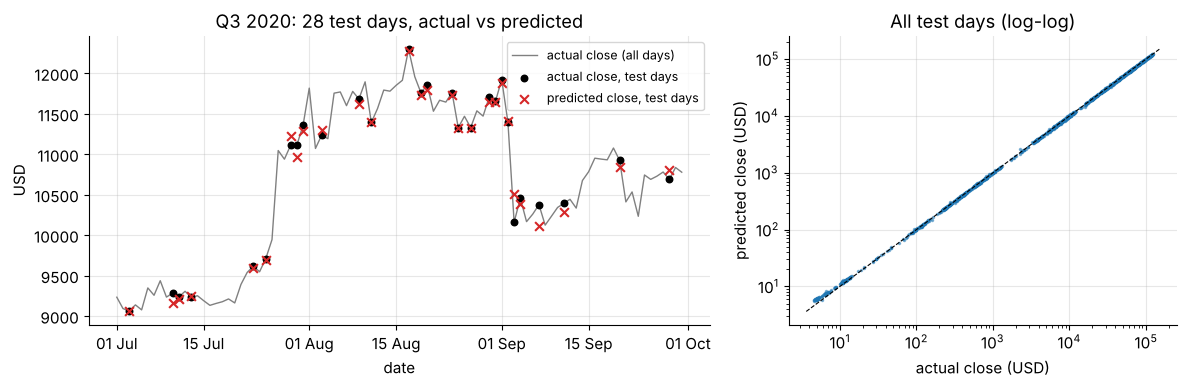

Q3 2020 test days: RMSE = 103.6 USD, MAPE = 0.65%


In [55]:
ZOOM_START, ZOOM_END = "2020-07-01", "2020-09-30"                  # the third quarter (Q3) of 2020
zoom = (btc_te_dates >= ZOOM_START) & (btc_te_dates <= ZOOM_END)
zoom_order = np.argsort(btc_te_dates[zoom])
zoom_dates = btc_te_dates[zoom][zoom_order]
zoom_pred = (btc_te_Xb[zoom] @ theta_btc_exact)[zoom_order]
zoom_actual = btc_te_y[zoom][zoom_order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(btc.loc[ZOOM_START:ZOOM_END].index, btc.loc[ZOOM_START:ZOOM_END, "close"], color="gray",
        lw=1, label="actual close (all days)")
ax.scatter(zoom_dates, zoom_actual, s=22, color="k", label="actual close, test days", zorder=3)
ax.scatter(zoom_dates, zoom_pred, s=40, marker="x", color="tab:red", label="predicted close, test days", zorder=4)
ax.set(xlabel="date", ylabel="USD", title=f"Q3 2020: {zoom.sum()} test days, actual vs predicted")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(fontsize=9)
lims = [btc_te_y.min() * 0.8, btc_te_y.max() * 1.2]
axes[1].loglog(btc_te_y, btc_te_Xb @ theta_btc_exact, ".", ms=3, alpha=0.5)
axes[1].plot(lims, lims, "k--", lw=0.8)
axes[1].set(xlabel="actual close (USD)", ylabel="predicted close (USD)", title="All test days (log-log)")
fig.tight_layout()
plt.show()
print(f"Q3 2020 test days: RMSE = {np.sqrt(np.mean((zoom_pred - zoom_actual) ** 2)):.1f} USD, "
      f"MAPE = {100 * np.mean(np.abs(zoom_pred - zoom_actual) / zoom_actual):.2f}%")

In the third quarter of 2020 the predicted closes sit right on top of the actual ones: an RMSE of about
$\$104$ and a MAPE of about $0.65\%$. On the log-log plot all test days hug the diagonal over four orders of
magnitude. Impressive... or is it? Could you trade with this model? Read on before answering.

### 7.4 Why that $R^2$ is not a forecast

You could not trade with this model, for three independent reasons. Each one alone would inflate the
score, and together they make it meaningless.

**1. The features are only known after the target.** The high and low of a day are known only when
the day is over, and at that moment the close is known too. Worse, the target is *sandwiched*:
$L \le C \le H$ always holds. A model that is told the high and the low only has to guess where the
close lies inside an interval that is usually narrow. So we "predict" the close from information that
already contains it.

**2. A shuffled split leaks the future.** After shuffling, a typical test day has its neighbors, the
day before and the day after, in the training set. Prices move little from one day to the next, so the
neighbors almost give the answer away, including the day *after*, which is information from the future.
In a real forecast, the entire future is unknown.

**3. $R^2$ on a trending level is inflated.** $R^2 = 1 - \text{SSE}/\text{SST}$ compares the model with the
constant prediction "average price of 2012-2026" (about $\$24{,}000$). Prices range from a few dollars to
over $\$100{,}000$, so SST is gigantic and *any* prediction that roughly follows the price level gets $R^2$
close to $1$, whether or not it knows anything about tomorrow.

Talk is cheap, so let us measure. On the same test days we score the linear model against three
"predictors" that contain no intelligence at all:

* **today's open**: just the opening price, which is essentially yesterday's close.
* **midpoint** $(H + L)/2$: exploits reason 1 only.
* **connect the dots**: ignores all features, and predicts a test day by drawing a straight line
  between the closes of the nearest *training* days before and after it, and exploits reason 2 only.

In [56]:
order_tr = np.argsort(btc_tr_dates)
day_number = lambda dates: (dates - pd.Timestamp("1970-01-01")).days.to_numpy()   # dates -> numbers
dumb_predictions = {
    "linear model (O, H, L)": btc_te_Xb @ theta_btc_exact,
    "today's open": btc_te_X[:, 0],
    "midpoint (H + L) / 2": btc_te_X[:, 1:].mean(axis=1),
    "connect the dots": np.interp(day_number(btc_te_dates), day_number(btc_tr_dates[order_tr]), btc_tr_y[order_tr]),
}
dumb_table = pd.DataFrame({name: price_metrics(btc_te_y, pred) for name, pred in dumb_predictions.items()}).T
with pd.option_context("display.precision", 5):
    display(dumb_table[["R^2", "RMSE", "MAE", "MAPE %"]].round({"R^2": 5, "RMSE": 1, "MAE": 1, "MAPE %": 2}))

,R^2,RMSE,MAE,MAPE %
"linear model (O, H, L)",0.99985,384.0,182.5,2.05
today's open,0.99897,1021.7,492.3,2.47
midpoint (H + L) / 2,0.99975,503.6,248.5,1.31
connect the dots,0.99936,801.8,398.8,2.03


Every "predictor" scores $R^2 > 0.998$. The midpoint, a formula a child could apply, gets $0.99975$, and the
connect-the-dots rule, which never even looks at the features of the test day, gets about $0.9994$. The linear
model is better than both on $R^2$, RMSE and MAE (it learned a smarter blend of $O$, $H$ and $L$), though
not on MAPE ($2.05\%$ versus $1.31\%$ for the midpoint: least squares concentrates on the expensive recent
days), and only *within the game of same-day reconstruction*.

Reason 3 deserves its own experiment, because it survives even when reasons 1 and 2 are fixed. We
simulate a **random walk**: every day the log-price moves by an independent random amount, so tomorrow's
move is, by construction, impossible to predict from anything. Then we "forecast" with the **persistence
baseline** $\hat C_{t+1} = C_t$ (tomorrow's close = today's close), using no future information at all.

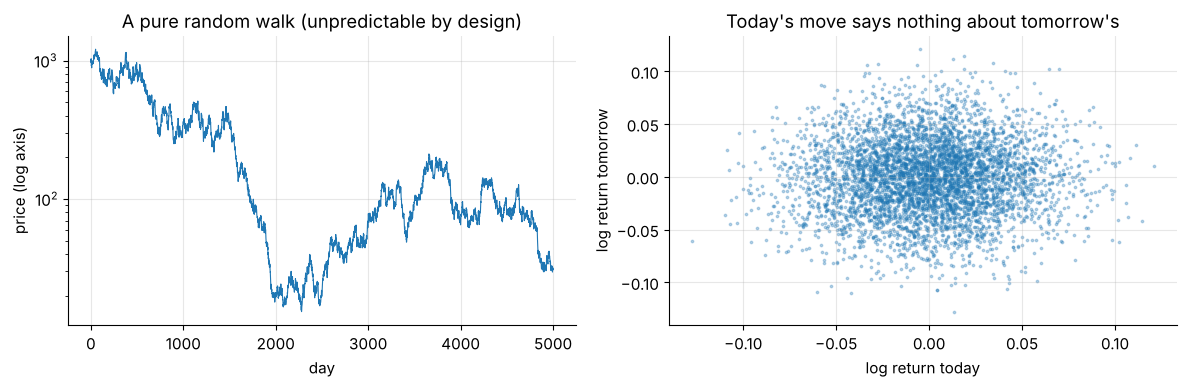

persistence forecast, R^2 on price levels : 0.9980
persistence forecast, R^2 on daily returns: -0.0004
lag-1 forecast,       R^2 on daily returns: -0.9456
correlation between consecutive returns   : +0.0272


In [57]:
walk_rng = np.random.default_rng(SEED)
walk_log = np.log(1_000) + np.cumsum(walk_rng.normal(0.0, 0.035, size=5_000))   # 3.5% daily volatility
walk = np.exp(walk_log)
walk_returns = np.diff(walk_log)
r2_level = r2_score(walk[1:], walk[:-1])                               # persistence on price LEVELS
r2_zero = r2_score(walk_returns[1:], np.zeros(len(walk_returns) - 1))  # persistence on RETURNS: r_hat = 0
r2_return = r2_score(walk_returns[1:], walk_returns[:-1])              # "tomorrow's move = today's move"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(walk, lw=0.8)
axes[0].set(xlabel="day", ylabel="price (log axis)", title="A pure random walk (unpredictable by design)")
axes[1].scatter(walk_returns[:-1], walk_returns[1:], s=3, alpha=0.3)
axes[1].set(xlabel="log return today", ylabel="log return tomorrow",
            title="Today's move says nothing about tomorrow's")
fig.tight_layout()
plt.show()
print(f"persistence forecast, R^2 on price levels : {r2_level:.4f}")
print(f"persistence forecast, R^2 on daily returns: {r2_zero:.4f}")
print(f"lag-1 forecast,       R^2 on daily returns: {r2_return:.4f}")
print(f"correlation between consecutive returns   : {np.corrcoef(walk_returns[:-1], walk_returns[1:])[0, 1]:+.4f}")

A series that is unpredictable *by construction* gives a persistence "forecast" with $R^2 \approx 0.998$
on price levels. Scored on **returns** (the daily changes, which is what a forecaster actually has to
predict), the very same persistence forecast, $\hat r_{t+1} = 0$, gets $R^2 \approx 0$: no skill at all,
which is the truth. A rule that copies today's move to tomorrow is even worse ($R^2 \approx -0.95$): its
error $r_{t+1} - r_t$ combines two independent moves, so its squared error is about twice that of
predicting $0$. The lesson generalizes far beyond finance:

> **Key idea.** For a trending or wandering series, scores on *levels* mostly measure the trend. Judge a
> forecast by (a) using only information available at prediction time, (b) testing on a period that
> comes *after* the training period, and (c) comparing with a naive baseline such as persistence,
> preferably on *changes* rather than levels.

> **Common pitfall.** "My model has $R^2 = 0.99$ on stock prices" is almost never news. Ask three
> questions: were the features known *before* the target? Was the split chronological? How does the
> model compare with "tomorrow = today"?

### 7.5 Doing it properly: forecasting tomorrow from the past

Now we set up a forecasting problem that could actually be used. At the end of day $t$ we know every
candle up to and including day $t$, and we want to predict the close of day $t+1$.

**Target.** Instead of the price level we predict the next-day **log return**

$$
r_{t+1} = \ln\frac{C_{t+1}}{C_t} \qquad\Longrightarrow\qquad \hat C_{t+1} = C_t\, e^{\hat r_{t+1}} .
$$

A log return of $0.01$ is a rise of about $1\%$. Returns are *scale-free* (a $1\%$ move means the same in
2017 and in 2026), much closer to stationary than prices, and they make the persistence baseline
explicit: "tomorrow = today" is simply $\hat r_{t+1} = 0$.

**Features** (all known at the end of day $t$): the $K$ most recent log returns
$r_t, r_{t-1}, \dots, r_{t-K+1}$, and the day's log range $\ln(H_t/L_t)$, a measure of how volatile the day
was. The number of lags $K$ is a **hyperparameter** that we choose by cross-validation.

**Periods.** We start in 2017, when the market became liquid (Section 7.1), use 2017-2023 as the
**development** period (for fitting and for choosing $K$), and keep 2024 to September 2026 as an
untouched **test** period that lies entirely in the future of everything the model has seen.

In [58]:
def next_day_dataset(candles: pd.DataFrame, n_lags: int) -> pd.DataFrame:
    """One row per day t: features known at the end of day t, and the target r_{t+1}."""
    log_ret = np.log(candles["close"]).diff()                         # r_t = ln(C_t / C_{t-1})
    data = pd.DataFrame({f"r_t-{k}": log_ret.shift(k) for k in range(n_lags)}, index=candles.index)
    data["log_range"] = np.log(candles["high"] / candles["low"])
    data["close_t"] = candles["close"]                                # kept to turn returns into prices
    data["target"] = log_ret.shift(-1)                                # r_{t+1}: the ONLY column from the future
    return data.dropna()


DEV_END, TEST_START = "2023-12-31", "2024-01-01"
recent = btc.loc["2017-01-01":]
example = next_day_dataset(recent, n_lags=3)
print(f"rows: {len(example)} | development {len(example.loc[:DEV_END])} days, "
      f"test {len(example.loc[TEST_START:])} days ({example.loc[TEST_START:].index[0].date()} to {example.index[-1].date()})")
display(example.head(3).round(5))

rows: 3556 | development 2553 days, test 1003 days (2024-01-01 to 2026-09-29)


,r_t-0,r_t-1,r_t-2,log_range,close_t,target
date,,,,,,
2017-01-04,0.0741,0.0222,0.0147,0.1028,1114.92,-0.1041
2017-01-05,-0.1041,0.0741,0.0222,0.2498,1004.74,-0.1169
2017-01-06,-0.1169,-0.1041,0.0741,0.1648,893.89,0.0137


To choose $K$ we cannot use ordinary shuffled $k$-fold cross-validation, for the same reason as in
Section 7.4: it would train on the future. scikit-learn's `TimeSeriesSplit` makes **expanding-window**
folds instead: cut the development period into consecutive blocks. In fold $j$, train on everything
before block $j+1$ and validate on block $j+1$. Training data always precede validation data.

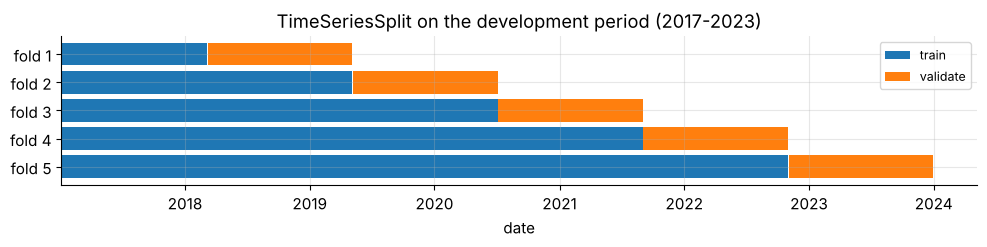

In [59]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline

tscv = TimeSeriesSplit(n_splits=5)
dev_days = example.loc[:DEV_END].index
fig, ax = plt.subplots(figsize=(10, 2.6))
for fold, (tr_idx, va_idx) in enumerate(tscv.split(dev_days)):
    ax.barh(fold, dev_days[tr_idx[-1]] - dev_days[tr_idx[0]], left=dev_days[tr_idx[0]], color="tab:blue",
            label="train" if fold == 0 else None)
    ax.barh(fold, dev_days[va_idx[-1]] - dev_days[va_idx[0]], left=dev_days[va_idx[0]], color="tab:orange",
            label="validate" if fold == 0 else None)
ax.set(yticks=range(5), yticklabels=[f"fold {k + 1}" for k in range(5)], xlabel="date",
       title="TimeSeriesSplit on the development period (2017-2023)")
ax.invert_yaxis()
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

For every candidate $K$ we fit a standardized linear regression on each fold's training block and record
the validation MSE of the predicted returns. As a reference we score the persistence forecast
$\hat r = 0$ on exactly the same validation blocks, and report the **skill**
$1 - \text{MSE}_{\text{model}} / \text{MSE}_{\text{persistence}}$: positive means better than
persistence, negative means worse.

In [60]:
cv_rows = []
for n_lags in [1, 2, 3, 5, 10, 20]:
    dev = next_day_dataset(recent, n_lags).loc[:DEV_END]
    X_dev = dev.drop(columns=["close_t", "target"]).to_numpy()
    y_dev = dev["target"].to_numpy()
    mse_model, mse_zero = [], []
    for tr_idx, va_idx in tscv.split(X_dev):
        model = make_pipeline(StandardScaler(), LinearRegression()).fit(X_dev[tr_idx], y_dev[tr_idx])
        mse_model.append(mean_squared_error(y_dev[va_idx], model.predict(X_dev[va_idx])))
        mse_zero.append(np.mean(y_dev[va_idx] ** 2))
    cv_rows.append({"K (lags)": n_lags, "CV MSE x 1e4": 1e4 * np.mean(mse_model),
                    "persistence MSE x 1e4": 1e4 * np.mean(mse_zero),
                    "skill vs persistence %": 100 * (1 - np.mean(mse_model) / np.mean(mse_zero))})
cv_table = pd.DataFrame(cv_rows).set_index("K (lags)")
display(cv_table.round(3))
best_lags = int(cv_table["CV MSE x 1e4"].idxmin())
print(f"best number of lags by cross-validation: K = {best_lags}")

,CV MSE x 1e4,persistence MSE x 1e4,skill vs persistence %
K (lags),,,
1,13.462,13.377,-0.634
2,13.432,13.377,-0.408
3,13.430,13.377,-0.396
5,13.515,13.377,-1.030
10,13.531,13.357,-1.303
20,13.696,13.322,-2.811


best number of lags by cross-validation: K = 3


Read the last column carefully: **every** $K$ has negative skill. On average over the five validation
blocks, the fitted linear models predict next-day returns *worse* than simply predicting "no change".
The fitted coefficients pick up patterns of the training years that do not persist, a mild form of
overfitting to noise. Beyond three lags, more lags (more parameters to fit noise with) hurt more.

An honest analyst would stop here and report: "no linear model of recent returns beats persistence
in validation". For the sake of the method, we still take the least-bad $K$, refit it on the whole
development period, and evaluate it **once** on the untouched test period, next to the persistence
baseline, both on returns and on prices.

In [61]:
data_best = next_day_dataset(recent, best_lags)
dev, test = data_best.loc[:DEV_END], data_best.loc[TEST_START:]
feature_cols = [c for c in data_best.columns if c not in ("close_t", "target")]
final_model = make_pipeline(StandardScaler(), LinearRegression()).fit(dev[feature_cols], dev["target"])

r_true = test["target"].to_numpy()
r_model = final_model.predict(test[feature_cols])
close_t = test["close_t"].to_numpy()
close_next = close_t * np.exp(r_true)                               # the actual close of day t+1
forecasts = {"persistence (r = 0)": close_t, f"linear model (K = {best_lags})": close_t * np.exp(r_model)}

honest = pd.DataFrame({name: price_metrics(close_next, pred) for name, pred in forecasts.items()}).T
honest["skill on returns %"] = [0.0, 100 * (1 - np.sum((r_true - r_model) ** 2) / np.sum(r_true ** 2))]
honest["direction accuracy %"] = [np.nan, 100 * np.mean(np.sign(r_model) == np.sign(r_true))]
display(honest.round({"RMSE": 1, "MAE": 1, "MAPE %": 3, "R^2": 5, "skill on returns %": 3, "direction accuracy %": 2}))
for name, pred in forecasts.items():
    m_ = price_metrics(close_next, pred)
    print(f"{name:22s}: RMSE {m_['RMSE']:,.1f} USD | MAPE {m_['MAPE %']:.3f}% | R^2 on prices {m_['R^2']:.4f}")
print(f"model skill on returns: {honest.iloc[1]['skill on returns %']:+.3f}% | direction accuracy "
      f"{honest.iloc[1]['direction accuracy %']:.2f}% vs {100 * np.mean(r_true > 0):.2f}% of test days that went up")
print(f"standard deviation of daily log returns in the test period: {100 * r_true.std():.2f}% "
      f"| of the model's predicted returns: {100 * r_model.std():.3f}%")

,RMSE,MAE,MAPE %,R^2,skill on returns %,direction accuracy %
persistence (r = 0),1936.6,1376.6,1.75,0.9907,0.000,NaN
linear model (K = 3),1939.1,1377.0,1.75,0.9907,0.296,50.65


persistence (r = 0)   : RMSE 1,936.6 USD | MAPE 1.750% | R^2 on prices 0.9907
linear model (K = 3)  : RMSE 1,939.1 USD | MAPE 1.750% | R^2 on prices 0.9907
model skill on returns: +0.296% | direction accuracy 50.65% vs 50.55% of test days that went up
standard deviation of daily log returns in the test period: 2.48% | of the model's predicted returns: 0.172%


This is what an honest result looks like:

* **On prices, both forecasts score $R^2 \approx 0.99$**: once more, level $R^2$ only says that prices
  follow their own trend. The RMSE (about $\$1{,}940$) and the MAPE of the two forecasts agree to three
  significant digits, and the model's RMSE is even slightly *worse*.
* **On returns, the model's skill is about $+0.3\%$**: it removes three thousandths of the squared error
  of "no change". Its direction accuracy, $50.65\%$, is essentially the $50.55\%$ that an "always up"
  guess achieves in this period. Neither difference is distinguishable from luck with about a thousand
  test days, and validation even said the opposite sign.
* The model's predicted returns vary by only about $0.17\%$ per day, while actual returns vary by about
  $2.5\%$: the fitted model has learned to predict "almost no change", which is about the best a linear
  model of past returns can do here.

Compare this with the $R^2 = 0.9999$ of Section 7.3. Same data, same algorithm, completely different
truth: what changed is the question (same-day reconstruction versus a genuine next-day forecast) and the
honesty of the evaluation. That is the main message of this case study.

> **Going deeper.** That daily returns of a heavily traded asset are close to unpredictable from their own
> past is consistent with the *efficient-market hypothesis*: if a simple pattern existed, traders
> exploiting it would erase it. Volatility (the *size* of moves), unlike direction, is quite predictable.
> Try it: predict $|r_{t+1}|$ or $r_{t+1}^2$ from the log range and recent absolute returns, with the same
> chronological workflow, and you will find clearly positive skill against the constant forecast
> "average absolute return of the development period".

> **Olympiad tip.** In any task with a time component (sales, sensor readings, user sessions), check the
> split before the model: random splits of time-ordered data are the most common source of too-good-to-be-true
> scores, and graders design tasks to catch them.

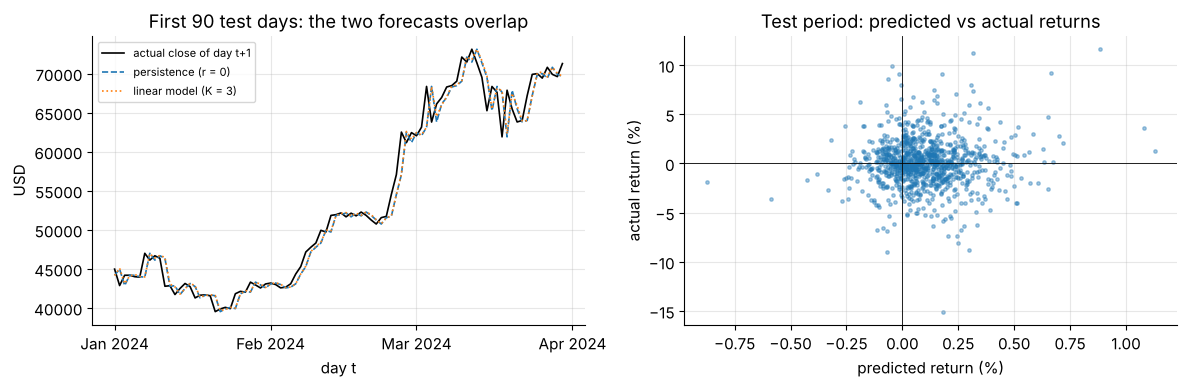

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
window = slice(0, 90)                                               # the first 90 test days
test_days = test.index[window]
axes[0].plot(test_days, close_next[window], color="k", lw=1.2, label="actual close of day t+1")
for (name, pred), style in zip(forecasts.items(), ["--", ":"]):
    axes[0].plot(test_days, pred[window], ls=style, lw=1.2, label=name)
axes[0].set(xlabel="day t", ylabel="USD", title="First 90 test days: the two forecasts overlap")
axes[0].xaxis.set_major_locator(mdates.MonthLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[0].legend(fontsize=8)
axes[1].scatter(100 * r_model, 100 * r_true, s=6, alpha=0.4)
axes[1].axhline(0, color="k", lw=0.6)
axes[1].axvline(0, color="k", lw=0.6)
axes[1].set(xlabel="predicted return (%)", ylabel="actual return (%)", title="Test period: predicted vs actual returns")
fig.tight_layout()
plt.show()

In [63]:
# ✏️ Exercise 9: merge two partial candles of the same day
def merge_two_partials(a: dict, b: dict) -> dict:
    """a and b are partial candles of ONE day, given in any order, each a dict with keys
    'first_ts', 'last_ts', 'open', 'high', 'low', 'close', 'volume'. Return the merged partial candle
    (same keys), exactly as if all minutes of both pieces had been aggregated together."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    early = {"first_ts": 0, "last_ts": 540, "open": 10.0, "high": 12.0, "low": 9.0, "close": 11.0, "volume": 3.0}
    late = {"first_ts": 600, "last_ts": 1200, "open": 11.5, "high": 11.8, "low": 8.0, "close": 8.5, "volume": 2.5}
    expected = {"first_ts": 0, "last_ts": 1200, "open": 10.0, "high": 12.0, "low": 8.0, "close": 8.5, "volume": 5.5}
    for x, y in [(early, late), (late, early)]:                      # the order of the pieces must not matter
        out = merge_two_partials(x, y)
        assert isinstance(out, dict), "return a dict"
        for key, value in expected.items():
            assert np.isclose(out.get(key, np.nan), value), f"{key}: expected {value}, got {out.get(key)}"
    # associativity: merging three pieces in either grouping gives the same candle
    mid = {"first_ts": 560, "last_ts": 580, "open": 11.2, "high": 13.0, "low": 10.5, "close": 11.4, "volume": 0.5}
    left = merge_two_partials(merge_two_partials(early, mid), late)
    right = merge_two_partials(early, merge_two_partials(mid, late))
    assert all(np.isclose(left[k], right[k]) for k in expected), "merging must be associative"
    assert np.isclose(left["high"], 13.0) and np.isclose(left["volume"], 6.0), "three-piece merge is wrong"


run_check("Exercise 9", _test)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def merge_two_partials(a, b):
    first = a if a["first_ts"] <= b["first_ts"] else b      # piece that starts earlier holds the open
    last = a if a["last_ts"] >= b["last_ts"] else b         # piece that ends later holds the close
    return {"first_ts": first["first_ts"], "last_ts": last["last_ts"],
            "open": first["open"], "close": last["close"],
            "high": max(a["high"], b["high"]), "low": min(a["low"], b["low"]),
            "volume": a["volume"] + b["volume"]}
```
Because the result again carries its time span, merged pieces can be merged further in any grouping:
that associativity is exactly what makes chunked (and distributed) aggregation correct.
</details>

In [64]:
# ✏️ Exercise 10: a leakage-free supervised dataset from a price series
def lagged_return_dataset(close: pd.Series, n_lags: int):
    """From daily closes C_t return (X, y): X has columns 'lag0', ..., 'lag{n_lags-1}' holding
    r_t, r_{t-1}, ..., r_{t-n_lags+1} (log returns, r_t = ln(C_t / C_{t-1})), and y is r_{t+1}.
    Both are indexed by day t. Drop every row with a missing value."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    close = pd.Series(np.exp([0.0, 0.1, 0.3, 0.2, 0.6, 0.5]), index=pd.date_range("2024-01-01", periods=6))
    X, y = lagged_return_dataset(close, n_lags=2)
    assert list(X.columns) == ["lag0", "lag1"], f"columns should be ['lag0', 'lag1'], got {list(X.columns)}"
    assert len(X) == len(y) == 3, f"expected 3 complete rows, got {len(X)} and {len(y)}"
    assert (X.index == y.index).all(), "X and y must share the same index (day t)"
    assert np.allclose(X.to_numpy(), [[0.2, 0.1], [-0.1, 0.2], [0.4, -0.1]]), f"wrong features:\n{X}"
    assert np.allclose(y.to_numpy(), [-0.1, 0.4, -0.1]), f"wrong targets: {y.to_numpy()}"
    future = close.copy()
    future.iloc[-1] *= 10                                            # change only the LAST price
    X2, _ = lagged_return_dataset(future, n_lags=2)
    assert np.allclose(X2.to_numpy(), X.to_numpy()), "features must not depend on prices after day t (leakage!)"


run_check("Exercise 10", _test)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def lagged_return_dataset(close, n_lags):
    r = np.log(close).diff()
    X = pd.DataFrame({f"lag{k}": r.shift(k) for k in range(n_lags)})
    y = r.shift(-1).rename("target")
    keep = X.notna().all(axis=1) & y.notna()
    return X[keep], y[keep]
```
`shift(k)` with $k \ge 0$ looks into the past, `shift(-1)` into the future, and the target is the only
place where a negative shift is allowed. The last check in the tester is a handy leakage test for any
feature pipeline: perturb the future and verify that no feature changes.
</details>

In [65]:
# ✏️ Exercise 11: expanding-window time-series splits from scratch
def expanding_window_splits(n_samples: int, n_splits: int):
    """Return a list of (train_idx, val_idx) NumPy arrays that reproduces sklearn's TimeSeriesSplit
    with default settings: each validation block has n_samples // (n_splits + 1) samples, the blocks
    are the LAST n_splits such blocks of the data in time order, and each training set is everything
    before its validation block."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    for n, k in [(12, 3), (100, 5), (37, 4)]:
        mine = expanding_window_splits(n, k)
        ref = list(TimeSeriesSplit(n_splits=k).split(np.zeros(n)))
        assert len(mine) == k, f"n={n}, k={k}: expected {k} splits, got {len(mine)}"
        for j, ((tr, va), (tr_ref, va_ref)) in enumerate(zip(mine, ref)):
            assert np.array_equal(tr, tr_ref), f"n={n}, k={k}, split {j}: train indices {tr} != {tr_ref}"
            assert np.array_equal(va, va_ref), f"n={n}, k={k}, split {j}: validation indices {va} != {va_ref}"


run_check("Exercise 11", _test)

⏳ Exercise 11: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def expanding_window_splits(n_samples, n_splits):
    size = n_samples // (n_splits + 1)
    first_val = n_samples - n_splits * size          # the validation blocks fill the end of the data
    splits = []
    for j in range(n_splits):
        start = first_val + j * size
        splits.append((np.arange(0, start), np.arange(start, start + size)))
    return splits
```
When `n_samples` is not divisible by `n_splits + 1`, the leftover samples go to the *first* training
set, so the validation blocks end exactly at the last sample.
</details>

---
## 8. Quiz

Try each question on paper first, then open the answer. Every answer explains why the right option is
right **and** why each wrong option is wrong. The wrong options are the mistakes people actually make.

**Q1. One SGD step.** A model $\hat y = w_1x_1 + w_2x_2 + b$ is trained on the squared error
$(\hat y - y)^2$ of one sample at a time. Currently $w_1 = 0.5$, $w_2 = -1$, $b = 0.2$, and the sample is
$\mathbf{x} = (2, 1)$ with $y = 1$, and the learning rate is $\eta = 0.1$. What is $w_1$ after one step?

A. $0.82$  B. $0.66$  C. $0.18$  D. $0.34$

<details>
<summary>Answer</summary>

**A.** The prediction is $\hat y = 0.5\cdot 2 - 1\cdot 1 + 0.2 = 0.2$, so the error is $e = \hat y - y = -0.8$.
The gradient is $\partial L/\partial w_1 = 2e\,x_1 = 2(-0.8)(2) = -3.2$, and the update gives
$w_1 = 0.5 - 0.1\cdot(-3.2) = 0.82$. **B** forgets the factor $2$ from differentiating the square.
**C** moves *with* the gradient instead of against it. **D** makes both mistakes.
</details>

**Q2. A z-score.** A `StandardScaler` is fitted on a training column with values $12, 18, 12, 18$
(thousand dollars). What does it output for a new value of $21$?

A. $2.0$  B. $1.73$  C. $1.5$  D. $6.0$

<details>
<summary>Answer</summary>

**A.** The mean is $15$ and the deviations are $\pm 3$, so the population variance (`ddof=0`, what
`StandardScaler` uses) is $9$ and the standard deviation is $3$: $z = (21 - 15)/3 = 2$. **B** uses the
sample standard deviation (`ddof=1`): $\sqrt{36/3} \approx 3.46$, giving $1.73$, which is pandas'
default `Series.std()`, not scikit-learn's. **C** is min-max scaling, $(21 - 12)/(18 - 12)$, and values outside
the training range map outside $[0, 1]$. **D** centers but forgets to divide by the standard deviation.
</details>

**Q3. The vectorized gradient.** With `Xb` of shape `(m, d+1)` (bias column included), `y` of shape
`(m,)` and `theta` of shape `(d+1,)`, which line computes the gradient of the mean squared error?

A. `2 / m * Xb.T @ (Xb @ theta - y)`
B. `2 / m * Xb @ (Xb.T @ theta - y)`
C. `2 * Xb.T @ (Xb @ theta - y)`
D. `2 / m * (Xb @ theta - y) * Xb`

<details>
<summary>Answer</summary>

**A.** $\nabla = \frac{2}{m}X^\top(X\boldsymbol\theta - \mathbf{y})$ has shape $(d{+}1,)$. **B** fails:
`Xb.T @ theta` multiplies a $(d{+}1)\times m$ matrix by a $(d{+}1)$-vector. **C** is the gradient of the
*sum* of squared errors: the right direction but $m$ times larger, so a learning rate tuned for the mean
would diverge. **D** fails to broadcast `(m,)` against `(m, d+1)` (and even with `(m, 1)` errors it would
return an $m\times(d{+}1)$ matrix of per-sample gradients that still needs a sum over rows).
</details>

**Q4. A silent shape bug.** `y` has shape `(200, 1)` and `y_hat` has shape `(200,)`. What does
`np.mean((y_hat - y) ** 2)` do?

A. Raises a shape error.
B. Returns the correct MSE.
C. Averages $40{,}000$ squared differences between *every* prediction and *every* target.
D. Returns an array of 200 per-sample errors.

<details>
<summary>Answer</summary>

**C.** Broadcasting turns `(200,)` minus `(200, 1)` into a `(200, 200)` matrix of all pairwise
differences, and `np.mean` happily averages it into one wrong number. No error is raised (**A** is wrong), the
result is not the MSE (**B**), and `np.mean` without `axis` returns a scalar (**D**). Fix it with
`y.ravel()` or by asserting shapes.
</details>

**Q5. Why scale before gradient descent?** For linear regression trained with batch gradient descent,
what does z-scoring the features mainly change?

A. It makes the loss convex.
B. It makes the Hessian better conditioned, so one learning rate suits all directions and fewer steps are needed.
C. It changes the predictions of the optimal model.
D. It removes the need for a bias term.

<details>
<summary>Answer</summary>

**B.** The convergence speed of gradient descent is governed by the condition number
$\lambda_{\max}/\lambda_{\min}$ of the Hessian $\frac{2}{m}X^\top X$, and features on wildly different scales
make it huge. **A**: the MSE of a linear model is convex with or without scaling. **C**: an affine rescaling
of the features is absorbed by the weights and the bias, so the optimal predictions are identical.
**D**: centering makes the optimal bias equal to the mean of $y$, but the bias is still needed.
</details>

**Q6. Leakage.** Which workflow is correct?

A. Fit the scaler on all data, then split into training and test sets.
B. Split, fit the scaler on the training set, transform both sets with it.
C. Split, fit one scaler on the training set and another on the test set.
D. Split, fit the scaler on the test set, since that is what we care about.

<details>
<summary>Answer</summary>

**B.** The test set must play the role of future data that was not available while building the model,
and "building" includes computing the scaling statistics. **A** lets test statistics leak into training
(often a small effect for scaling, but a habit that is disastrous for other steps such as feature
selection). **C** maps the same raw value to different numbers in the two sets, so the model sees
inconsistent inputs. **D** is leakage in its purest form.
</details>

**Q7. The learning-rate limit.** The Hessian of an MSE loss has eigenvalues $0.5$ and $8$. What is the
stability threshold: the learning rate below which batch gradient descent converges and above which it
diverges?

A. $4$  B. $0.25$  C. $0.235$  D. $0.125$

<details>
<summary>Answer</summary>

**B.** Along an eigenvector with eigenvalue $\lambda$ the error is multiplied by $1 - \eta\lambda$ at each
step, so we need $|1 - \eta\lambda| < 1$ for every $\lambda$, i.e. $\eta < 2/\lambda_{\max} = 2/8 = 0.25$.
(At exactly $\eta = 0.25$ the steep component flips sign forever without shrinking, so the condition is
strict.) **A** uses $\lambda_{\min}$ and would diverge along the steep direction. **C** is
$2/(\lambda_{\max} + \lambda_{\min})$, the best *constant* rate, which is smaller than the threshold.
**D**, $1/\lambda_{\max}$, is a safe and common choice, but only half the threshold.
</details>

**Q8. Batch size and noise.** At a fixed parameter vector, mini-batches are drawn at random. If the batch
size is doubled, the variance of the mini-batch gradient is (approximately)

A. halved.  B. divided by four.  C. unchanged.  D. doubled.

<details>
<summary>Answer</summary>

**A.** The mini-batch gradient is an average of $B$ (nearly) independent per-sample gradients, and the
variance of an average of $B$ independent terms is $\sigma^2/B$. **B** confuses variance with the
*standard deviation*, which shrinks only by $\sqrt 2$, the wrong way round. **C** and **D** contradict the
averaging argument, and the experiment in Section 4.4 measured the $1/B$ law directly.
</details>

**Q9. Choosing a metric.** You forecast the daily number of returned items for many small shops, and on many
days a shop has zero or one return. Which metric should you **avoid** as the headline number?

A. MAE  B. RMSE  C. MAPE  D. MSE

<details>
<summary>Answer</summary>

**C.** MAPE divides by the actual value: on days with $0$ returns it is undefined (division by zero), and
with $1$ return a forecast of $2$ already counts as a $100\%$ error, so a few quiet days dominate the
average. **A**, **B** and **D** are all well defined for zero targets, and MAE and RMSE are in the target's own
units and easy to explain.
</details>

**Q10. Adding a useless feature.** You add a column of pure random noise to a least-squares model and
refit. Which statement is **always** true?

A. The training $R^2$ does not decrease.
B. The adjusted $R^2$ increases.
C. The test $R^2$ increases.
D. The test RMSE decreases.

<details>
<summary>Answer</summary>

**A.** The old model is still available (weight $0$ on the new column), and least squares minimizes the
training error over a larger set, so the training error cannot increase. **B**: adjusted $R^2$ penalizes
the extra parameter and usually *decreases* for a useless feature. **C** and **D**: on new data a noise
feature typically hurts slightly, as the table in Section 5.4 showed.
</details>

**Q11. Reading an interaction.** A model is
$\widehat{\text{Sales}} = 6 + 0.02\,\text{TV} + 0.03\,\text{Radio} + 0.001\,\text{TV}\cdot\text{Radio}$.
In a market with $\text{Radio} = 20$, how much do predicted sales change per extra unit of TV?

A. $0.02$  B. $0.04$  C. $0.05$  D. $0.021$

<details>
<summary>Answer</summary>

**B.** $\partial\widehat{\text{Sales}}/\partial\,\text{TV} = 0.02 + 0.001\cdot\text{Radio} = 0.02 + 0.02 = 0.04$.
**A** ignores the interaction term (it is the effect only when Radio $= 0$). **C** wrongly adds the Radio
coefficient. **D** forgets to multiply the interaction coefficient by the radio budget.
</details>

**Q12. Evaluating a price model.** A model predicts today's closing price of a stock from today's open,
high and low, evaluated on a shuffled 70/30 split, with $R^2 = 0.9999$. Which change leads to an honest
evaluation of its usefulness for forecasting?

A. Replace the shuffled split by shuffled 10-fold cross-validation.
B. Report MAPE instead of $R^2$.
C. Predict tomorrow's return from information available today, train on an earlier period, test on a
   later one, and compare with the persistence forecast.
D. Standardize the target as well as the features.

<details>
<summary>Answer</summary>

**C** fixes all three problems of Section 7.4: features known before the target, a split that respects
time, and a meaningful baseline on changes rather than levels. **A** still trains on the future and still
uses same-day high and low. **B** changes the score but not the leakage (MAPE was also tiny). **D** is a
reversible change of units that leaves every problem in place.
</details>

**Q13. Reshuffling.** Why does SGD usually reshuffle the training samples at the start of every epoch?

A. To make each epoch faster.
B. So that the order of the data cannot systematically bias the parameters (for example toward the
   samples visited last in a sorted file).
C. Because the gradient formula requires random samples to be correct.
D. To make the learning rate decay automatically.

<details>
<summary>Answer</summary>

**B.** With a fixed order, every epoch ends with the same samples, and their pull is what the parameters
remember, and with sorted data this produced a clearly biased model in Section 4.3. Reshuffling makes the
visiting order random, so no group of samples is systematically visited last: the order-induced pull
becomes random noise that partly cancels from epoch to epoch. **A**: shuffling costs a little time, it
does not save any. **C**: each per-sample gradient is computed exactly, and randomness only matters for
what the sequence of steps averages to. **D**: the learning rate is unaffected by the visiting order.
</details>

---
## 9. Summary and going further

### 9.1 Gradient-descent variants at a glance

For $m$ training samples, $d$ features and batch size $B$ (costs count multiply-adds of the gradient
$\frac{2}{B}X_B^\top(X_B\boldsymbol\theta - \mathbf{y}_B)$):

| variant | samples per update | cost per update | updates per epoch | gradient noise | memory per update | typical use |
|---|---|---|---|---|---|---|
| SGD | $1$ | $O(d)$ | $m$ | high: variance $\sigma^2$ | $O(d)$ | streaming / online data, huge $m$, and needs a decaying learning rate to settle |
| mini-batch | $B$ (e.g. 32-512) | $O(Bd)$ | $m/B$ | medium: $\sigma^2/B$ | $O(Bd)$ | the default for neural networks: vectorized, GPU-friendly, data need not fit in memory |
| batch (full) | $m$ | $O(md)$ | $1$ | none (exact gradient) | $O(md)$ | small or medium convex problems, and converges with a constant rate $\eta < 2/\lambda_{\max}$ |
| closed form (`lstsq`) | all at once | $O(md^2)$ once | - | none | $O(md + d^2)$ | linear least squares with moderate $d$, and the answer key for everything above |

### 9.2 Key formulas

| idea | formula |
|---|---|
| design matrix and model | $X_b = [\mathbf{1}\;\; X] \in \mathbb{R}^{m\times(d+1)}$, $\hat{\mathbf{y}} = X_b\boldsymbol\theta$ |
| loss and gradient | $\mathcal{L}(\boldsymbol\theta) = \frac{1}{m}\lVert X_b\boldsymbol\theta - \mathbf{y}\rVert^2$, $\nabla\mathcal{L} = \frac{2}{m}X_b^\top(X_b\boldsymbol\theta - \mathbf{y})$ |
| one SGD step (sample $i$) | $\boldsymbol\theta \leftarrow \boldsymbol\theta - 2\eta\,(\mathbf{x}_i^\top\boldsymbol\theta - y_i)\,\mathbf{x}_i$ |
| exact solution | normal equations $X_b^\top X_b\,\boldsymbol\theta^\star = X_b^\top\mathbf{y}$ (solve with `lstsq`) |
| curvature and step size | $H = \frac{2}{m}X_b^\top X_b$, converges iff $\eta < 2/\lambda_{\max}$, best constant $\eta = 2/(\lambda_{\max}+\lambda_{\min})$, and speed set by $\kappa = \lambda_{\max}/\lambda_{\min}$ |
| min-max / z-score / robust | $\frac{x - \min}{\max - \min}$, $\;\frac{x - \mu}{\sigma}$ (`ddof=0`), $\;\frac{x - \text{median}}{\text{IQR}}$, per column, fitted on training data only |
| back to raw units | $w_j = \theta_j / s_j$, $\; b = \theta_0 - \sum_j \theta_j c_j / s_j$ |
| metrics | RMSE $=\sqrt{\text{MSE}}$, MAE, MAPE $= \frac{100}{n}\sum\lvert e_i/y_i\rvert$, $R^2 = 1 - \frac{\text{SSE}}{\text{SST}}$, $R^2_{\text{adj}} = 1 - (1-R^2)\frac{n-1}{n-p-1}$ |
| interaction | $\partial\hat y/\partial x_1 = w_1 + w_{12}\,x_2$ for $\hat y = \dots + w_1x_1 + w_2x_2 + w_{12}x_1x_2$ |
| forecasting | log return $r_{t+1} = \ln(C_{t+1}/C_t)$, persistence $\hat r_{t+1} = 0$, and skill $= 1 - \text{MSE}_{\text{model}}/\text{MSE}_{\text{persistence}}$ |

### 9.3 Takeaways

1. **Vectorize.** One matrix expression replaces the per-sample, per-feature loops, runs orders of magnitude
   faster, and is easier to check (shapes, gradient checking). Assert shapes: `(m, 1)` versus `(m,)` is the
   classic silent bug.
2. **Scale features, per column, with training statistics.** Scaling does not change what a linear model
   can fit, but it changes how fast gradient descent gets there, through the condition number.
3. **Batch size is a dial** between cheap, noisy steps and expensive, exact ones. Reshuffle every epoch,
   and decay the learning rate if you need SGD to settle.
4. **Metrics answer different questions.** RMSE punishes big misses, MAE is robust, MAPE breaks near zero,
   $R^2$ depends on how much the target varies, and adjusted $R^2$ charges for parameters.
5. **Residuals point to missing structure**, such as the TV × Radio interaction that halved the test error.
6. **Evaluation decides what a number means.** The same algorithm on the same Bitcoin data scored
   $R^2 \approx 0.9999$ with leaky evaluation and showed essentially no skill over persistence when done
   honestly: features known in advance, chronological splits, `TimeSeriesSplit` for choices, a naive baseline.

### 9.4 Going further

* G. James, D. Witten, T. Hastie, R. Tibshirani, J. Taylor, [*An Introduction to Statistical Learning*](https://www.statlearning.com/),
  Chapter 3 (linear regression, interactions, residual plots, free PDF).
* scikit-learn user guide: [Linear models](https://scikit-learn.org/stable/modules/linear_model.html),
  [Preprocessing data (scalers)](https://scikit-learn.org/stable/modules/preprocessing.html) and
  [Cross-validation of time series data](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split).
* NumPy documentation: [Broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html).
* pandas documentation: [Scaling to large datasets](https://pandas.pydata.org/docs/user_guide/scale.html)
  (chunked reading and other out-of-core techniques).
* L. Bottou, F. E. Curtis, J. Nocedal, [*Optimization Methods for Large-Scale Machine Learning*](https://arxiv.org/abs/1606.04838),
  SIAM Review (2018): why SGD and mini-batches work, with the theory behind noise floors and step sizes.
* I. Goodfellow, Y. Bengio, A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), Chapter 4
  (numerical computation, conditioning) and Chapter 8 (optimization for training).
* R. J. Hyndman, G. Athanasopoulos, [*Forecasting: Principles and Practice*](https://otexts.com/fpp3/),
  chapters on simple benchmark forecasts (naive / persistence) and time-series cross-validation.

**Next:** the vectorized gradient-descent machinery of this notebook carries over almost unchanged to
classification, once we replace the squared error by a loss built from probabilities: entropy and
cross-entropy come next, then logistic regression.